# Machine learning guided design of strong transcriptional activation domains


### Imports, settings, loading data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, LogNorm, Normalize, to_rgb
import matplotlib.ticker as ticker
from matplotlib.colors import to_hex
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator
from matplotlib.ticker import MultipleLocator
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

from typing import Optional, Dict, Sequence, Tuple, Union
import itertools
from itertools import combinations

from pathlib import Path
import re
import random
from functools import reduce

from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm
import statsmodels.formula.api as smf



from sklearn.model_selection import GroupKFold
from sklearn.metrics import auc
from sklearn.metrics import roc_curve, precision_recall_curve, precision_score, recall_score

from scipy import stats
from scipy.stats import pearsonr

In [2]:
# Display settings

# Set to None to display the full width of the content
pd.set_option('display.max_colwidth', None)
# Show all columns (don't hide middle columns with ...)
pd.set_option('display.max_columns', None)
# Increase the number of items printed in a list/sequence within a cell
pd.set_option('display.max_seq_items', None)

# Set the default font family to Arial
plt.rcParams["font.family"] = "Arial"
# Set the PDF font type to TrueType
plt.rcParams['pdf.fonttype'] = 42

# Publication sizing. Smallest text 5 pt (tick labels), axis labels 6.5 pt,
# other in-plot text 5-6.5 pt. Panel letters are added in Illustrator at 8 pt.
plt.rcParams.update({
    "font.size": 6,
    "axes.titlesize": 6.5,
    "axes.labelsize": 6.5,
    "xtick.labelsize": 5,
    "ytick.labelsize": 5,
    "legend.fontsize": 5.5,
    "legend.title_fontsize": 6,
    "figure.titlesize": 6.5,
    "figure.figsize": (2.8, 2.0),
    "savefig.dpi": 600,       # imshow/rasterized layers embed at this
    "axes.linewidth": 0.6,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 2.0,
    "ytick.major.size": 2.0,
    "xtick.minor.width": 0.4,
    "ytick.minor.width": 0.4,
    "lines.linewidth": 1.0,
    "lines.markersize": 3.0,
    "patch.linewidth": 0.5,
    "axes.grid": False,          # Nature: no gridlines
    "xtick.bottom": True,        # seaborn styles hide these by default
    "ytick.left": True,
    "legend.frameon": False,
})

In [3]:
models_palette_dict = {
    'Composition': '#dadce0',  # Grey
    'ADhunterLite': '#6b7ddc',     # Blue
    'PADDLE': '#e8d574',       # Yellow
    'TADA': '#6ce57a',         # Green
    'ADPred': '#873B61',       # Pink
    'ADhunterEnsemble': "#082ad6"
}

palettehex = ["#887d84ac", "#bbaab5ac", "#e0a9cd", "#d785bb", "#cf62a9"]

consensus_6_palette = ("#ffffff", "#d4feff", "#9af5f8", "#5dd1d5", "#1C9094", "#054d4f")   # light -> dark blues

# Score columns used by the predictor-correlation and Sanborn-correlation cells.
# Defined here because those two cells are now in different sections.
models = ['PADDLE_Score', 'TADA_Score', 'ADhunterLite_Score', 'ADPred_Score', 'ADhunterEnsemble_Score']


In [4]:
# Reference files
expseqs = pd.read_csv(r"..\data\SynADs18750_Design_AA.csv")
expseqs_cluster50perc = pd.read_csv(r'..\data\cluster_output_50_cluster.tsv', sep='\t', header=None, names=['representative', 'member'])

# Calculated features
seqfeats = pd.read_csv(r'..\data\500k_AA_SS_seqfeats.csv')
preds = pd.read_csv(r'..\data\500k_preds.csv',index_col=0)

# Experimental data
exp = pd.read_csv(r'..\data\allactivities_seqs_in_sort2.csv',index_col=0)

exp_ctrls = pd.read_csv(r"..\data\Controls_supptable_allactivities.csv")
bcs = pd.read_csv(r"..\data\SynAD_Glu_2_allinfo.csv")

# Edit distances
traindist_exp = pd.read_csv(r'..\data\MinSynth_to_Train.csv')
protdist_exp = pd.read_csv(r'..\data\MinSynth_to_Proteome.csv')
syndist = pd.read_csv(r"..\data\Synthetics_min_edit_dist.csv")
dist500k_train = pd.read_csv(r"..\data\MinSynth500K_to_train.csv")
dist500k_prot = pd.read_csv(r"..\data\MinSynth500K_to_proteome.csv")
dist500k_choptf = pd.read_csv(r"..\data\MinSynth500K_to_choptf.csv")
dist500k_self = pd.read_csv(r"..\data\MinSynth500K_to_self.csv")

# Sequence Features Comparison
morffy = pd.read_csv(r'..\data\Morffy_41586_2024_7707_MOESM2_ESM.csv')

# Grammar Comparison
san_mut = pd.read_csv(r"..\data\sanborn_mutants.csv")
san_preds_adhe = pd.read_csv(r"..\data_predictions\sanborn_shuffles_and_tiles_ADhunter_ensemble_preds.csv",index_col=0)
san_preds_adh = pd.read_csv(r"..\data_predictions\sanborn_shuffles_and_tiles_ADHunter_preds_dask.csv",index_col=0)
san_preds_adp = pd.read_csv(r"..\data_predictions\sanborn_shuffles_and_tiles_ADpred_preds_dask.csv",index_col=0)
san_preds_pad = pd.read_csv(r"..\data_predictions\sanborn_shuffles_and_tiles_Paddle_preds_dask.csv",index_col=0)
san_preds_tada = pd.read_csv(r"..\data_predictions\sanborn_shuffles_and_tiles_TADA_preds_dask.csv",index_col=0)
sta = pd.read_csv(r"..\data\staller2018data.csv")
sta_preds_adhe = pd.read_csv(r"..\data_predictions\staller2018_shuffles_53_ADhunter_ensemble_preds.csv",index_col=0)
sta_preds_adh = pd.read_csv(r"..\data_predictions\staller2018_shuffles_ADHunter_preds_dask.csv",index_col=0)
sta_preds_adp = pd.read_csv(r"..\data_predictions\staller2018_shuffles_ADpred_preds_dask.csv",index_col=0)
sta_preds_pad = pd.read_csv(r"..\data_predictions\staller2018_shuffles_53_Paddle_preds_dask.csv",index_col=0)
sta_preds_tada = pd.read_csv(r"..\data_predictions\staller2018_shuffles_TADA_preds_dask.csv",index_col=0)
shuf500k_adhe = pd.read_csv(r"..\data_predictions\500000_shuffled_53_ADhunter_ensemble_preds.csv",index_col=0)
shuf500k_tada = pd.read_csv(r"..\data_predictions\500000_shuffled_TADA_preds_dask.csv",index_col=0)
shuf500k_adp = pd.read_csv(r"..\data_predictions\500000_shuffled_ADpred_preds_dask.csv",index_col=0)
shuf500k_pad = pd.read_csv(r"..\data_predictions\500000_shuffled_53_Paddle_preds_dask.csv",index_col=0)
shuf500k_adh = pd.read_csv(r"..\data_predictions\500000_shuffled_ADHunter_preds_dask.csv",index_col=0)

# MADRIGAL
test_seq_path = r"..\data_predictions\consensus_model_all_six_predictions.tsv"
adhe_roc_pr = pd.read_csv(r"..\data_predictions\all_data_adhunter_e_roc_prc_data.csv",index_col=0)
adhl_roc_pr = pd.read_csv(r"..\data_predictions\all_data_adhunter_l_roc_prc_data.csv",index_col=0)
paddle_roc_pr = pd.read_csv(r"..\data_predictions\all_data_paddle_roc_prc_data.csv",index_col=0)
tada_roc_pr = pd.read_csv(r"..\data_predictions\all_data_tada_roc_prc_data.csv",index_col=0)
adpred_roc_pr = pd.read_csv(r"..\data_predictions\all_data_adpred_roc_prc_data.csv",index_col=0)
parrot_roc_pr = pd.read_csv(r"..\data_predictions\all_data_parrot_roc_prc_data.csv",index_col=0)

s_adhe = pd.read_csv(r"..\data_predictions\sanborn_adhunter_e_roc_prc_data.csv",index_col=0)
s_adhl = pd.read_csv(r"..\data_predictions\sanborn_adhunter_l_roc_prc_data.csv",index_col=0)
s_paddle = pd.read_csv(r"..\data_predictions\sanborn_paddle_roc_prc_data.csv",index_col=0)
s_tada = pd.read_csv(r"..\data_predictions\sanborn_tada_roc_prc_data.csv",index_col=0)
s_adpred = pd.read_csv(r"..\data_predictions\sanborn_adpred_roc_prc_data.csv",index_col=0)
s_parrot = pd.read_csv(r"..\data_predictions\sanborn_parrot_roc_prc_data.csv",index_col=0)

arf_adhe = pd.read_csv(r"..\data_predictions\arf_adhunter_e_roc_prc_data.csv",index_col=0)
arf_adhl = pd.read_csv(r"..\data_predictions\arf_adhunter_l_roc_prc_data.csv",index_col=0)
arf_paddle = pd.read_csv(r"..\data_predictions\arf_paddle_roc_prc_data.csv",index_col=0)
arf_tada = pd.read_csv(r"..\data_predictions\arf_tada_roc_prc_data.csv",index_col=0)
arf_adpred = pd.read_csv(r"..\data_predictions\arf_adpred_roc_prc_data.csv",index_col=0)
arf_parrot = pd.read_csv(r"..\data_predictions\arf_parrot_roc_prc_data.csv",index_col=0)

ds_adhe = pd.read_csv(r"..\data_predictions\delrosso_adhunter_e_roc_prc_data.csv",index_col=0)
ds_adhl = pd.read_csv(r"..\data_predictions\delrosso_adhunter_l_roc_prc_data.csv",index_col=0)
ds_paddle = pd.read_csv(r"..\data_predictions\delrosso_paddle_roc_prc_data.csv",index_col=0)
ds_tada = pd.read_csv(r"..\data_predictions\delrosso_tada_roc_prc_data.csv",index_col=0)
ds_adpred = pd.read_csv(r"..\data_predictions\delrosso_adpred_roc_prc_data.csv",index_col=0)
ds_parrot = pd.read_csv(r"..\data_predictions\delrosso_parrot_roc_prc_data.csv",index_col=0)

arnold_adhe = pd.read_csv(r"..\data_predictions\arnold_adhunter_e_roc_prc_data.csv",index_col=0)
arnold_adhl = pd.read_csv(r"..\data_predictions\arnold_adhunter_l_roc_prc_data.csv",index_col=0)
arnold_paddle = pd.read_csv(r"..\data_predictions\arnold_paddle_roc_prc_data.csv",index_col=0)
arnold_tada = pd.read_csv(r"..\data_predictions\arnold_tada_roc_prc_data.csv",index_col=0)
arnold_adpred = pd.read_csv(r"..\data_predictions\arnold_adpred_roc_prc_data.csv",index_col=0)
arnold_parrot = pd.read_csv(r"..\data_predictions\arnold_parrot_roc_prc_data.csv",index_col=0)

madrigal_syn = pd.read_csv(r"..\data_predictions\synthetic_experimental_and_preds_w_parrot.csv", index_col=0)

# 14 Cross-species Synthetic ADs
yeastratio14 = pd.read_csv(r'..\data\Ratio_Yeast14byBCrep_AD_ID.csv')
yeastgfp14 = pd.read_csv(r'..\data\GFP_Yeast14byBCrep_AD_ID.csv')
yeastmch14 = pd.read_csv(r'..\data\mCherry_Yeast14byBCrep_AD_ID.csv')
plant = pd.read_csv(r'..\data\Plant_Yeast14byBCrep_AD_ID.csv')
ep = pd.read_csv(r'..\data\HEK293T14_EpCAM_AD_ID.csv')
ic = pd.read_csv(r'..\data\HEK293T14_ICAM1_AD_ID.csv')

In [5]:
preds['State Size'] = preds['State Size'].astype(int)
# Further column additions
preds['# Models Predicted'] = (preds['ADhunterLite'] + preds['TADA'] + preds['PADDLE'] + preds['Comp'] + preds['ADPred'] + preds['ADhunterEnsemble'])

exp = pd.merge(exp, seqfeats.drop_duplicates(subset='AAseq'), on='AAseq', how='left',
                validate='many_to_one')
exp = pd.merge(exp, preds.drop(columns=['State Size']).drop_duplicates(subset='AAseq'), on='AAseq', how='left',
                validate='many_to_one')

### Reference Activity Values

In [6]:
# Define the scaling function
def scale_activity(activity, zero_val, one_val):
    return (activity - zero_val) / (one_val - zero_val)

zero_val_leblanc = 21281.45 # NegCtrl mean in LeBlanc et al., 2026
one_val_leblanc = 106674.00 # Gcn4 AD (S. cerevisiae) in LeBlanc et al., 2026
leblanc_thresh = 45373 # 1% FWER threshold for active sequences in LeBlanc et al., 2026

# Apply the scaling function to the 'Activity' column
activethresh = scale_activity(leblanc_thresh, zero_val_leblanc, one_val_leblanc)
print(activethresh)

0.2821270708041861


In [7]:
# Reference sequences
vp16c = exp_ctrls[exp_ctrls['AAseq'] == 'DSPGPGFTPHDSAPYGALDMADFEFEQMFTDALGIDEYGG']['Activity_Sort2'].values[0]
gcn4cad = exp_ctrls[exp_ctrls['AAseq'] == 'STDSTPMFEYENLEDNSKEWTSLFDNDIPVTTDDVSLADK']['Activity_Sort2'].values[0]
cited2 = exp_ctrls[exp_ctrls['AAseq'] == 'TDFIDEEVLMSLVIEMGLDRIKELPELWLGQNEFDFMTDF']['Activity_Sort2'].values[0]
war1 = exp_ctrls[exp_ctrls['AAseq'] == 'PSPSSSVDNLNDYLTDINSLAWGVNSLNDEFWTDLFMNDI']['Activity_Sort2'].values[0]
print(f"Reference activities: VP16c: {vp16c}, Gcn4CAD: {gcn4cad}, CITED2: {cited2}, War1: {war1}")

Reference activities: VP16c: 1.6216581565051045, Gcn4CAD: 1.013525804046143, CITED2: 5.87226804140921, War1: 5.175870377587039


In [8]:
print('% of active sequences: {:.2f}%'.format(exp[exp['Activity'] > activethresh].shape[0]/exp.shape[0] * 100))
print('% of sequences more active than Gcn4CAD: {:.2f}%'.format(exp[exp['Activity'] > gcn4cad].shape[0]/exp.shape[0] * 100))
print('% of sequences more active than War1: {:.2f}%'.format(exp[exp['Activity'] > war1].shape[0]/exp.shape[0] * 100))
print('% of sequences more active than CITED2: {:.2f}%'.format(exp[exp['Activity'] > cited2].shape[0]/exp.shape[0] * 100))

% of active sequences: 92.08%
% of sequences more active than Gcn4CAD: 72.61%
% of sequences more active than War1: 10.96%
% of sequences more active than CITED2: 2.89%


In [9]:
print("Unique Designed ADs in Analysis: {}".format(len(exp)))

Unique Designed ADs in Analysis: 16770


## Figure 1. Pipeline for designing activation domains

### ED1 a-c: Designed ADs are distinct from the training data

In [10]:
dist500k_train.rename(columns={'min_edit_dist': 'Train_MinDist'}, inplace=True)
dist500k_prot.rename(columns={'min_edit_dist': 'Prot_MinDist'}, inplace=True)
dist500k_choptf.rename(columns={'min_edit_dist': 'ChopTF_MinDist'}, inplace=True)
dist500k_self.rename(columns={'min_edit_dist': 'Self_MinDist'}, inplace=True)

dist500k = pd.concat(
    [dist500k_train[['AAseq', 'Train_MinDist']],
     dist500k_prot[['Prot_MinDist']],
     dist500k_choptf[['ChopTF_MinDist']],
     dist500k_self[['Self_MinDist']]],
    axis=1
)

In [11]:
sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})

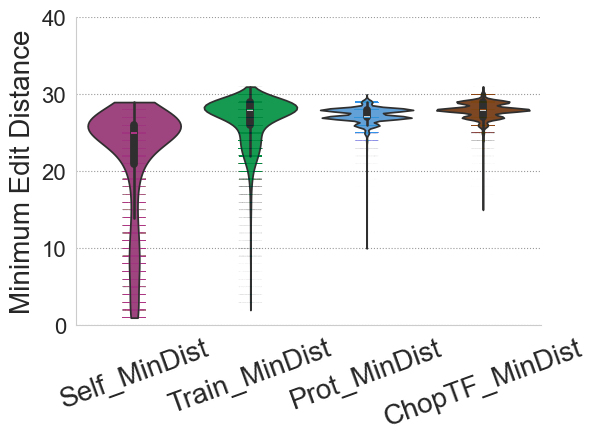

In [ ]:
plt.figure(figsize=(2.3,1.9))
sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})
ax = sns.violinplot(data=dist500k[['Self_MinDist', 'Train_MinDist', 'Prot_MinDist', 'ChopTF_MinDist']], cut=0, palette=['#ad3583', '#00b050', "#4ea2eb", "#8b4513"],bw_adjust=4)
ax = sns.stripplot(data=dist500k[['Self_MinDist', 'Train_MinDist', 'Prot_MinDist', 'ChopTF_MinDist']], palette=["#ad3583", "#018a3f", "#3192e7", "#8b4513"], s=0.6, alpha=0.001960788)
# The stripplot is 4 x 500,000 points. As vector paths that makes a ~16 MB PDF
# that Illustrator cannot open, so draw just those points as a raster layer.
# The violins, axes and text stay vector.
for _coll in ax.collections:
    if isinstance(_coll, mpl.collections.PathCollection):
        _coll.set_rasterized(True)

ax.tick_params(axis='y', labelsize=5)        # tick labels
ax.tick_params(axis='x',rotation=20,labelsize=5)
ax.set_ylabel(ax.get_ylabel(), fontsize=6.5)      # y label if present
ax.set_ylim(0,40)
ax.set_ylabel('Minimum Edit Distance')
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
plt.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

# plt.legend()
sns.despine()
plt.savefig(r"..\..\Figures_v5\ED1_500Keditdist.pdf", format='pdf', transparent=True, bbox_inches='tight', dpi=600)
plt.show()

In [12]:
state_size_map = preds.drop_duplicates(subset='AAseq').set_index('AAseq')['State Size']
dist500k['State Size'] = dist500k['AAseq'].map(state_size_map)

C:\Users\music\AppData\Local\Temp\ipykernel_42464\900160566.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=dist500k, x='State Size', y='Self_MinDist', cut=0, palette=palettehex)


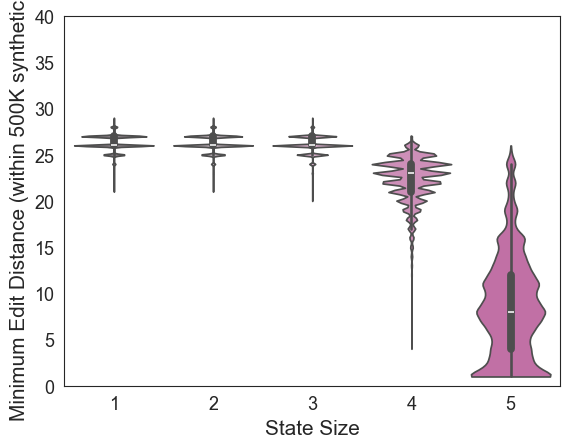

In [ ]:
plt.figure(figsize=(2.2,1.9))
sns.violinplot(data=dist500k, x='State Size', y='Self_MinDist', cut=0, palette=palettehex)
plt.xlabel('State Size', fontsize=6.5)
plt.ylabel('Minimum Edit Distance (within 500K synthetics)', fontsize=6.5)
plt.xticks(fontsize=5)
plt.yticks(fontsize=5)
plt.ylim(0,40)
plt.savefig(r"..\..\Figures_v5\ED1_500Keditdist_by_statesize.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

C:\Users\music\AppData\Local\Temp\ipykernel_45628\3557509527.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=syndist, x='State Size', y='MinDistance', cut=0, palette=palettehex)


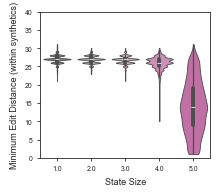

In [14]:
plt.figure(figsize=(2.2,1.9))
sns.violinplot(data=syndist, x='State Size', y='MinDistance', cut=0, palette=palettehex)
plt.xlabel('State Size', fontsize=6.5)
plt.ylabel('Minimum Edit Distance (within synthetics)', fontsize=6.5)
plt.xticks(fontsize=5)
plt.yticks(fontsize=5)
plt.ylim(0,40)
plt.savefig(r"..\..\Figures_v5\ED1_18750dist_by_statesize.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

### Figure 1b: Comp, PADDLE, TADA and ADhunterLite predictions on the 500,000 generated sequences

In [15]:
model_ss_horiz=3.6
model_ss_vert=0.68
sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})

1: #f0f1f1
2: #ebebed
3: #e5e6e8
4: #e0e1e4
5: #dadce0


C:\Users\music\AppData\Local\Temp\ipykernel_45628\3963557874.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=preds, x='State Size', y='Comp_original', errorbar=None, palette=("#e1e1e1", "#aaaaaa", "#848484", "#5B5B5B", "#1c1c1c"))


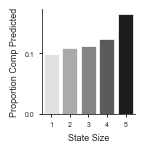

In [16]:
# create palette and print each color as a hex code
palette = sns.light_palette("#dadce0", n_colors=5)
for i, col in enumerate(palette, 1):
    print(f"{i}: {to_hex(col)}")

fig, ax = plt.subplots(figsize=(model_ss_horiz/3, model_ss_vert*2))
sns.barplot(data=preds, x='State Size', y='Comp_original', errorbar=None, palette=("#e1e1e1", "#aaaaaa", "#848484", "#5B5B5B", "#1c1c1c"))
plt.ylabel('Proportion Comp Predicted', fontsize=6.5)
plt.xlabel('State Size', fontsize=6.5)

# Remove the top and right spines (rectangle)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

ax.yaxis.set_major_locator(ticker.MultipleLocator(0.1))
ax.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

plt.xticks(fontsize=5)
plt.yticks(fontsize=5)
plt.savefig(r"..\..\Figures_v5\Fig1b_Comp.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

In [17]:
sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})

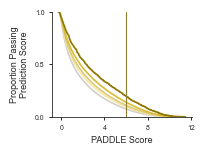

In [18]:
fig, ax = plt.subplots(figsize=(model_ss_horiz/2,model_ss_vert*2))
sns.ecdfplot(preds[preds['State Size'] == 1]['PADDLE_Score_original'], color = '#d2d0cb', linewidth=1.2, complementary=True)
sns.ecdfplot(preds[preds['State Size'] == 2]['PADDLE_Score_original'], color = "#f7e8a8", linewidth=1.2, complementary=True)
sns.ecdfplot(preds[preds['State Size'] == 3]['PADDLE_Score_original'], color = "#dbcb7b", linewidth=1.2, complementary=True)
sns.ecdfplot(preds[preds['State Size'] == 4]['PADDLE_Score_original'], color = "#d7bc36", linewidth=1.2, complementary=True)
sns.ecdfplot(preds[preds['State Size'] == 5]['PADDLE_Score_original'], color = "#8f7805", linewidth=1.2, complementary=True)
# plt.legend(title='State Size', labels=['1', '2', '3', '4', '5'], fontsize=5, loc='upper right', title_fontsize=6.5)

# Remove the top and right spines (rectangle)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(0.6)
ax.spines['bottom'].set_linewidth(0.6)

plt.xticks(fontsize=5)
plt.yticks(fontsize=5)
ax.yaxis.get_offset_text().set_fontsize(5)

ax.yaxis.set_major_locator(ticker.MultipleLocator(0.5))
ax.xaxis.set_major_locator(ticker.MultipleLocator(4))
plt.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

# plt.axvline(x=4,color='#9a9672', linewidth=0.8)
plt.axvline(x=6,color='#8d7f30', linewidth=0.8)


plt.xlabel('PADDLE Score', fontsize=6.5)
plt.ylabel('Proportion Passing\nPrediction Score', fontsize=6.5)
plt.savefig(r"..\..\Figures_v5\Fig1b_PADDLE_cdf.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

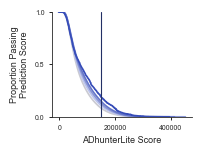

In [19]:
fig, ax = plt.subplots(figsize=(model_ss_horiz/2,model_ss_vert*2))
sns.ecdfplot(preds[preds['State Size'] == 1]['ADhunterLite_Score_original'], color = "#cacad2", linewidth=1.2, complementary=True)
sns.ecdfplot(preds[preds['State Size'] == 2]['ADhunterLite_Score_original'], color = "#bbc4ed", linewidth=1.2, complementary=True)
sns.ecdfplot(preds[preds['State Size'] == 3]['ADhunterLite_Score_original'], color = "#8b97d5", linewidth=1.2, complementary=True)
sns.ecdfplot(preds[preds['State Size'] == 4]['ADhunterLite_Score_original'], color = "#6475c9", linewidth=1.2, complementary=True)
sns.ecdfplot(preds[preds['State Size'] == 5]['ADhunterLite_Score_original'], color = "#364cb8", linewidth=1.2, complementary=True)

# Remove the top and right spines (rectangle)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(0.6)
ax.spines['bottom'].set_linewidth(0.6)

# plt.legend(title='State Size', labels=['1', '2', '3', '4', '5'], fontsize=5, loc='upper right', title_fontsize=6.5)
plt.xlabel('ADhunterLite Score', fontsize=6.5)
plt.ylabel('Proportion Passing\nPrediction Score', fontsize=6.5)
plt.xticks(fontsize=5)
plt.yticks(fontsize=5)
ax.yaxis.set_major_locator(ticker.MultipleLocator(0.5))
ax.xaxis.set_major_locator(ticker.MultipleLocator(200000))

plt.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

# plt.axvline(x=100000,color='#6e7b9a', linewidth=0.8)
plt.axvline(x=150000,color='#233065', linewidth=0.8)

ax.yaxis.get_offset_text().set_fontsize(5)
sns.despine()
# plt.xlim(right=300000)
plt.savefig(r"..\..\Figures_v5\Fig1b_ADh_cdf.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

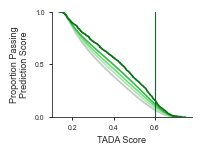

In [20]:
fig, ax = plt.subplots(figsize=(model_ss_horiz/2,model_ss_vert*2))
sns.ecdfplot(preds[preds['State Size'] == 1]['TADA_Score_original'], color = '#c1c9c2', linewidth=1.2, complementary=True)
sns.ecdfplot(preds[preds['State Size'] == 2]['TADA_Score_original'], color = "#aae8b1", linewidth=1.2, complementary=True)
sns.ecdfplot(preds[preds['State Size'] == 3]['TADA_Score_original'], color = "#71de7d", linewidth=1.2, complementary=True)
sns.ecdfplot(preds[preds['State Size'] == 4]['TADA_Score_original'], color = "#3bb649", linewidth=1.2, complementary=True)
sns.ecdfplot(preds[preds['State Size'] == 5]['TADA_Score_original'], color = "#0c7117", linewidth=1.2, complementary=True)
# plt.legend(title='State Size', labels=['1', '2', '3', '4', '5'], fontsize=5, loc='upper right', title_fontsize=6.5)
plt.xlabel('TADA Score', fontsize=6.5)
plt.ylabel('Proportion Passing\nPrediction Score', fontsize=6.5)

# Remove the top and right spines (rectangle)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_linewidth(0.6)
ax.spines['bottom'].set_linewidth(0.6)

ax.yaxis.set_major_locator(ticker.MultipleLocator(0.5))
ax.xaxis.set_major_locator(ticker.MultipleLocator(0.2))

plt.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

# plt.axvline(x=0.4,color='#8dbb91', linewidth=0.8)
plt.axvline(x=0.6,color='#176031', linewidth=0.8)

plt.xticks(fontsize=5)
plt.yticks(fontsize=5)
ax.yaxis.get_offset_text().set_fontsize(5)
plt.savefig(r"..\..\Figures_v5\Fig1b_TADA_cdf.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()


### ED1 d-e: Increasing state size has minor contributions to composition of key residues

In [23]:
seqfeats[seqfeats['AAseq'].isin(expseqs['AAseq'])].drop_duplicates(subset='AAseq').shape

(18750, 31)

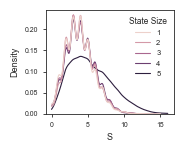

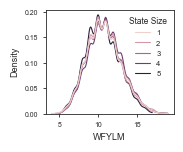

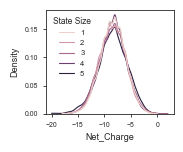

c:\Users\music\miniforge3\envs\multi\Lib\site-packages\seaborn\distributions.py:1176: UserWarning: The following kwargs were not used by contour: 'linewidth'
  cset = contour_func(


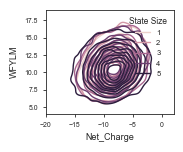

In [24]:
var='S'
plt.figure(figsize=(1.65,1.35))
sns.kdeplot(seqfeats[seqfeats['AAseq'].isin(expseqs['AAseq'])].drop_duplicates(subset='AAseq'),x=var,hue='State Size',color='#F0B2E0',cut=0,common_norm=False,linewidth=0.8)
plt.savefig(r"..\..\Figures_v5\ED1_18750_S_statesize.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
var='WFYLM'
plt.figure(figsize=(1.65,1.35))
sns.kdeplot(seqfeats[seqfeats['AAseq'].isin(expseqs['AAseq'])].drop_duplicates(subset='AAseq'),x=var,hue='State Size',color='#F0B2E0',cut=0,common_norm=False,linewidth=0.8)
plt.savefig(r"..\..\Figures_v5\ED1_18750_WFYLM_statesize.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
var='Net_Charge'
plt.figure(figsize=(1.65,1.35))
sns.kdeplot(seqfeats[seqfeats['AAseq'].isin(expseqs['AAseq'])].drop_duplicates(subset='AAseq'),x=var,hue='State Size',color='#F0B2E0',cut=0,common_norm=False,linewidth=0.8)
plt.savefig(r"..\..\Figures_v5\ED1_18750_Net_Charge_statesize.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
plt.figure(figsize=(1.65,1.35))
sns.kdeplot(seqfeats[seqfeats['AAseq'].isin(expseqs['AAseq'])].drop_duplicates(subset='AAseq'),x='Net_Charge',y='WFYLM',hue='State Size',color='#F0B2E0',cut=0,common_norm=False,linewidth=0.8)
plt.savefig(r"..\..\Figures_v5\ED1_18750_WFYLM_netcharge_statesize.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

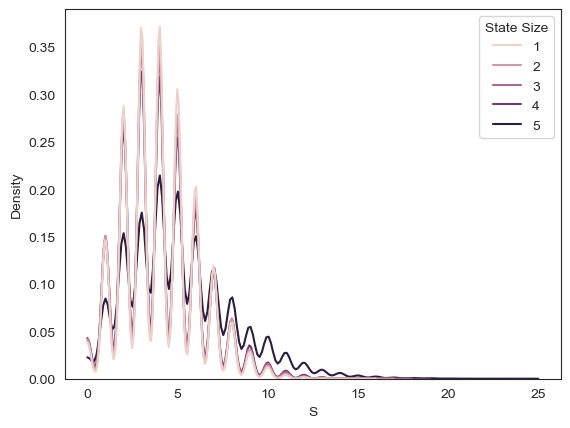

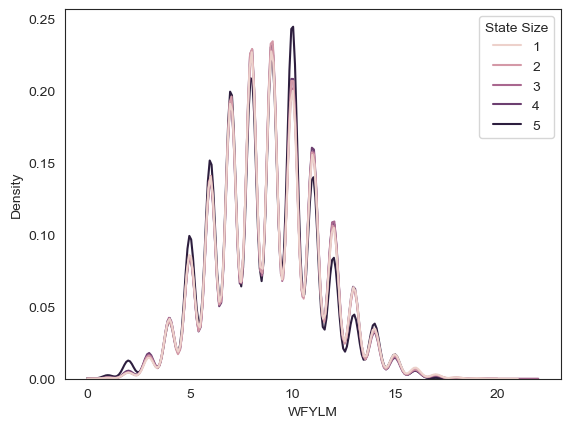

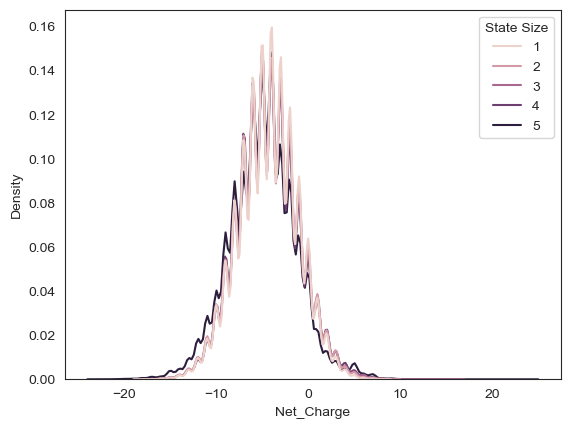

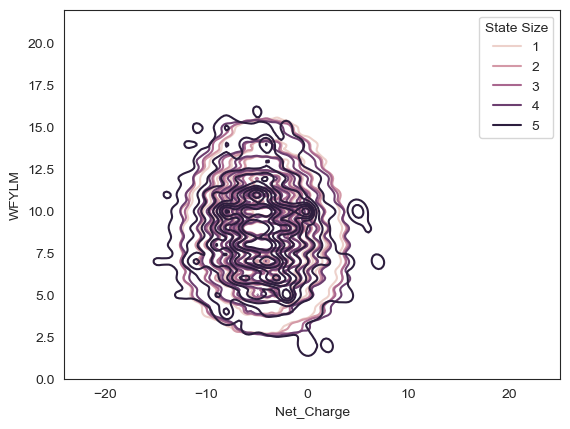

In [ ]:
var='S'
plt.figure(figsize=(1.65,1.35))
sns.kdeplot(seqfeats,x=var,hue='State Size',color='#F0B2E0',cut=0,common_norm=False,linewidth=0.8)
plt.savefig(r"..\..\Figures_v5\ED1_500k_S_statesize.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
var='WFYLM'
plt.figure(figsize=(1.65,1.35))
sns.kdeplot(seqfeats,x=var,hue='State Size',color='#F0B2E0',cut=0,common_norm=False,linewidth=0.8)
plt.savefig(r"..\..\Figures_v5\ED1_500k_WFYLM_statesize.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
var='Net_Charge'
plt.figure(figsize=(1.65,1.35))
sns.kdeplot(seqfeats,x=var,hue='State Size',color='#F0B2E0',cut=0,common_norm=False,linewidth=0.8)
plt.savefig(r"..\..\Figures_v5\ED1_500k_Net_Charge_statesize.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
plt.figure(figsize=(1.65,1.35))
sns.kdeplot(seqfeats,x='Net_Charge',y='WFYLM',hue='State Size',color='#F0B2E0',cut=0,common_norm=False,linewidth=0.8)
plt.savefig(r"..\..\Figures_v5\ED1_500k_WFYLM_netcharge_statesize.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

### ED2: NN AD predictors recognize AD grammar

#### ED2a: Sanborn 2021

In [25]:
san_preds_adhe.rename(columns={'adhunter_ensemble_preds':'ADhunterEnsemble_Score'},inplace=True)
san_preds_adhe = san_preds_adhe[['sequence','name','ADhunterEnsemble_Score']].copy()
san_preds_adh.rename(columns={'adhunter_preds':'ADhunter_Score'},inplace=True)
san_preds_adh = san_preds_adh[['sequence','name','ADhunter_Score']].copy()
san_preds_adp.rename(columns={'adpred_preds':'ADPred_Score'},inplace=True)
san_preds_adp = san_preds_adp[['sequence','name','ADPred_Score']].copy()
san_preds_pad.rename(columns={'paddle_preds':'PADDLE_Score'},inplace=True)
san_preds_pad = san_preds_pad[['sequence','name','PADDLE_Score']].copy()
san_preds_tada.rename(columns={'tada_preds':'TADA_Score'},inplace=True)
san_preds_tada = san_preds_tada[['sequence','name','TADA_Score']].copy()

In [26]:
san_shuf = san_mut[san_mut["Unnamed: 0"].str.contains("Scramble", na=False)]
# Get the text between "_" and "mut" from each san_shuf entry
keys = (
    san_shuf["Unnamed: 0"]
    .str.extract(r"_([^_]*?)mut", expand=False)
    .dropna()
    .unique()
)
print(keys)
san_shuf["AD"] = san_shuf["Unnamed: 0"].str.extract(r"_([^_]*?)mut", expand=False)

gal4_seq = 'DGNNSKPLSPGWTDQTAYNAFGITTGMFNTTTMDDVYNYLFDDEDTPPNPKKE'
gcn4_seq = 'TVLPIPELDDAVVESFFSSSTDSTPMFEYENLEDNSKEWTSLFDNDIPVTTDD'
hap4_seq = 'DETYLFLQDQDESADSHHHDELGSEITLADNKFSYLPPTLEELMEEQDCNNGR'
met4_seq = 'VTNRGNTNLYDHAVTPEILLEQLAYVDNFIPSLDNEFSNVDWNVNTTHNNANN'
pdr1_seq = 'NNNNKNNINNINNNNSNNFSATSFNLGTLDEFVNNGDLEDLYSILWSDVYPDS'
pho4_seq = 'SSENGNENENEQDSLALDDLDRAFELVEGMDMDWMMPSHAHHSPATTATIKPR'
rap1_seq = 'SYAIPENELLDEDTMNFISSLKNDLSNISNSLPFEYPHEIAEAIRSDFSNEDI'
war1_seq = 'NDVTNSADSTNIKPSPSSSVDNLNDYLTDINSLAWGVNSLNDEFWTDLFMNDI'

tile_list = [gal4_seq, gcn4_seq, hap4_seq, met4_seq, pdr1_seq, pho4_seq, rap1_seq, war1_seq]

san_tile = san_mut[san_mut["protein sequence"].isin(tile_list)]

# Longest keys first, so a short key that's part of a longer one doesn't match first
keys_sorted = sorted(keys, key=len, reverse=True)
pattern = "(" + "|".join(map(re.escape, keys_sorted)) + ")"

san_tile["AD"] = san_tile["Unnamed: 0"].str.extract(pattern, expand=False)

san_tile['Shuffle'] = False
san_shuf['Shuffle'] = True
san = pd.concat([san_tile, san_shuf], ignore_index=True)

['Gal4' 'Gcn4' 'Hap4' 'Met4' 'Pdr1' 'Pho4' 'Rap1' 'War1']


C:\Users\music\AppData\Local\Temp\ipykernel_45628\3882631801.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  san_shuf["AD"] = san_shuf["Unnamed: 0"].str.extract(r"_([^_]*?)mut", expand=False)
C:\Users\music\AppData\Local\Temp\ipykernel_45628\3882631801.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  san_tile["AD"] = san_tile["Unnamed: 0"].str.extract(pattern, expand=False)
C:\Users\music\AppData\Local\Temp\ipykernel_45628\3882631801.py:31: SettingWithCopyWarning: 
A value is trying to be set on a 

In [27]:
num_re = re.compile(r"[-+]?(?:\d+\.?\d*|\.\d+)(?:[eE][-+]?\d+)?")

def parse_scores(x):
    """Turn '[0.1, 0.2]' / '[0.1 0.2]' / '0.3' / 0.3 into a list of floats."""
    if isinstance(x, (int, float, np.floating)):
        return [] if pd.isna(x) else [float(x)]
    return [float(v) for v in num_re.findall(str(x))]

# The Sanborn sequences are 53-mers. ADhunter, TADA and ADPred take shorter
# inputs, so they return one score per window; a sequence's score is the mean
# across windows.
for df, col in [(san_preds_adh, "ADhunter_Score"),
                (san_preds_tada, "TADA_Score"),
                (san_preds_adp, "ADPred_Score")]:
    vals = df[col].apply(parse_scores)
    df[col] = vals.apply(lambda v: np.mean(v) if v else np.nan)

# PADDLE and ADhunterEnsemble take 53-mers natively, so one score per sequence;
# parse_scores just strips the brackets.
for df, col in [(san_preds_adhe, "ADhunterEnsemble_Score"),
                (san_preds_pad, "PADDLE_Score")]:
    vals = df[col].apply(parse_scores)
    df[col] = vals.apply(lambda v: v[0] if v else np.nan)

In [28]:
dfs = [san_preds_adhe, san_preds_adh, san_preds_adp, san_preds_pad, san_preds_tada]

san_preds = reduce(
    lambda left, right: pd.merge(left, right, on=["sequence", "name"], how="outer", validate="one_to_one"),
    dfs,
)

print(len(san_preds), [len(d) for d in dfs])

72 [72, 72, 72, 72, 72]


In [29]:
lookup = san.drop_duplicates("Unnamed: 0").set_index("Unnamed: 0")[["AD", "Shuffle"]]
for col in ["AD", "Shuffle"]:
    san_preds[col] = san_preds["name"].map(lookup[col])

activity_lookup = san_mut.groupby("protein sequence")["Z score"].mean()
san_preds["Activity"] = san_preds["sequence"].map(activity_lookup)

print(san_preds["Activity"].notna().sum(), "of", len(san_preds), "rows matched")

72 of 72 rows matched


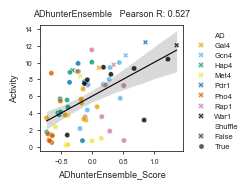

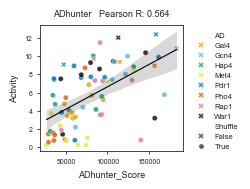

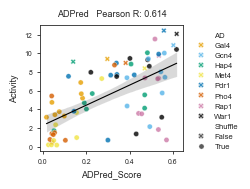

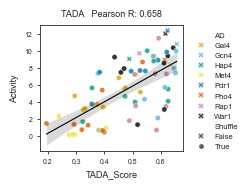

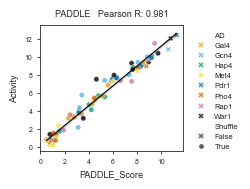

In [34]:
okabe_ito = ['#E69F00', '#56B4E9', '#009E73', '#F0E442',
             '#0072B2', '#D55E00', '#CC79A7', '#000000']
ads = sorted(san_preds['AD'].dropna().unique())
palette = dict(zip(ads, okabe_ito))

for model in ["ADhunterEnsemble_Score", "ADhunter_Score", "ADPred_Score", "TADA_Score","PADDLE_Score"]:
    d = san_preds.dropna(subset=[model, 'Activity'])
    r, p = stats.pearsonr(d[model], d['Activity'])

    fig, ax = plt.subplots(figsize=(2.5, 1.875))
    sns.scatterplot(data=san_preds, x=model, y='Activity',
                    hue='AD', palette=palette, hue_order=ads,
                    style='Shuffle', markers={True: 'o', False: 'X'},
                    alpha=0.8, s=14, ax=ax)
    # line + shaded 95% CI from 1000 bootstraps, same as the Staller panels
    sns.regplot(data=d, x=model, y='Activity', ax=ax,
                scatter=False, n_boot=1000, ci=95,
                line_kws={'color': 'black', 'linewidth': 0.8})

    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
    ax.set_title(f"{model.replace('_Score', '')}   Pearson R: {r:.3f}")
    plt.tight_layout()
    plt.savefig(rf"..\..\Figures_v5\ED2_sanborn_{model}_activity_scatter.pdf",
                format='pdf', bbox_inches='tight', transparent=True)
    plt.show()

In [35]:
# ==========================================================================
#  Pearson correlation within each AD's shuffle set, per model
# ==========================================================================
# san_preds has ADhunter_Score, not the ADhunterLite_Score that `models` lists
san_models = ["ADhunterEnsemble_Score", "ADhunter_Score", "ADPred_Score",
              "TADA_Score", "PADDLE_Score"]

rows = []
for model in san_models:                      # <-- was: for model in models:
    sub = san_preds.dropna(subset=[model, "Activity", "AD"])
    for ad, grp in sub.groupby("AD"):
        if len(grp) > 2:
            r, p = stats.pearsonr(grp[model], grp["Activity"])
            rows.append({"Model": model.replace("_Score", ""), "AD": ad,
                         "n": len(grp), "r": r, "p": p})

san_shuffle_r = pd.DataFrame(rows)

for model, sub in san_shuffle_r.groupby("Model", sort=False):
    print(f"\n{model}")
    print(sub[["AD", "n", "r", "p"]].round(3).to_string(index=False))

# compact view: one row per AD, one column per model
print("\nPearson r, all models")
print(san_shuffle_r.pivot(index="AD", columns="Model", values="r")
      .reindex(columns=[m.replace("_Score", "") for m in san_models])
      .round(2).to_string())


ADhunterEnsemble
  AD  n      r     p
Gal4  9  0.529 0.143
Gcn4  9  0.770 0.015
Hap4  9  0.882 0.002
Met4  9  0.329 0.387
Pdr1  9  0.584 0.099
Pho4  9  0.700 0.036
Rap1  9 -0.239 0.536
War1  9  0.558 0.119

ADhunter
  AD  n      r     p
Gal4  9  0.846 0.004
Gcn4  9  0.531 0.141
Hap4  9  0.486 0.184
Met4  9  0.707 0.033
Pdr1  9  0.657 0.055
Pho4  9  0.813 0.008
Rap1  9 -0.058 0.883
War1  9  0.219 0.571

ADPred
  AD  n     r     p
Gal4  9 0.902 0.001
Gcn4  9 0.476 0.195
Hap4  9 0.431 0.247
Met4  9 0.921 0.000
Pdr1  9 0.622 0.074
Pho4  9 0.877 0.002
Rap1  9 0.020 0.960
War1  9 0.231 0.550

TADA
  AD  n     r     p
Gal4  9 0.793 0.011
Gcn4  9 0.253 0.511
Hap4  9 0.381 0.312
Met4  9 0.850 0.004
Pdr1  9 0.832 0.005
Pho4  9 0.805 0.009
Rap1  9 0.150 0.699
War1  9 0.204 0.599

PADDLE
  AD  n     r   p
Gal4  9 0.992 0.0
Gcn4  9 0.937 0.0
Hap4  9 0.992 0.0
Met4  9 0.974 0.0
Pdr1  9 0.989 0.0
Pho4  9 0.993 0.0
Rap1  9 0.982 0.0
War1  9 0.960 0.0

Pearson r, all models
Model  ADhunterEnsemble  AD

#### ED2b: Staller 2018

In [36]:
sta = sta[sta['MutationClass'] == 'Kappa'] # only keep shuffles
# keep set used in paper
sta = sta[sta['HighStringencySet'] == True]
print(sta['VeryHighStringencySet'].sum())

sta_preds_adhe.rename(columns={'adhunter_ensemble_preds':'ADhunterEnsemble_Score'},inplace=True)
sta_preds_adhe = sta_preds_adhe[['sequence','name','ADhunterEnsemble_Score']].copy()
sta_preds_adhe['name'] = sta_preds_adhe['name'].str.replace('53_', '', regex=False)
sta_preds_adhe['sequence'] = sta_preds_adhe['sequence'].str.replace('TAGSTSSAS', '', regex=False)
sta_preds_adh.rename(columns={'adhunter_preds':'ADhunter_Score'},inplace=True)
sta_preds_adh = sta_preds_adh[['sequence','name','ADhunter_Score']].copy()
sta_preds_adp.rename(columns={'adpred_preds':'ADPred_Score'},inplace=True)
sta_preds_adp = sta_preds_adp[['sequence','name','ADPred_Score']].copy()
sta_preds_pad.rename(columns={'paddle_preds':'PADDLE_Score'},inplace=True)
sta_preds_pad = sta_preds_pad[['sequence','name','PADDLE_Score']].copy()
sta_preds_pad['name'] = sta_preds_pad['name'].str.replace('53_', '', regex=False)
sta_preds_pad['sequence'] = sta_preds_pad['sequence'].str.replace('TAGSTSSAS', '', regex=False)
sta_preds_tada.rename(columns={'tada_preds':'TADA_Score'},inplace=True)
sta_preds_tada = sta_preds_tada[['sequence','name','TADA_Score']].copy()

461


In [37]:
# Multi-value models: average -> _Score, max -> _Score_Max
for df, col in [(sta_preds_adh, "ADhunter_Score"),
                (sta_preds_tada, "TADA_Score"),
                (sta_preds_adp, "ADPred_Score")]:
    vals = df[col].apply(parse_scores)
    df[col] = vals.apply(lambda v: np.mean(v) if v else np.nan)
    df[col + "_Max"] = vals.apply(lambda v: max(v) if v else np.nan)

# Single-value models: strip brackets and convert to float
for df, col in [
    (sta_preds_adhe, "ADhunterEnsemble_Score"),
                (sta_preds_pad, "PADDLE_Score")]:
    vals = df[col].apply(parse_scores)
    df[col] = vals.apply(lambda v: v[0] if v else np.nan)

dfs = [
    sta_preds_adhe, 
    sta_preds_adh, sta_preds_adp,sta_preds_pad, sta_preds_tada]
for d in dfs:
    d["name"] = d["name"].astype(str).str.strip()

sta_preds = reduce(
    lambda left, right: pd.merge(left, right, on=["sequence", "name"], how="outer", validate="one_to_one"),
    dfs,
)

print(len(sta_preds), [len(d) for d in dfs])

584 [584, 584, 584, 584, 584]


In [38]:
activity_lookup = sta.groupby("ActivationDomainSeq")["ActivityCompleteMediaReplicate1_Normalized"].mean()
 
sta_preds["Activity"] = sta_preds["sequence"].map(activity_lookup)

print(sta_preds["Activity"].notna().sum(), "of", len(sta_preds), "rows matched")

584 of 584 rows matched


In [39]:
def plot_and_calculate(df, x_col, y_col,filename=None,alpha=0.1,figsize=(2.2, 2.2),s=2,rasterize=False):
    # Calculate Pearson correlation coefficient and p-value
    r, p_value = stats.pearsonr(df[x_col], df[y_col])
    
    # Calculate R-squared using linear regression
    slope, intercept, r_value, p_value_reg, std_err = stats.linregress(df[x_col], df[y_col])
    
    # Set up the plot with the specified figure size
    fig, ax = plt.subplots(figsize=figsize)
    
    # Generate scatterplot with a line of best fit using regplot
    # scatter_kws applies the specific styling from your scatterplot example
    sns.regplot(
        data=df, 
        x=x_col, 
        y=y_col, 
        ax=ax,
        scatter_kws={"color": "#B66DA4", "alpha": alpha, "s": s, "rasterized": rasterize},
        line_kws={"color": "black", "linewidth": 0.8} # Set line color to contrast with the scatter points
    )
    
    # Apply the requested tick parameters
    ax.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
    
    # Apply the MultipleLocator for the x-axis
    # ax.xaxis.set_major_locator(MultipleLocator(2))
    
    # Set dynamic x and y labels with specified font sizes
    ax.set_xlabel(x_col, fontsize=6.5)
    ax.set_ylabel(y_col, fontsize=6.5)

    x_2_pct_range = (df[x_col].max()-df[x_col].min())*0.02
    y_2_pct_range = (df[y_col].max()-df[y_col].min())*0.02
    ax.set_xlim(df[x_col].min()-x_2_pct_range,df[x_col].max()+x_2_pct_range)
    ax.set_ylim(df[y_col].min()-y_2_pct_range,df[y_col].max()+y_2_pct_range)
    
    # Annotate the plot with the calculated coefficients
    plt.title(f"Pearson R: {r:.3f}")
    
    # Remove top and right spines
    sns.despine()
    
    if filename:
        plt.savefig(fr"{filename}", format='pdf', transparent=True, bbox_inches='tight', dpi=600)
    return r

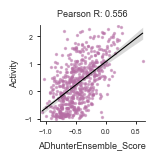

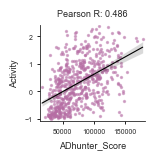

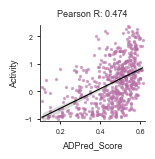

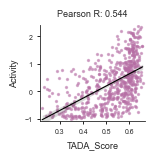

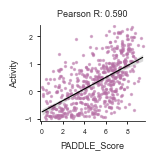

In [40]:
for model in ["ADhunterEnsemble_Score", "ADhunter_Score", "ADPred_Score", "TADA_Score","PADDLE_Score"]:
    plot_and_calculate(sta_preds, model, 'Activity',alpha=0.5,figsize=(1.35, 1.25),filename=rf"..\..\Figures_v5\ED2_staller2018_{model}_activity_scatter.pdf")

#### ED2c: The candidate designed ADs have grammar that is recognized by NN AD predictors

In [41]:
shuf500k_adhe["adhe_preds"] = pd.to_numeric(shuf500k_adhe["adhunter_ensemble_preds"].str.strip("[]"), errors="coerce")
shuf500k_adhe = shuf500k_adhe[['sequence', 'adhe_preds','name']]
shuf500k_adhe['sequence'] = shuf500k_adhe['sequence'].str.replace('SHLATAGSTSSAS', '', regex=False)
shuf500k_tada["tada_preds"]   = pd.to_numeric(shuf500k_tada["tada_preds"].str.strip("[]"), errors="coerce")
shuf500k_adp["adpred_preds"] = shuf500k_adp["adpred_preds"].apply(lambda x: [float(i) for i in x.strip("[]").split(",")])
shuf500k_adp["adpred_ave"] = shuf500k_adp["adpred_preds"].apply(lambda x: sum(x) / len(x))
shuf500k_adp["adpred_max"] = shuf500k_adp["adpred_preds"].apply(max)
shuf500k_pad["paddle_preds"]   = pd.to_numeric(shuf500k_pad["paddle_preds"].str.strip("[]"), errors="coerce")
shuf500k_pad['sequence'] = shuf500k_pad['sequence'].str.replace('SHLATAGSTSSAS', '', regex=False)
shuf500k_adh["adhunter_preds"]   = pd.to_numeric(shuf500k_adh["adhunter_preds"].str.strip("[]"), errors="coerce")

def add_state(df):
    key = df['name'].astype(str).str.replace(r'_53$', '', regex=True).astype(preds.index.dtype)
    return (df.drop(columns=['AAseq', 'Original_AAseq', 'State Size'], errors='ignore')
              .assign(key=key)
              .merge((preds.loc[~preds.index.duplicated(keep='first'), ['AAseq', 'State Size']].rename(columns={'AAseq': 'Original_AAseq'})), 
              left_on='key', right_index=True, how='left', validate='m:1')
              .drop(columns='key'))

shuf500k_adhe = add_state(shuf500k_adhe)
shuf500k_tada = add_state(shuf500k_tada)
shuf500k_adp  = add_state(shuf500k_adp)
shuf500k_pad  = add_state(shuf500k_pad)
shuf500k_adh  = add_state(shuf500k_adh)

# Sanity check: a shuffle should have the same amino-acid composition as its original
comp = lambda s: ''.join(sorted(s)) if isinstance(s, str) else None
for name, df in [('adhe', shuf500k_adhe), ('tada', shuf500k_tada), ('adp', shuf500k_adp),
                 ('pad', shuf500k_pad), ('adh', shuf500k_adh)]:
    same = df['sequence'].map(comp) == df['Original_AAseq'].map(comp)
    print(name, len(df), 'unmatched:', df['Original_AAseq'].isna().sum(), 'composition match:', same.mean())

adhe 500000 unmatched: 0 composition match: 1.0
tada 500000 unmatched: 0 composition match: 1.0
adp 500000 unmatched: 0 composition match: 1.0
pad 500000 unmatched: 0 composition match: 1.0
adh 500000 unmatched: 0 composition match: 1.0


In [42]:
shuf500k_adhe['ADhunterEnsemble'] = shuf500k_adhe['adhe_preds'] > 0.4441

shuf500k_tada['TADA'] = (shuf500k_tada['tada_preds'] > 0.4).astype(int)

def adpred_classify(preds):
    """1 if there are >= 10 consecutive values >= 0.8, else 0."""
    run = 0
    for p in preds:
        run = run + 1 if p >= 0.8 else 0
        if run >= 10:
            return 1
    return 0
shuf500k_adp["ADPred"] = shuf500k_adp["adpred_preds"].apply(adpred_classify)

shuf500k_pad['PADDLE'] = shuf500k_pad['paddle_preds'] > 4

shuf500k_adh['ADhunter'] = shuf500k_adh['adhunter_preds'] > 100000

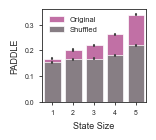

In [43]:
plt.figure(figsize=(1.35,1.2))
sns.barplot(preds,x='State Size',y='PADDLE',label='Original',color='#cf62a9')
sns.barplot(shuf500k_pad,x='State Size',y='PADDLE',label='Shuffled',color='#887d84ac')
plt.savefig(r"..\..\Figures_v5\ED2_500k_shuf_PADDLE.pdf", format='pdf', transparent=True, bbox_inches='tight')

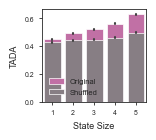

In [44]:
plt.figure(figsize=(1.35,1.2))
sns.barplot(preds,x='State Size',y='TADA',label='Original',color='#cf62a9')
sns.barplot(shuf500k_tada,x='State Size',y='TADA',label='Shuffled',color='#887d84ac')
plt.savefig(r"..\..\Figures_v5\ED2_500k_shuf_TADA.pdf", format='pdf', transparent=True, bbox_inches='tight')

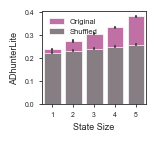

In [45]:
plt.figure(figsize=(1.35,1.2))
sns.barplot(preds,x='State Size',y='ADhunterLite',label='Original',color='#cf62a9')
sns.barplot(shuf500k_adh,x='State Size',y='ADhunter',label='Shuffled',color='#887d84ac')
plt.savefig(r"..\..\Figures_v5\ED2_500k_shuf_ADhunterLite.pdf", format='pdf', transparent=True, bbox_inches='tight')

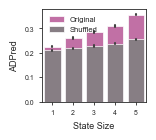

In [46]:
plt.figure(figsize=(1.35,1.2))
sns.barplot(preds,x='State Size',y='ADPred',label='Original',color='#cf62a9')
sns.barplot(shuf500k_adp,x='State Size',y='ADPred',label='Shuffled',color='#887d84ac')
plt.savefig(r"..\..\Figures_v5\ED2_500k_shuf_ADPred.pdf", format='pdf', transparent=True, bbox_inches='tight')

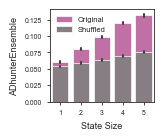

In [47]:
plt.figure(figsize=(1.35,1.2))
sns.barplot(preds,x='State Size',y='ADhunterEnsemble',label='Original',color='#cf62a9')
sns.barplot(shuf500k_adhe,x='State Size',y='ADhunterEnsemble',label='Shuffled',color='#887d84ac')
plt.savefig(r"..\..\Figures_v5\ED2_500k_shuf_ADhunterEnsemble.pdf", format='pdf', transparent=True, bbox_inches='tight')

In [48]:
def merge_preds(shuf):
    m = (shuf.rename(columns=lambda c: c if c == 'Original_AAseq' else f'{c}_shuffle')
             .merge(preds.drop_duplicates(subset='AAseq', keep='first'), left_on='Original_AAseq', right_on='AAseq',
                    how='left', validate='m:1'))
    print(len(m), len(shuf), m['AAseq'].isna().sum())
    return m

merge_adhe   = merge_preds(shuf500k_adhe)
merge_tada   = merge_preds(shuf500k_tada)
merge_adp    = merge_preds(shuf500k_adp)
merge_paddle = merge_preds(shuf500k_pad)
merge_adh    = merge_preds(shuf500k_adh)

500000 500000 0
500000 500000 0
500000 500000 0
500000 500000 0
500000 500000 0


### Figure 1c: Minimum edit distance of the 18,750 experimental sequences

To themselves (Designed), the training data, and the budding yeast proteome.

In [49]:
traindist_exp.rename(columns={'min_edit_dist': 'Train_MinDist'}, inplace=True)
protdist_exp.rename(columns={'min_edit_dist': 'Prot_MinDist'}, inplace=True)
merged_dists = pd.merge(traindist_exp[['AAseq', 'Train_MinDist']], protdist_exp[['AAseq', 'Prot_MinDist']], on='AAseq')
merged_dists = pd.merge(merged_dists, syndist[['AAseq', 'MinDistance']], left_on='AAseq', right_on='AAseq')
merged_dists.rename(columns={'MinDistance': 'Synth_MinDist'}, inplace=True)
plotting = merged_dists.rename(columns={'Train_MinDist': 'Training', 'Prot_MinDist': 'Proteome', 'Synth_MinDist': 'Synthetics'})

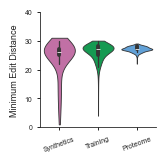

In [50]:
plt.figure(figsize=(1.5,1.5))
sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})
ax = sns.violinplot(data=plotting[['Synthetics', 'Training', 'Proteome']], cut=0, palette=['#cf62a9', '#00b050', "#4ea2eb"],bw_adjust=4)
ax.tick_params(axis='y', labelsize=5)        # tick labels
ax.tick_params(axis='x',rotation=20,labelsize=5)
ax.set_ylabel(ax.get_ylabel(), fontsize=6.5)      # y label if present
ax.set_ylim(0,40)
ax.set_ylabel('Minimum Edit Distance')
ax.yaxis.set_major_locator(ticker.MultipleLocator(10))
ax.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

# plt.legend()
sns.despine()
plt.savefig(r"..\..\Figures_v5\Fig1c_editdistance.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

### ED3 a: Correlations of AD predictor scores

In [51]:
model_ss_horiz=2.55
model_ss_vert=0.68
sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})

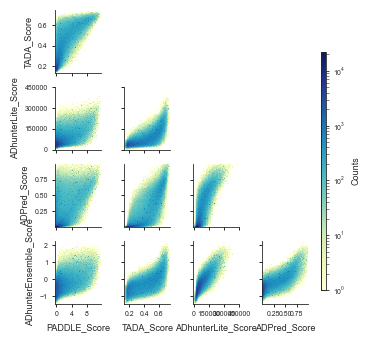

In [52]:
models = ['PADDLE_Score', 'TADA_Score','ADhunterLite_Score','ADPred_Score','ADhunterEnsemble_Score']
n = len(models)
pairs = list(itertools.combinations(range(n), 2))   # (j, i): x = models[j], y = models[i]

sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})
font = 6.5
bins = 64
panel = model_ss_horiz / 3            # same per-panel width as the 1x3 version
cmap = 'YlGnBu'

# Optional fixed tick spacing per model (like the original); anything not listed gets MaxNLocator
tick_spacing = {
    'TADA': 0.2,
    'ADhunterLite': 2e5,
    'PADDLE': 4,
    'ADhunterEnsemble': 1,
    'ADPred': 0.25
}

def set_locator(axis, model):
    if model in tick_spacing:
        axis.set_major_locator(ticker.MultipleLocator(tick_spacing[model]))
    else:
        axis.set_major_locator(ticker.MaxNLocator(4))

# --- Global vmin/vmax across all pairs for a shared LogNorm ---
hists = {}
for j, i in pairs:
    d = preds[[models[j], models[i]]]
    h, xe, ye = np.histogram2d(d[models[j]], d[models[i]], bins=bins)
    hists[(j, i)] = (h, xe, ye)

all_h = np.concatenate([h.ravel() for h, _, _ in hists.values()])
vmin = all_h[all_h > 0].min()
vmax = all_h.max()
norm = mcolors.LogNorm(vmin=vmin, vmax=vmax)

# --- Corner grid: rows = y model (models[1:]), cols = x model (models[:-1]) ---
fig, axes = plt.subplots(n - 1, n - 1, figsize=(panel * (n - 1), panel * (n - 1)),
                         sharex='col', sharey='row', squeeze=False)

for r in range(n - 1):
    for c in range(n - 1):
        ax = axes[r, c]
        i, j = r + 1, c                   # y model, x model
        if j >= i:
            ax.set_visible(False)
            continue

        d = preds[[models[j], models[i]]].dropna()
        im = ax.hist2d(d[models[j]], d[models[i]], bins=bins, cmap=cmap, norm=norm)

        set_locator(ax.xaxis, models[j])
        set_locator(ax.yaxis, models[i])
        ax.tick_params(axis='both', which='major', length=2, width=0.6, color='black',
                       bottom=True, left=True, labelsize=5)

        if r == n - 2:
            ax.set_xlabel(models[j], fontsize=font)
        if c == 0:
            ax.set_ylabel(models[i], fontsize=font)

plt.tight_layout(rect=[0, 0, 0.93, 1])

cbar_ax = fig.add_axes([0.94, 0.15, 0.015, 0.7])
fig.colorbar(plt.cm.ScalarMappable(norm=norm, cmap=cmap), cax=cbar_ax, label='Counts')

sns.despine()

plt.savefig(r"..\..\Figures_v5\ED3_predictor_correlations.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

## Figure 2. High-throughput experimental validation of designed activation domains in yeast

### ED4 a-b: Barcode and sort reproducibility

In [53]:
def _coerce_ax(ax: Optional[plt.Axes] = None, figsize: Tuple[float, float] = (2.2, 1.7)) -> plt.Axes:
    """Return existing axes or create new one."""
    if ax is not None:
        return ax
    fig, new_ax = plt.subplots(figsize=figsize)
    return new_ax
def plot_scatter_regression(
    df: pd.DataFrame,
    x_col: str,
    y_col: str,
    *,
    show_stats: bool = True,
    color: str = "#1f77b4",
    line_color: str = "#d62728",
    line_width: float = 0.8,
    line_alpha: float = 0.8,
    alpha: float = 0.5,
    s: float = 3,
    ax: Optional[plt.Axes] = None,
    figsize: Tuple[float, float] = (2.2, 1.7),
) -> plt.Axes:
    """Scatterplot with regression line and optional statistics.

    Parameters
    ----------
    df : DataFrame
        Input data.
    x_col : str
        Column for x-axis.
    y_col : str
        Column for y-axis.
    show_stats : bool, default True
        Display regression equation, Pearson R, and Spearman R on plot.
    color : str, default "#1f77b4"
        Scatter point color.
    line_color : str, default "#d62728"
        Regression line color.
    line_alpha : float, default 0.8
        Regression line transparency.
    line_width : float, default 0.8
        Regression line width.
    alpha : float, default 0.5
        Point transparency.
    s : float, default 3
        Scatter point size in points^2 (passed to matplotlib "s").
    ax : Axes, optional
        Existing axes.
    figsize : tuple, default (2.2, 1.7)
        Figure size used only when ax is None.

    Returns
    -------
    Axes
    """
    ax = _coerce_ax(ax, figsize=figsize)
    
    # Drop NaNs
    clean = df[[x_col, y_col]].dropna()
    x = clean[x_col].to_numpy()
    y = clean[y_col].to_numpy()
    
    # Scatterplot
    ax.scatter(x, y, color=color, alpha=alpha, edgecolors="none", s=s)
    
    # Regression line
    if len(x) > 1:
        z = np.polyfit(x, y, 1)
        p = np.poly1d(z)
        x_line = np.linspace(x.min(), x.max(), 100)
        ax.plot(x_line, p(x_line), color=line_color, alpha=line_alpha,linewidth=line_width, label="Best fit")
        
        if show_stats:
            # Pearson and Spearman correlations
            pearson_r, _ = stats.pearsonr(x, y)
            spearman_r, _ = stats.spearmanr(x, y)
            eq_str = f"y = {z[0]:.3f}x + {z[1]:.3f}"
            stats_str = f"{eq_str}\nPearson R = {pearson_r:.3f}\nSpearman R = {spearman_r:.3f}"
            ax.text(0.05, 0.95, stats_str, transform=ax.transAxes,
                   verticalalignment="top", fontsize=5,
                   bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
    
    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)
    sns.despine(ax=ax)
    
    return ax

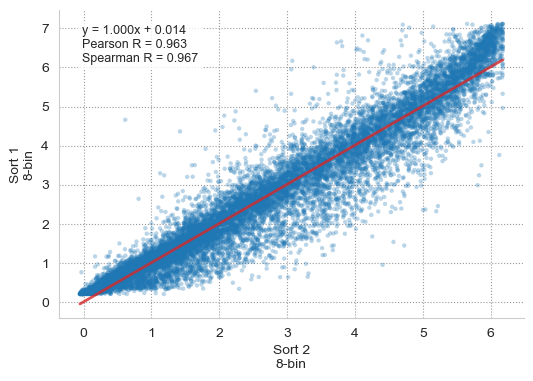

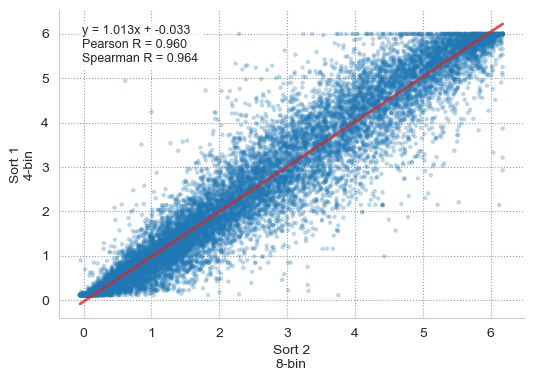

In [ ]:
# Plot using Plotting.scatter_compare_columns to validate the utility wrapper
ax1 = plot_scatter_regression(
    exp,
    x_col='Activity',
    y_col='Activity_Sort1',
    alpha=0.3,
    show_stats=True
)
ax1.set_xlabel(f'Sort 2\n8-bin')
ax1.set_ylabel(f'Sort 1\n8-bin')
ax1.figure.savefig(r"..\..\Figures_v5\ED4_sort2_vs_sort1.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

ax2 = plot_scatter_regression(
    exp,
    x_col='Activity',
    y_col='Activity_Sort1rep',
    alpha=0.3,
    show_stats=True
)
ax2.set_xlabel(f'Sort 2\n8-bin')
ax2.set_ylabel(f'Sort 1\n4-bin')
ax2.figure.savefig(r"..\..\Figures_v5\ED4_sort2_vs_sort1rep.pdf", format='pdf', transparent=True, bbox_inches='tight')

plt.show()

In [54]:
# SynAD_Glu_2_allinfo.csv stores the raw FACS value from pre-Gcn4-normalizing as 'Activity'
if 'FACS_Activity' not in bcs.columns:
    bcs = bcs.rename(columns={'Activity': 'FACS_Activity'})
bcs = bcs[['AAseq', 'FACS_Activity']]

exp_facs_negctrl_mean = 5390
exp_facs_gcn4 = 46954


bcs['Activity'] = bcs['FACS_Activity'].apply(scale_activity, args=(exp_facs_negctrl_mean, exp_facs_gcn4))
bcs = bcs.merge(exp[['AAseq', 'Activity']], on='AAseq', suffixes=('', '_Averaged'))
bcs = bcs[bcs['AAseq'].isin(exp['AAseq'])]

C:\Users\music\AppData\Local\Temp\ipykernel_45628\1640620532.py:21: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


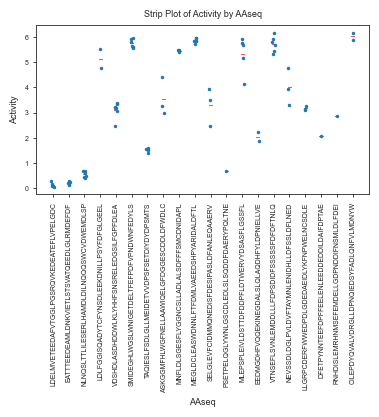

In [55]:
random.seed(20250106)

# Choose a random subset of AAseq values from synthseq['AAseq']
num_samples = 20  # Specify the number of samples you want
random_aa_seq_values = random.sample(list(exp['AAseq'].unique()), num_samples)

# Filter the seprats DataFrame to include only the desired 'AAseq' values
bcssub = bcs[bcs['AAseq'].isin(random_aa_seq_values)]

# Plot the strip plot
plt.figure(figsize=(4.3, 2.2))
ax = sns.stripplot(x='AAseq', y='Activity', data=bcssub, size=2.5)
# Add short horizontal dashes for each "Activity_Weighted" value
for i, aa_seq in enumerate(bcssub['AAseq'].unique()):
    activity_averaged = bcssub[bcssub['AAseq'] == aa_seq]['Activity_Averaged'].values[0]
    ax.plot([i - 0.1, i + 0.1], [activity_averaged, activity_averaged], color='r', linestyle='-', linewidth=0.8, alpha=0.7)
plt.xticks(rotation=90)  # Rotate x-axis labels for better readability
plt.xlabel('AAseq', fontsize=6.5)
plt.ylabel('Activity', fontsize=6.5)
plt.title('Strip Plot of Activity by AAseq', fontsize=6.5)
plt.tight_layout()
plt.savefig(r"..\..\Figures_v5\ED4_barcode_variability.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

### ED4 c: Ratio and GFP-only scores are highly correlated

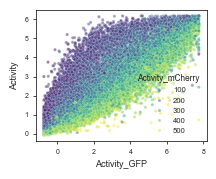

In [56]:
plt.figure(figsize=(2.2,1.7))
sns.scatterplot(exp,x='Activity_GFP',y='Activity',hue='Activity_mCherry',palette='viridis',s=5,alpha=0.5)
plt.savefig(r"..\..\Figures_v5\ED4_GFP_vs_ratio.pdf", format='pdf', transparent=True, bbox_inches='tight')

### Figure 2c: Activity distribution of all tested designed activation domains

In [57]:
exp_ctrls.rename(columns={'Activity_Sort2':'Activity'}, inplace=True)

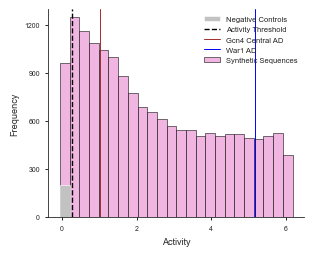

In [58]:
sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})

fig, ax = plt.subplots(figsize=(3.3, 2.7))

counts, bins = np.histogram(exp['Activity'].dropna(), bins=24)
bin_centers = (bins[:-1] + bins[1:]) / 2

ax.bar(bins[:-1], counts, width=np.diff(bins), align='edge',
       color="#F0B2E0", edgecolor='black', linewidth=0.4, alpha=0.95, label='Synthetic Sequences')

# controls as a simple histogram overlay

ax.hist(exp_ctrls[exp_ctrls['NegativeControl'] == True]['Activity'], bins=bins, edgecolor="white", linewidth=0.4,
       color="#C2C2C2", alpha=1, label='Negative Controls')


ax.axvline(x=activethresh, color='black', linestyle='--', linewidth=1.0, label='Activity Threshold')

ax.axvline(x=gcn4cad,color='brown',linestyle='-',linewidth=0.7,label='Gcn4 Central AD')
ax.axvline(x=war1,color='blue',linestyle='-',linewidth=0.7,label='War1 AD')


ax.set_ylim(0, 1300)
ax.set_xlabel("Activity", fontsize=6.5)
ax.set_ylabel("Frequency", fontsize=6.5)
ax.tick_params(axis='both', which='major', labelsize=5)
ax.yaxis.set_major_locator(ticker.MultipleLocator(300))
ax.xaxis.set_major_locator(ticker.MultipleLocator(2))

plt.tick_params(axis='both', which='major', length=2.5, width=0.6, color='black', bottom=True, left=True)


ax.legend(fontsize=5.5, loc='upper right', frameon=False)
sns.despine(ax=ax)
plt.savefig(r"..\..\Figures_v5\Fig2c_activity_hist.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

## Figure 3. Strong activation domains balance acidic and hydrophobic residues

### Figure 3a: Hydrophobic residue composition (W/F/Y/L/M) vs net charge

Tested designed sequences vs the 6,207 training sequences; shaded boxes are the average activities
of sequences within each composition box.

In [59]:
syn_contour = exp[['Net_Charge', 'WFYLM', 'Activity']].copy()

morffy['WFYLM'] = morffy['CountW'] + morffy['CountF'] + morffy['CountY'] + morffy['CountL'] + morffy['CountM']
morffy_contour = morffy[['Net Charge', 'WFYLM', 'PADI Score']].copy()
morffy.rename(columns={'Net Charge': 'Net_Charge'}, inplace=True)
morffy.rename(columns={'PADI Score': 'Activity'}, inplace=True)

morffyad = morffy[morffy['Activity'] > 1]

columns = ["Net_Charge", "WFYLM", "Group"]

# Prepare datasets
syn_contour["Group"] = "Designed"
morffyad['Group'] = 'Training'
syn_morffyad = pd.concat([morffyad[columns], syn_contour[columns]])

C:\Users\music\AppData\Local\Temp\ipykernel_45628\34851361.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  morffyad['Group'] = 'Training'


In [60]:
# Colormaps
pink_cmap = LinearSegmentedColormap.from_list("pink_grad", ["#f7b6d2", "#a8326e"])
green_cmap = LinearSegmentedColormap.from_list("green_grad", ["#6adf71", "#035e09"])

In [61]:
# Plotting helper
sns.set_context('paper', rc={"font.size": 6, "axes.titlesize": 6.5,
                             "axes.labelsize": 6.5, "xtick.labelsize": 5,
                             "ytick.labelsize": 5, "legend.fontsize": 5.5,
                             "legend.title_fontsize": 6})

def make_jointplot(all_tiles, x_var, y_var, contour_configs, output_path, filename,
                   activity_df=None, show_heatmap=False, add_colorbar=False, 
                   palette=None, xlim=None, ylim=None, show_theoretical_boundary=False, seq_length=40,
                   x_tick_interval=None, y_tick_interval=None):
    """
    Create jointplot with dynamic KDE overlays, activity heatmap, and colorbar.

    Parameters
    ----------
    all_tiles : pd.DataFrame
        Combined dataframe for the marginal histograms.
    x_var : str
        Column name for the X axis.
    y_var : str
        Column name for the Y axis.
    contour_configs : list of dicts
        List configuring the KDE overlays. Keys expected: 'data', 'cmap', 'zorder'.
    output_path : str
    filename : str
    activity_df : pd.DataFrame, optional
        The specific dataframe to use for the activity heatmap.
    show_heatmap : bool, default False
    add_colorbar : bool, default False
    palette : dict, optional
        Color mapping for the marginal histograms.
    xlim : tuple, optional
        The x-axis limits.
    ylim : tuple, optional
        The y-axis limits.
    x_tick_interval : float, default None
        The interval for x axis ticks
    y_tick_interval : float, default None
        The interval for y axis ticks
    """

    # --- 1. Set up an empty JointGrid (Instant, no wasted KDE computation) ---
    g = sns.JointGrid(
        data=all_tiles,
        x=x_var,
        y=y_var,
        hue="Group",
        palette=palette,
        marginal_ticks=True,
        height=3.2 # Adjusted base height to roughly match your 8x6 target
    )

    # Add marginal histograms
    g.plot_marginals(sns.histplot, binwidth=1)

    # --- 2. Optionally add heatmap ---
    if show_heatmap and activity_df is not None:
        heatmap_data = activity_df.pivot_table(
            index=y_var,
            columns=x_var,
            values="Activity",
            aggfunc="mean"
        )
        X, Y = np.meshgrid(heatmap_data.columns, heatmap_data.index)

        pcm = g.ax_joint.pcolormesh(
            X, Y, heatmap_data.values,
            cmap="Greys", shading="auto", alpha=0.8, zorder=0
        )

        if add_colorbar:
            # Create a dedicated axis for the colorbar
            # Coordinates are [left, bottom, width, height] relative to the figure.
            # 1.0 places it cleanly to the right of the right-marginal histogram.
            cbar_ax = g.fig.add_axes([1.0, 0.2, 0.03, 0.5]) 
            cbar = g.fig.colorbar(pcm, cax=cbar_ax, orientation="vertical")
            cbar.set_label("Avg Activity", fontsize=6.5)
            cbar.ax.tick_params(labelsize=5, length=2, width=0.6)

    # --- 3. Overlay Dynamic KDEs ---
    # Iterate through our list of configurations to plot as many as we want
    for config in contour_configs:
        sns.kdeplot(
            data=config["data"], 
            x=x_var, 
            y=y_var,
            cmap=config.get("cmap", "viridis"), 
            ax=g.ax_joint, 
            lw=config.get("lw", 0.6), 
            levels=config.get("levels", 7), 
            thresh=config.get("thresh", None),
            zorder=config.get("zorder", 1)
        )
    if xlim:
        g.ax_joint.set_xlim(xlim)
    if ylim:
        g.ax_joint.set_ylim(ylim)

    if x_tick_interval:
        g.ax_joint.xaxis.set_major_locator(MultipleLocator(x_tick_interval))
    if y_tick_interval:
        g.ax_joint.yaxis.set_major_locator(MultipleLocator(y_tick_interval))



    # --- NEW: Optionally add Theoretical Boundary ---
    if show_theoretical_boundary:
        # Create an array of X values from -40 to +40
        x_bound = np.linspace(-seq_length, seq_length, 200)
        
        # Calculate the theoretical max Y for each X
        y_bound = seq_length - np.abs(x_bound)
        
        # Plot the dashed line on the main joint axis
        g.ax_joint.plot(
            x_bound, y_bound, 
            color="black",       # High contrast
            linestyle="--",      # Dashed line for "theoretical" feel
            linewidth=0.7, 
            alpha=0.7,           # Slight transparency so it isn't overpowering
            zorder=5             # High zorder ensures it plots on top of the contours
        )

    # Explicitly target the joint axis for the tick marks
    g.ax_joint.tick_params(
        axis='both', which='major', length=2, width=0.6, 
        color='black', bottom=True, left=True
    )

    # Apply identical tick styling to the top marginal histogram
    g.ax_marg_x.tick_params(
        axis='y', which='major', length=2, width=0.6, 
        color='black', bottom=True, left=True
    )
    
    # Apply identical tick styling to the right marginal histogram
    g.ax_marg_y.tick_params(
        axis='x', which='major', length=2, width=0.6, 
        color='black', bottom=True, left=True
    )

    # --- 4. Style and save ---
    g.fig.set_figwidth(3.2)
    g.fig.set_figheight(2.4)

    # Save and show
    g.savefig(output_path + filename, dpi=300, transparent=True, bbox_inches="tight")
    plt.show()

c:\Users\music\miniforge3\envs\multi\Lib\site-packages\seaborn\distributions.py:1176: UserWarning: The following kwargs were not used by contour: 'lw'
  cset = contour_func(
c:\Users\music\miniforge3\envs\multi\Lib\site-packages\seaborn\distributions.py:1176: UserWarning: The following kwargs were not used by contour: 'lw'
  cset = contour_func(


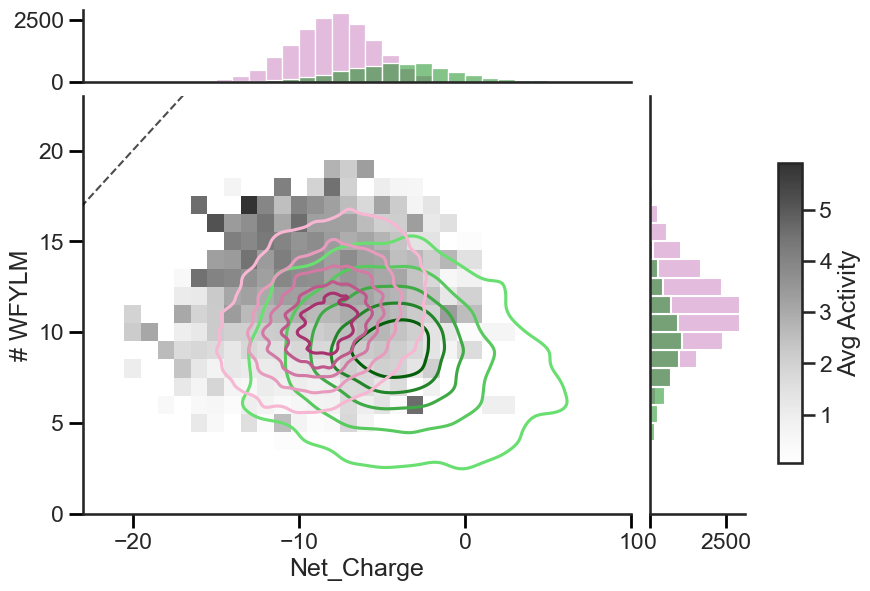

In [ ]:
# set prob density


# Define your datasets and how you want them to look
# To change which plots on top, just change the 'zorder' (higher numbers plot on top)
my_contours = [
    {
        "data": syn_contour, 
        "cmap": pink_cmap, 
        "levels": [0.05, 0.2, 0.4, 0.6, 0.8], # Percentiles of data
        "thresh": 0,
        "zorder": 2
    },
    {
        "data": morffyad, 
        "cmap": green_cmap, 
        "levels": [0.05, 0.2, 0.4,0.6, 0.8], # Percentiles of data
        "thresh": 0,
        "zorder": 1
    }
]

# Define your palette for the marginal histograms
my_palette = {"Training": "#0b8913", "Designed": "#c978bc"}

make_jointplot(
    all_tiles=syn_morffyad, 
    x_var="Net_Charge", 
    y_var="WFYLM", # Passed explicitly instead of using global `var`
    contour_configs=my_contours,
    output_path='..\..\Figures_v5/', 
    filename="Fig3a_contour.pdf",
    activity_df=syn_contour, # Choose which DF calculates the heatmap here!
    show_heatmap=True,
    add_colorbar=True,
    palette=my_palette,
    xlim=(-23, 10),
    ylim=(0, 23),
    x_tick_interval=10,
    y_tick_interval=5,
    show_theoretical_boundary=True
)

### Figure 3b: Activity distributions by individual composition of hydrophobic and charged residues

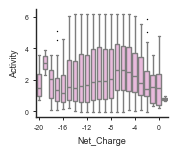

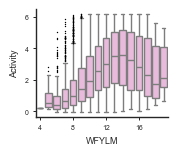

In [62]:
comp_list=['Net_Charge', 'WFYLM']
for aa in comp_list:
    exp[aa] = exp[aa].astype(int)
for aa in comp_list:
    fig, ax = plt.subplots(figsize=(1.7, 1.4))
    outlier_props = dict(marker='o', markerfacecolor='black', markersize=1, markeredgecolor='none')
    ax=sns.boxplot(exp,x=aa, y='Activity', color='#F0B2E0',flierprops=outlier_props)
    ax.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
    plt.gca().yaxis.set_major_locator(MultipleLocator(2))
    plt.gca().xaxis.set_major_locator(MultipleLocator(4))
    ax.set_xlabel(f'{aa}',fontsize=6.5)
    ax.set_ylabel('Activity',fontsize=6.5)
    sns.despine()
    plt.savefig(fr"..\..\Figures_v5\Fig3b_CompBoxplot_{aa}.pdf", format='pdf', transparent=True, bbox_inches='tight')
    plt.show()

### ED5 a: Activity vs composition and grammar metrics

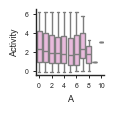

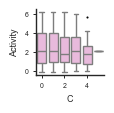

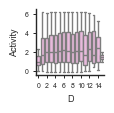

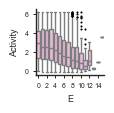

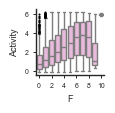

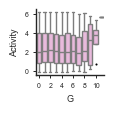

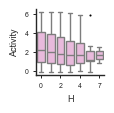

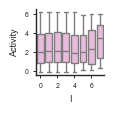

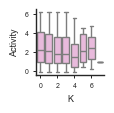

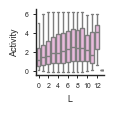

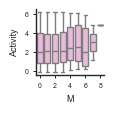

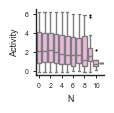

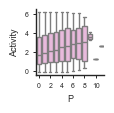

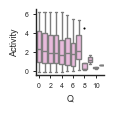

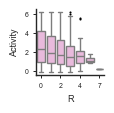

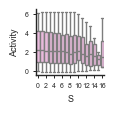

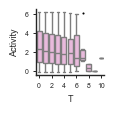

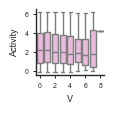

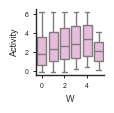

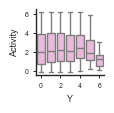

In [63]:
aa_list = ['A','C','D','E','F','G','H','I','K','L','M','N','P','Q','R','S','T','V','W','Y']
for aa in aa_list:
    fig, ax = plt.subplots(figsize=(0.88, 0.85))
    outlier_props = dict(marker='o', markerfacecolor='black', markersize=1.5, markeredgecolor='none')
    ax=sns.boxplot(exp,x=aa, y='Activity', color='#F0B2E0',flierprops=outlier_props)
    ax.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
    plt.gca().yaxis.set_major_locator(MultipleLocator(2))
    plt.gca().xaxis.set_major_locator(MultipleLocator(2))
    ax.set_xlabel(f'{aa}',fontsize=6.5)
    ax.set_ylabel('Activity',fontsize=6.5)
    sns.despine()
    plt.savefig(fr"..\..\Figures_v5\ED5_CompBoxplot_{aa}.pdf", format='pdf', transparent=True, bbox_inches='tight')
    plt.show()

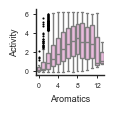

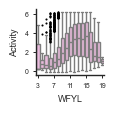

In [64]:
exp['WFYL'] = exp['W'] + exp['F'] + exp['Y'] + exp['L']
comp_list=['Aromatics', 'WFYL']
for aa in comp_list:
    exp[aa] = exp[aa].astype(int)
for aa in comp_list:
    fig, ax = plt.subplots(figsize=(0.88, 0.85))
    outlier_props = dict(marker='o', markerfacecolor='black', markersize=1.5, markeredgecolor='none')
    ax=sns.boxplot(exp,x=aa, y='Activity', color='#F0B2E0',flierprops=outlier_props)
    ax.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
    plt.gca().yaxis.set_major_locator(MultipleLocator(2))
    plt.gca().xaxis.set_major_locator(MultipleLocator(4))
    ax.set_xlabel(f'{aa}',fontsize=6.5)
    ax.set_ylabel('Activity',fontsize=6.5)
    sns.despine()
    plt.savefig(fr"..\..\Figures_v5\ED5_CompBoxplot_{aa}.pdf", format='pdf', transparent=True, bbox_inches='tight')
    plt.show()

np.float64(0.35810199353693883)

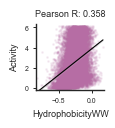

In [65]:
var='HydrophobicityWW'
plot_and_calculate(exp,var,'Activity',figsize=(0.88, 0.85),s=1,rasterize=True, filename=fr'..\..\Figures_v5\ED5_{var}_Activity_scatter.pdf')

np.float64(0.2524832099068104)

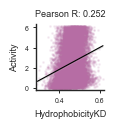

In [66]:
var='HydrophobicityKD'
plot_and_calculate(exp,var,'Activity',figsize=(0.88, 0.85),s=1,rasterize=True, filename=fr'..\..\Figures_v5\ED5_{var}_Activity_scatter.pdf')

np.float64(-0.05336670530285153)

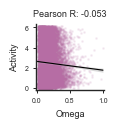

In [67]:
var='Omega'
plot_and_calculate(exp,var,'Activity',figsize=(0.88, 0.85),s=1,rasterize=True, filename=fr'..\..\Figures_v5\ED5_{var}_Activity_scatter.pdf')

                                         AAseq  Activity  OmegaWF_D  W  D
3537  EVVSVSSSLSVEALQNLEQQLENQLELSLNNTTEAEVEPV  0.145059       -1.0  0  0


np.float64(-0.19985631219180797)

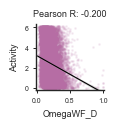

In [68]:
var='OmegaWF_D'
print(exp[exp['OmegaWF_D'] < 0][['AAseq','Activity','OmegaWF_D','W','D']]) # excluded sequence with no Ws or Ds
plot_and_calculate(exp[exp['OmegaWF_D'] > -1],var,'Activity',figsize=(0.88, 0.85),s=1,rasterize=True, filename=fr'..\..\Figures_v5\ED5_{var}_Activity_scatter.pdf')

np.float64(-0.19663759569021744)

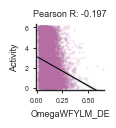

In [69]:
var='OmegaWFYLM_DE'
plot_and_calculate(exp,var,'Activity',figsize=(0.88, 0.85),s=1,rasterize=True, filename=fr'..\..\Figures_v5\ED5_{var}_Activity_scatter.pdf')

np.float64(-0.1229593020704079)

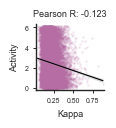

In [70]:
var='Kappa'
plot_and_calculate(exp,var,'Activity',figsize=(0.88, 0.85),s=1,rasterize=True, filename=fr'..\..\Figures_v5\ED5_{var}_Activity_scatter.pdf')

### ED5 b: Percent active by state size

In [71]:
def plot_ss_and_bars_by_thresh(
    df: pd.DataFrame,
    value_col: str,
    category_col: str,
    threshold: float,
    *,
    show_x_threshold: str = "above",
    normalize: bool = False,
    order: Optional[Sequence[str]] = None,
    palette: Optional[Union[str, Sequence[str]]] = None,
    gradient_cmap: Optional[Union[str, Sequence[str], LinearSegmentedColormap]] = None,
    colors: Optional[Dict[str, str]] = None,
    show_n: bool = False,
    show_n_fontsize: float = 5,
    show_sample_size: bool = True,
    figsize: Tuple[float, float] = (3.0, 2.4),
) -> Tuple[plt.Figure, Tuple[plt.Axes, plt.Axes]]:
    """Plot sample-size bars above threshold-based bars.

    Parameters
    ----------
    df : DataFrame
        Input data.
    value_col : str
        Column to threshold.
    category_col : str
        Column defining categories.
    threshold : float
        Threshold value.
    show_x_threshold : {"above", "below"}, default "above"
        Show bars for values above or below threshold.
    normalize : bool, default False
        If True, show percentages within each category instead of raw counts.
    order : sequence, optional
        Category order.
    palette : str or sequence, optional
        Seaborn palette name or list of colors.
    gradient_cmap : str, sequence, or LinearSegmentedColormap, optional
        Apply left→right gradient across categories.
    colors : dict, optional
        Manual category→color mapping (highest priority).
    show_n : bool, default False
        Annotate sample sizes above barplot.
    show_n_fontsize : float, default 5
        Font size for show_n labels.
    show_sample_size : bool, default True
        Draw the sample-size barplot above the threshold barplot.
    figsize : tuple, default (3.0, 2.4)
        Figure size.

    Returns
    -------
    (fig, (ax_ss, ax_thresh))
    """
    if order is None:
        order = sorted(df[category_col].dropna().unique().tolist())
    
    if show_sample_size:
        fig, (ax_ss, ax_thresh) = plt.subplots(2, 1, figsize=figsize, sharex=True,
                                                gridspec_kw={"height_ratios": [1, 3]})
    else:
        fig, ax_thresh = plt.subplots(figsize=figsize)
        ax_ss = None
    
    # Determine colors (3-tier priority: colors → gradient_cmap → palette → default)
    bar_palette = None
    if colors is not None:
        bar_palette = colors
    
    # Sample-size barplot
    counts = df[category_col].value_counts()
    bar_heights = [counts.get(cat, 0) for cat in order]
    if bar_palette is not None:
        if isinstance(bar_palette, dict):
            bar_colors = [bar_palette.get(cat, "#333333") for cat in order]
        else:
            bar_colors = [bar_palette[i % len(bar_palette)] for i in range(len(order))]
    else:
        bar_colors = "#333333"
    if ax_ss is not None:
        ax_ss.bar(range(len(order)), bar_heights, color=bar_colors, edgecolor="black", linewidth=0.3)

        # Add sample size annotations if requested
        if show_n:
            for i, height in enumerate(bar_heights):
                ax_ss.text(i, height, f"n={int(height)}", ha="center", va="bottom", fontsize=show_n_fontsize)

        ax_ss.set_ylabel("Sample Size")
        sns.despine(ax=ax_ss)
    
    # Threshold barplot
    x_pos = np.arange(len(order))
    
    above_counts = []
    below_counts = []
    for cat in order:
        subset = df[df[category_col] == cat][value_col].dropna()
        n_total = len(subset)
        n_above = (subset > threshold).sum()
        n_below = (subset <= threshold).sum()
        
        if normalize and n_total > 0:
            above_counts.append(100.0 * n_above / n_total)
            below_counts.append(100.0 * n_below / n_total)
        else:
            above_counts.append(n_above)
            below_counts.append(n_below)
    
    # Plot single bar per category (no side-by-side)
    if show_x_threshold == "above":
        ax_thresh.bar(x_pos, above_counts, color=bar_colors, edgecolor="black", linewidth=0.3)
    elif show_x_threshold == "below":
        ax_thresh.bar(x_pos, below_counts, color=bar_colors, edgecolor="black", linewidth=0.3)
    else:
        raise ValueError(f"Invalid show_x_threshold: '{show_x_threshold}'. Must be 'above' or 'below'.")
    
    ax_thresh.set_xticks(x_pos)
    ax_thresh.set_xticklabels(order)
    ax_thresh.set_xlabel(category_col)
    ax_thresh.set_ylabel("Percent" if normalize else "Count")
    sns.despine(ax=ax_thresh)
    
    plt.tight_layout()
    return fig, (ax_ss, ax_thresh)

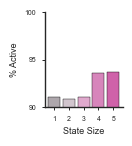

In [72]:
plot_ss_and_bars_by_thresh(
    df=exp,
    value_col='Activity',
    threshold =activethresh,
    category_col='State Size',
    normalize = True,
    colors=palettehex,
    show_n=False,
    show_sample_size=False,
    figsize=(1.3, 1.45)
)
plt.xlabel("State Size", fontsize=6.5)
plt.ylabel("% Active", fontsize=6.5)
plt.ylim(90,100)
plt.tick_params(axis='both', which='major')
plt.xticks(fontsize=5)
plt.yticks(fontsize=5)
plt.tick_params(axis='both', which='major', length=2.5, width=0.6, color='black', bottom=True, left=True)


plt.gca().yaxis.set_major_locator(MultipleLocator(5))
plt.savefig(r"..\..\Figures_v5\ED5_statesize_pctactive.pdf", format='pdf', transparent=True, bbox_inches='tight')

plt.show()


### Figure 3d: Activity distributions by state size

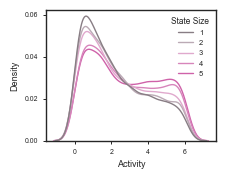

In [73]:
plt.figure(figsize=(2.2,1.7))
sns.kdeplot(exp,x='Activity',hue='State Size',palette=palettehex,linewidth=1.0)
plt.gca().yaxis.set_major_locator(MultipleLocator(0.02))
plt.gca().xaxis.set_major_locator(MultipleLocator(2))
plt.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
plt.savefig(r"..\..\Figures_v5\Fig3d_Activity_v_SS.pdf", format='pdf', transparent=True, bbox_inches='tight')


In [74]:
print('Mean Activity for State Size 5:', exp[exp['State Size'] == 5]['Activity'].mean())
print('Mean Activity for State Size 1:', exp[exp['State Size'] == 1]['Activity'].mean())
print('XX times Activity increase from State Size 1 to 5:', (exp[exp['State Size'] == 5]['Activity'].mean())/(exp[exp['State Size'] == 1]['Activity'].mean()))

print('WFYLM 25th percentile:', exp['WFYLM'].quantile(0.25))
print('WFYLM 75th percentile:', exp['WFYLM'].quantile(0.75))
print('Mean Activity for WFYLM > 75th percentile:', exp[exp['WFYLM'] > (exp['WFYLM'].quantile(0.75))]['Activity'].mean())
print('Mean Activity for WFYLM < 25th percentile:', exp[exp['WFYLM'] < (exp['WFYLM'].quantile(0.25))]['Activity'].mean())
print('XX times Activity increase from WFYLM < 25th percentile to > 75th percentile:', (exp[exp['WFYLM'] > (exp['WFYLM'].quantile(0.75))]['Activity'].mean())/(exp[exp['WFYLM'] < (exp['WFYLM'].quantile(0.25))]['Activity'].mean()))

Mean Activity for State Size 5: 2.7808071149717755
Mean Activity for State Size 1: 2.2260477464806048
XX times Activity increase from State Size 1 to 5: 1.2492126996683914
WFYLM 25th percentile: 9.0
WFYLM 75th percentile: 12.0
Mean Activity for WFYLM > 75th percentile: 3.3277637432173437
Mean Activity for WFYLM < 25th percentile: 1.246961972186157
XX times Activity increase from WFYLM < 25th percentile to > 75th percentile: 2.6686970552784004


### Figure 3e: Predictions from compositional linear regression
Used for Figure 3e–f, Figure S8, Table S6

Four nested OLS models of activity (Methods, *Analysis → Protein sequence analyses*), plus an
orthogonal stratification control. Every parameter quoted in the Methods is named in the next
cell, so the text and the code can be checked against each other line by line.

In [75]:
# ==========================================================================
#  PARAMETERS
# ==========================================================================

# --- Sequence design (all sequences have 40 residues) -----------
AA          = list("ACDEFGHIKLMNPQRSTVWY")   # the 20 amino-acid count columns
SEQ_LENGTH  = 40                             # every designed AD is a 40-mer
LEVEL_COL   = "State Size"
LEVELS      = np.array([1, 2, 3, 4, 5])      # Markov chain state sizes
SS_CENTER   = 1                              # State size centered at 1

# --- Cross-validation (Methods: five-fold ... GroupKFold from sklearn) ---
N_SPLITS    = 5


# --- Stratification search (Methods: second paragraph) --------------------
STRATA_MIN_PER_LEVEL = 10      # at least 10 sequences per composition strata
STRATA_MIN_LEVELS    = 3       # at least 3 state sizes (with >= 10 sequences) per composition strata
STRATA_MIN_RETAIN    = 0.75    # retain at least 75% of experimentally measured sequences
STRATA_T_GRID        = [0.40, 0.35, 0.30, 0.25, 0.22, 0.20]  # residual thresholds tried, high to low
STRATA_MAX_STEPS     = 40      # most bins the greedy allocation may spend

# --- Output ---------------------------------------------------------------
FIGDIR  = Path(r"..\..\Figures_v5")
SUPPDIR = Path(r"..\..\Figures_v5")
TABLEDIR = Path(r"RegressionTables")
TABLEDIR.mkdir(parents=True, exist_ok=True)

def save(fig, name, supp=False):
    """Save to the main or supplemental figure directory, matching the notebook's defaults."""
    path = (SUPPDIR if supp else FIGDIR) / f"{name}.pdf"
    fig.savefig(path, format="pdf", transparent=True, bbox_inches="tight")
    print(f"saved  {path.name}")


def ticks(ax):
    """Visible outward tick marks on both axes."""
    ax.tick_params(direction="out", length=2, width=0.6, bottom=True, left=True)

In [76]:
# ==========================================================================
#  Datasets : running regression analysis on full dataset, 50% sequence identity representatives, and state sizes 1-4 only
# ==========================================================================

# Sequence clusters define the CV folds and the robust standard errors.
# MMseqs2 TSV holds indices corresponding to `expseqs` indices
_member_to_rep = dict(zip(expseqs_cluster50perc["member"],
                          expseqs_cluster50perc["representative"]))
seq2clust = {seq: _member_to_rep.get(i) for i, seq in expseqs["AAseq"].items()}

# Measured sequences only -- the regression needs an activity and 20 counts.
reg_all = exp.dropna(subset=["Activity", LEVEL_COL, *AA]).copy()
reg_all["cluster"] = reg_all["AAseq"].map(seq2clust)

assert reg_all["cluster"].notna().all(), (
    f"{reg_all['cluster'].isna().sum()} sequences have no MMseqs2 cluster -- "
    "GroupKFold would pool them into one fold and inflate every R^2 below."
)

# 50% sequence identity representatives (MMseqs2)
_rep_seqs     = expseqs.loc[expseqs_cluster50perc["representative"].unique(), "AAseq"]
reg_clustered = reg_all[reg_all["AAseq"].isin(_rep_seqs)].copy()

# State sizes 1-4 (state size 5 contains many similar sequences)
reg_ss14 = reg_all[reg_all[LEVEL_COL] < 5].copy()

DATASETS = [
    (reg_all,       "All synthetic ADs"),
    (reg_clustered, "50% identity representatives"),
    (reg_ss14,      "State sizes 1-4 only"),
]

for df, label in DATASETS:
    print(f"{label:<32} n = {len(df):>6,}   clusters = {df['cluster'].nunique():>6,}")

All synthetic ADs                n = 16,770   clusters = 15,123
50% identity representatives     n = 15,049   clusters = 15,049
State sizes 1-4 only             n = 13,387   clusters = 13,381


In [77]:
# ==========================================================================
#  Four nested models of activity
# ==========================================================================

def build_designs(df):
    """Design matrix and column names for each of the four models.

    Model 1  composition          : 20 counts, no intercept.
    Model 2  state size           : intercept + centred state size.
    Model 3  composition + SS     : 20 counts + centred state size, no intercept.
    Model 4  composition x SS     : 20 counts + 20 interactions, no intercept
                                    and no standalone state-size column.

    Models 1, 3 and 4 omit the intercept because every sequence has SEQ_LENGTH
    residues, so the 20 counts sum to a constant and already span the intercept.
    Model 4 omits state size alone because the 20 interaction columns sum to
    SEQ_LENGTH x sc, making a separate sc column redundant.

    Centring state size shifts that column by a constant, which lies in the span
    of the counts -- so for Models 3 and 4 the fit, R^2 and F-tests are identical
    with or without centring. Only the coefficient values change.
    """
    C  = df[AA].to_numpy(float)
    sc = df[LEVEL_COL].to_numpy(float) - SS_CENTER

    return {
        "1. Composition": {
            "X": C,
            "names": AA,
        },
        "2. State size": {
            "X": np.column_stack([np.ones(len(df)), sc]),
            "names": ["intercept", "state_size"],
        },
        "3. Composition + state size": {
            "X": np.column_stack([C, sc]),
            "names": AA + ["state_size"],
        },
        "4. Composition x state size": {
            "X": np.column_stack([C, C * sc[:, None]]),
            "names": AA + [f"{a}:SS" for a in AA],
        },
    }


def get_data(df):
    """Response, cluster labels, and the four designs for one dataset."""
    return (df["Activity"].to_numpy(float),
            df["cluster"].to_numpy(),
            build_designs(df))


# Every design must be full rank, or the coefficients are not identifiable.
for name, d in build_designs(reg_all).items():
    rank, ncol = np.linalg.matrix_rank(d["X"]), d["X"].shape[1]
    assert rank == ncol, f"{name} is rank deficient: {ncol} columns, rank {rank}"
    print(f"  {name:<30} {ncol:>2} columns, rank {rank:>2}  OK")

  1. Composition                 20 columns, rank 20  OK
  2. State size                   2 columns, rank  2  OK
  3. Composition + state size    21 columns, rank 21  OK
  4. Composition x state size    40 columns, rank 40  OK


In [78]:
# ==========================================================================
#  Cross-validated prediction, R^2, F-tests, and coefficients
# ==========================================================================

def cv_predict(X, y, groups, n_splits=N_SPLITS):
    """Out-of-fold predictions, with folds made of whole sequence clusters.

    Each prediction comes from a model that never saw that sequence or any
    other member of its cluster.
    """
    pred = np.full(len(y), np.nan)
    for train, test in GroupKFold(n_splits).split(X, y, groups=groups):
        pred[test] = sm.OLS(y[train], X[train]).fit().predict(X[test])
    assert not np.isnan(pred).any(), "some rows were never held out"
    return pred


def oof_r2(y, pred):
    """R^2 = 1 - SSE/SST from out-of-fold predictions. Can be negative."""
    return 1 - np.sum((y - pred) ** 2) / np.sum((y - y.mean()) ** 2)


def _sse_rank_df(X, y):
    """Residual sum of squares, model rank, residual degrees of freedom."""
    fit  = sm.OLS(y, X).fit()
    rank = np.linalg.matrix_rank(X)
    return np.sum(fit.resid ** 2), rank, len(y) - rank


def f_test_overall(X, y):
    """F-test of this model against an intercept-only model."""
    sst = np.sum((y - y.mean()) ** 2)
    sse, rank, df_den = _sse_rank_df(X, y)
    df_num = rank - 1                     # one dimension reproduces the mean
    F = ((sst - sse) / df_num) / (sse / df_den)
    return F, df_num, df_den, stats.f.sf(F, df_num, df_den)


def f_test_nested(X_small, X_big, y):
    """F-test of the larger model against the smaller one.

    Valid whenever the smaller model's columns lie in the span of the larger
    model's. This holds for 1 -> 3 (literal subset) and for 3 -> 4: the 20
    interaction columns of Model 4 sum to SEQ_LENGTH x sc, so Model 3's
    standalone state-size column is in Model 4's column space even though it
    does not appear as one of its columns.
    """
    sse_s, rank_s, _      = _sse_rank_df(X_small, y)
    sse_b, rank_b, df_den = _sse_rank_df(X_big, y)
    df_num = rank_b - rank_s
    F = ((sse_s - sse_b) / df_num) / (sse_b / df_den)
    return F, df_num, df_den, stats.f.sf(F, df_num, df_den)


def coefficient_table(X, names, y, groups, center_on=None):
    """Full-data fit with cluster-robust SEs, tabulated.

    center_on: coefficient names to also report relative to their own mean.
    For the 20 counts this is the interpretable reading, since every sequence
    has SEQ_LENGTH residues and adding one residue always means removing another.
    """
    fit = sm.OLS(y, X).fit(cov_type="cluster", cov_kwds={"groups": groups})
    ci  = fit.conf_int()

    tab = pd.DataFrame({
        "coef":  fit.params,
        "se":    fit.bse,
        "ci_lo": ci[:, 0],
        "ci_hi": ci[:, 1],
        "p":     fit.pvalues,
    }, index=pd.Index(names, name="Term"))
    tab["q"] = multipletests(tab["p"], method="fdr_bh")[1]

    # Always present, so every model's table has the same columns. Stays NaN for
    # terms outside a centred block -- Model 2 has no block at all.
    tab["rel_mean"] = np.nan
    for block in (center_on or []):
        m = tab.loc[block, "coef"].mean()
        tab.loc[block, "rel_mean"] = tab.loc[block, "coef"] - m

    return tab

In [79]:
# ==========================================================================
#  Table S6a -- cross-validated R^2 and F-tests, per dataset
# ==========================================================================

NESTED = {                      # child model -> parent model
    "3. Composition + state size": "1. Composition",
    "4. Composition x state size": "3. Composition + state size",
}

rows = []
for df, label in DATASETS:
    y, g, designs = get_data(df)
    r2 = {name: oof_r2(y, cv_predict(d["X"], y, g)) for name, d in designs.items()}

    for name, d in designs.items():
        F, df_num, df_den, p = f_test_overall(d["X"], y)
        row = {
            "Dataset": label,
            "n sequences": len(df),
            "n clusters": df["cluster"].nunique(),
            "Model": name,
            "CV R2": r2[name],
            "F (vs intercept)": F,
            "df (vs intercept)": f"{df_num}, {df_den}",
            "p (vs intercept)": p,
        }
        # Each model's nested parent is fixed by NESTED, so it is stated in the
        # table legend rather than repeated on every row.
        parent = NESTED.get(name)
        if parent:
            Fn, dfn1, dfn2, pn = f_test_nested(designs[parent]["X"], d["X"], y)
            row.update({
                "delta CV R2": r2[name] - r2[parent],
                "F (nested)": Fn,
                "df (nested)": f"{dfn1}, {dfn2}",
                "p (nested)": pn,
            })
        rows.append(row)

tableS6a = pd.DataFrame(rows)

pd.set_option("display.width", 220)
print(tableS6a.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

# The ratio quoted in the Results, stated explicitly so the text can cite a row.
for label in tableS6a["Dataset"].unique():
    sub = tableS6a.set_index(["Dataset", "Model"]).loc[label, "CV R2"]
    print(f"\n{label}: composition R2 = {sub['1. Composition']:.4f}, "
          f"state size R2 = {sub['2. State size']:.4f}, "
          f"ratio = {sub['1. Composition'] / sub['2. State size']:.1f}x")

                     Dataset  n sequences  n clusters                       Model    CV R2  F (vs intercept) df (vs intercept)  p (vs intercept)  delta CV R2  F (nested) df (nested)  p (nested)
           All synthetic ADs        16770       15123              1. Composition   0.2458             290.3         19, 16750                 0          NaN         NaN         NaN         NaN
           All synthetic ADs        16770       15123               2. State size  0.01296               226          1, 16768         9.415e-51          NaN         NaN         NaN         NaN
           All synthetic ADs        16770       15123 3. Composition + state size   0.2608             298.6         20, 16749                 0      0.01503       342.9    1, 16749   8.584e-76
           All synthetic ADs        16770       15123 4. Composition x state size   0.2671             159.9         39, 16730                 0     0.006315       10.48   19, 16730   8.494e-32
50% identity representatives  

In [80]:
# ==========================================================================
#  Table S6b -- coefficients for each model, cluster-robust SEs
# ==========================================================================
y, g, designs = get_data(reg_all)
coef_tables = {}

for name, d in designs.items():
    counts = [n for n in d["names"] if n in AA]
    inters = [n for n in d["names"] if n.endswith(":SS")]
    blocks = [b for b in (counts, inters) if b]

    tab = coefficient_table(d["X"], d["names"], y, g, center_on=blocks)
    coef_tables[name] = tab

    print(f"\n{'=' * 64}\n{name}\n{'=' * 64}")
    if counts:
        print(f"  mean of {len(counts)} composition coefficients = "
              f"{tab.loc[counts, 'coef'].mean():.4f}")
    if inters:
        mi = tab.loc[inters, "coef"].mean()
        print(f"  mean of {len(inters)} interaction coefficients = {mi:.4f}")
        print(f"  implied overall state-size effect = {SEQ_LENGTH} x {mi:.4f} "
              f"= {SEQ_LENGTH * mi:.4f} per step")
    sort_by = "rel_mean" if tab["rel_mean"].notna().any() else "coef"
    print(tab.sort_values(sort_by, ascending=False).round(4).to_string())

tableS6b = (pd.concat(coef_tables, names=["Model"])
              .reset_index()
              .assign(Dataset="All synthetic ADs"))


1. Composition
  mean of 20 composition coefficients = 0.0408
        coef      se   ci_lo   ci_hi       p       q  rel_mean
Term                                                          
W     0.5671  0.0175  0.5328  0.6014  0.0000  0.0000    0.5263
F     0.4718  0.0089  0.4544  0.4893  0.0000  0.0000    0.4310
L     0.2393  0.0065  0.2266  0.2521  0.0000  0.0000    0.1986
Y     0.1746  0.0126  0.1500  0.1993  0.0000  0.0000    0.1338
M     0.1679  0.0130  0.1424  0.1934  0.0000  0.0000    0.1271
I     0.1365  0.0105  0.1159  0.1572  0.0000  0.0000    0.0957
P     0.0613  0.0091  0.0434  0.0793  0.0000  0.0000    0.0205
V     0.0364  0.0107  0.0154  0.0573  0.0007  0.0008   -0.0044
C     0.0284  0.0181 -0.0070  0.0639  0.1159  0.1159   -0.0124
D     0.0177  0.0064  0.0052  0.0303  0.0057  0.0060   -0.0231
G    -0.0276  0.0085 -0.0443 -0.0108  0.0012  0.0014   -0.0684
N    -0.0396  0.0086 -0.0564 -0.0228  0.0000  0.0000   -0.0804
A    -0.0478  0.0101 -0.0675 -0.0280  0.0000  0.0000   

In [81]:
# ==========================================================================
#  Table S6 -- two sheets, one workbook
# ==========================================================================
out = TABLEDIR / "TableS6_regression.xlsx"
with pd.ExcelWriter(out) as xl:
    tableS6a.to_excel(xl, sheet_name="S6a_model_comparison", index=False)
    tableS6b.to_excel(xl, sheet_name="S6b_coefficients",     index=False)
print(f"saved  {out.name}  "
      f"({len(tableS6a)} model rows, {len(tableS6b)} coefficient rows)")

saved  TableS6_regression.xlsx  (12 model rows, 83 coefficient rows)


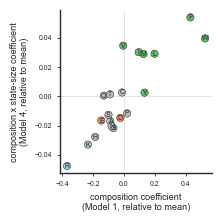

Correlation between composition and interaction coefficients: r = 0.863, p = 9.65e-07


In [82]:
RES_COLORS = {}
for r in "WFYLMIV": RES_COLORS[r] = "#61be6f"   # hydrophobic / aromatic
for r in "RK":      RES_COLORS[r] = "#aacada"   # basic
for r in "DE":      RES_COLORS[r] = "#ef8a62"   # acidic
for r in AA:        RES_COLORS.setdefault(r, "#bdbdbd")

m1 = coef_tables["1. Composition"]
m4 = coef_tables["4. Composition x state size"]
x = m1.loc[AA, "rel_mean"].to_numpy()
y = m4.loc[[f"{a}:SS" for a in AA], "rel_mean"].to_numpy()

fig, ax = plt.subplots(figsize=(2.2, 2.2))
ax.axhline(0, color="0.85", lw=0.5, zorder=0)
ax.axvline(0, color="0.85", lw=0.5, zorder=0)
ax.scatter(x, y, c=[RES_COLORS[a] for a in AA], s=28,
           edgecolor="black", linewidth=0.3, zorder=3)
for a, xi, yi in zip(AA, x, y):
    ax.annotate(a, (xi, yi), fontsize=5, ha="center", va="center", zorder=4)

ax.set_xlabel("composition coefficient\n(Model 1, relative to mean)", fontsize=6.5)
ax.set_ylabel("composition x state-size coefficient\n(Model 4, relative to mean)", fontsize=6.5)
ticks(ax); sns.despine(); fig.tight_layout()
plt.show()

r_coef, p_coef = pearsonr(x, y)
print(f"Correlation between composition and interaction coefficients: "
      f"r = {r_coef:.3f}, p = {p_coef:.3g}")

In [83]:
# ==========================================================================
#  Cross-validated composition-only prediction, used by Figures 3e and 3f
# ==========================================================================
y, g, designs = get_data(reg_all)

reg_all["comp_score"]    = cv_predict(designs["1. Composition"]["X"], y, g)
reg_all["comp_bin"]      = pd.qcut(reg_all["comp_score"], 5, labels=False, duplicates="drop")
reg_all["Pred_Quintile"] = "Q" + (reg_all["comp_bin"] + 1).astype(str)

print(f"n = {len(reg_all):,}   predicted {reg_all['comp_score'].min():.2f} to "
      f"{reg_all['comp_score'].max():.2f}   "
      f"observed {reg_all['Activity'].min():.2f} to {reg_all['Activity'].max():.2f}\n")

print(reg_all.groupby("Pred_Quintile").agg(
    n              = ("Activity",   "size"),
    score_from     = ("comp_score", "min"),
    score_to       = ("comp_score", "max"),
    mean_predicted = ("comp_score", "mean"),
    mean_observed  = ("Activity",   "mean"),
).round(3).to_string())

n = 16,770   predicted -0.63 to 6.80   observed -0.05 to 6.18

                  n  score_from  score_to  mean_predicted  mean_observed
Pred_Quintile                                                           
Q1             3354      -0.629     1.741           1.285          1.090
Q2             3354       1.742     2.225           1.992          1.913
Q3             3354       2.225     2.678           2.446          2.585
Q4             3354       2.678     3.230           2.936          3.184
Q5             3354       3.230     6.796           3.782          3.670


In [84]:
# --- Shared activity axis --------------------------------------------------
ACTIVITY_LIM  = ((exp['Activity'].min()-0.1), (exp['Activity'].max()+0.1))
ACTIVITY_TICK = 2
print(f"shared activity axis: {ACTIVITY_LIM}, ticks every {ACTIVITY_TICK}")

shared activity axis: (np.float64(-0.1524037522223889), np.float64(6.277249995820943)), ticks every 2


saved  Fig3e_regression_v_activity.pdf


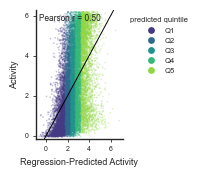


Figure 3e -- n = 16,770 designed ADs in 15,123 sequence clusters.
  Predictions are out-of-fold from Model 1 (composition only), 5-fold cluster-wise cross-validation.
  Pearson r = 0.496 (p = 0), R2 = 0.246, RMSE = 1.559, slope = 0.247


In [85]:
quint_order = [f"Q{i}" for i in range(1, 6)]
r, p_r = pearsonr(reg_all["comp_score"], reg_all["Activity"])

fig, ax = plt.subplots(figsize=(2.0, 1.75))
sns.scatterplot(data=reg_all, x="comp_score", y="Activity",
                hue="Pred_Quintile", hue_order=quint_order, palette="viridis",
                s=1.5, alpha=0.3, linewidth=0, ax=ax, rasterized=True)

# x: the predicted range, padded so the cloud is not flush against the frame.
# y: the activity scale shared with Figure 3d.
PRED_PAD = 0.3
ax.set_xlim(reg_all["comp_score"].min() - PRED_PAD,
            reg_all["comp_score"].max() + PRED_PAD)
ax.set_ylim(ACTIVITY_LIM)
ax.xaxis.set_major_locator(MultipleLocator(ACTIVITY_TICK))
ax.yaxis.set_major_locator(MultipleLocator(ACTIVITY_TICK))

# y = x reference. axline is infinite and clipped to the axes, so it adapts to
# the limits instead of setting them. The axes are on different scales now, so
# this will not sit at 45 degrees -- say "identity line" in the legend so it is
# not misread as a fit.
ax.axline((0, 0), slope=1, color="black", lw=0.7, zorder=5)

ax.set_xlabel("Regression-Predicted Activity", fontsize=6.5)
ax.set_ylabel("Activity", fontsize=6.5)
ax.text(0.03, 0.97, f"Pearson r = {r:.2f}", transform=ax.transAxes,
        ha="left", va="top", fontsize=6)

leg = ax.legend(frameon=False, fontsize=5.5, title="predicted quintile",
                title_fontsize=5.5, markerscale=4,
                bbox_to_anchor=(1.01, 1), loc="upper left")
for h in leg.legend_handles:
    h.set_alpha(1)

ticks(ax); sns.despine(); fig.tight_layout()
save(fig, "Fig3e_regression_v_activity")
plt.show()

# --- stats for the legend -------------------------------------------------
rmse  = np.sqrt(np.mean((reg_all["Activity"] - reg_all["comp_score"]) ** 2))
slope = np.polyfit(reg_all["Activity"], reg_all["comp_score"], 1)[0]
print(f"\nFigure 3e -- n = {len(reg_all):,} designed ADs in "
      f"{reg_all['cluster'].nunique():,} sequence clusters.")
print(f"  Predictions are out-of-fold from Model 1 (composition only), "
      f"{N_SPLITS}-fold cluster-wise cross-validation.")
print(f"  Pearson r = {r:.3f} (p = {p_r:.3g}), R2 = {oof_r2(reg_all['Activity'].to_numpy(), reg_all['comp_score'].to_numpy()):.3f}, "
      f"RMSE = {rmse:.3f}, slope = {slope:.3f}")

### Figure 3f: Grammar impacts activity more for favorable compositions

saved  Fig3f_coloredquintiles.pdf


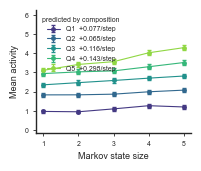


Figure 3f -- activity per state-size step, by composition quintile
  (OLS slope, cluster-robust 95% CI)
Quintile    n  slope  ci_lo  ci_hi      p
      Q1 3354 0.0773 0.0489 0.1057 0.0000
      Q2 3354 0.0650 0.0277 0.1023 0.0006
      Q3 3354 0.1156 0.0757 0.1556 0.0000
      Q4 3354 0.1435 0.1019 0.1851 0.0000
      Q5 3354 0.2981 0.2524 0.3439 0.0000

  composition x state-size interaction: beta = +0.1034 (95% CI +0.0829 to +0.1238), p = 3.55e-23
  Model 3 -> Model 4 F(19, 16730) = 10.5, p = 8.49e-32, delta CV R2 = +0.0063  (Table S6a)


In [86]:
fig, ax = plt.subplots(figsize=(2.0, 1.6))
quint_colors = sns.color_palette("viridis", 5)
slope_rows = []

for b, colour in enumerate(quint_colors):
    sub = reg_all[reg_all["comp_bin"] == b]
    mu = np.array([sub.loc[sub[LEVEL_COL] == l, "Activity"].mean() for l in LEVELS])
    se = np.array([sub.loc[sub[LEVEL_COL] == l, "Activity"].sem()  for l in LEVELS])

    fit = sm.OLS(sub["Activity"].to_numpy(float),
                 sm.add_constant(sub[LEVEL_COL].to_numpy(float))
                 ).fit(cov_type="cluster", cov_kwds={"groups": sub["cluster"]})
    ci = fit.conf_int()[-1]
    slope_rows.append({"Quintile": f"Q{b + 1}", "n": len(sub),
                       "slope": fit.params[-1], "ci_lo": ci[0], "ci_hi": ci[1],
                       "p": fit.pvalues[-1]})

    ax.errorbar(LEVELS, mu, yerr=1.96 * se, fmt="o-", color=colour,
                capsize=1.2, ms=2.5, lw=0.8, label=f"Q{b + 1}  {fit.params[-1]:+.3f}/step")

ax.set_ylim(ACTIVITY_LIM)
ax.set_xticks(LEVELS)
ax.set_xlabel("Markov state size"); ax.set_ylabel("Mean activity")
ax.legend(frameon=False, fontsize=5, title="predicted by composition", title_fontsize=5)
ticks(ax); sns.despine()
save(fig, "Fig3f_coloredquintiles")
plt.show()

# --- stats for the legend -------------------------------------------------
slopes = pd.DataFrame(slope_rows)
print("\nFigure 3f -- activity per state-size step, by composition quintile")
print("  (OLS slope, cluster-robust 95% CI)")
print(slopes.round(4).to_string(index=False))

# The figure's claim -- grammar helps more when composition is better -- tested
# directly as a continuous interaction, and formally as Model 3 -> Model 4.
reg_all["ss_centered"] = reg_all[LEVEL_COL] - SS_CENTER
inter = smf.ols("Activity ~ comp_score * ss_centered",
                data=reg_all).fit(cov_type="cluster",
                                  cov_kwds={"groups": reg_all["cluster"]})
term = "comp_score:ss_centered"
print(f"\n  composition x state-size interaction: beta = {inter.params[term]:+.4f} "
      f"(95% CI {inter.conf_int().loc[term, 0]:+.4f} to {inter.conf_int().loc[term, 1]:+.4f}), "
      f"p = {inter.pvalues[term]:.3g}")

_r = tableS6a.set_index(["Dataset", "Model"]).loc[("All synthetic ADs", "4. Composition x state size")]
print(f"  Model 3 -> Model 4 F({_r['df (nested)']}) = "
      f"{_r['F (nested)']:.1f}, p = {_r['p (nested)']:.3g}, "
      f"delta CV R2 = {_r['delta CV R2']:+.4f}  (Table S6a)")

### ED5 c: Activity by state size, controlled by composition

In [87]:
# ==========================================================================
#  Deriving the composition strata
# ==========================================================================

def residue_spread(df, residues=AA):
    """Total variation of each residue across state sizes.

    Methods: "we calculated the mean amino acid count within each state size,
    and used the range of the five state size means".
    """
    means = df.groupby(LEVEL_COL)[residues].mean()
    return (means.max() - means.min()).sort_values(ascending=False)


def build_strata(df, spec, min_per_level=STRATA_MIN_PER_LEVEL,
                 min_levels=STRATA_MIN_LEVELS):
    """Cross the binned residues into strata, keeping only well-populated cells.

    Methods: "ensuring that each composition stratum had at least 10 sequences
    present in each of at least 3 state sizes".
    """
    labels = [pd.qcut(df[r], nb, labels=False, duplicates="drop").astype(str)
              for r, nb in spec.items()]
    stratum = labels[0]
    for extra in labels[1:]:
        stratum = stratum + "|" + extra

    d = df.copy()
    d["stratum"] = stratum.to_numpy()

    cells = d.groupby(["stratum", LEVEL_COL]).size().reset_index(name="n")
    cells["ok"] = cells["n"] >= min_per_level
    full = cells[cells["ok"]].groupby("stratum").size()
    good = set(full[full >= min_levels].index)
    ok_pairs = set(zip(cells.loc[cells["ok"], "stratum"],
                       cells.loc[cells["ok"], LEVEL_COL]))

    keep = np.array([(s in good) and ((s, k) in ok_pairs)
                     for s, k in zip(d["stratum"], d[LEVEL_COL])])
    return d[keep].copy()


def residual_drift(kept, residues=AA):
    """Across-state-size drift of each residue that survives stratification.

    Every count is centred on its own stratum's mean, leaving only the
    imbalance the strata failed to remove. What comes back is then the same
    quantity as residue_spread -- the range of the per-state-size means -- so
    the two are directly comparable, and 1 - residual.sum() / spread.sum() is
    the fraction of composition drift the stratification removed.

    This mirrors the within-stratum centring used for activity in Figure S8.
    """
    centred = kept[residues] - kept.groupby("stratum")[residues].transform("mean")
    means   = centred.groupby(kept[LEVEL_COL]).mean()
    return means.max() - means.min()


def fit_bins(df, spreads, T, min_retain=STRATA_MIN_RETAIN, max_steps=STRATA_MAX_STEPS):
    """Give each residue enough bins to pull its residual drift under T.

    Every residue spreading more than T starts with 2 quantile bins. Each step
    spends one more bin on whichever residue is still furthest above T. Stops
    when every binned residue is under tolerance, or when the strata have grown
    fine enough to breach the retention floor -- in which case the last spec
    that cleared the floor is returned. Residues already varying by less than T
    are left unbinned.
    """
    spec = {r: 2 for r in spreads.index if spreads[r] > T}
    if not spec:
        return None

    best = None
    for _ in range(max_steps):
        kept = build_strata(df, spec)
        if len(kept) == 0 or len(kept) / len(df) < min_retain:
            break                        # gone too fine; keep the last good one
        rd = residual_drift(kept)
        best = (dict(spec), kept, rd)
        worst = rd[list(spec)].idxmax()  # the residue still furthest above T
        if rd[worst] <= T:
            break                        # everything under tolerance: done
        spec[worst] += 1                 # spend one more bin where it is needed
    return best


spreads = residue_spread(reg_all)
print("Across-state-size range of mean residue count:")
print(spreads.round(3).to_string(), "\n")

print(f"{'T':>6} {'met?':>5} {'residues':>9} {'strata':>7} {'retained':>9} "
      f"{'max resid':>10} {'removed':>8}  allocation")

chosen = None
for T in STRATA_T_GRID:
    out = fit_bins(reg_all, spreads, T)
    if out is None:
        continue
    spec, kept_T, rd = out
    worst = rd[list(spec)].max()
    met   = worst <= T
    alloc = " ".join(f"{r}{n}" for r, n in sorted(spec.items(),
                                                  key=lambda kv: -spreads[kv[0]]))
    print(f"{T:>6.2f} {'yes' if met else 'NO':>5} {len(spec):>9} "
          f"{kept_T['stratum'].nunique():>7} {len(kept_T) / len(reg_all):>8.1%} "
          f"{worst:>10.2f} {1 - rd.sum() / spreads.sum():>7.0%}  {alloc}")
    if met:                              # keep the lowest T that met tolerance
        chosen = {"T": T, "spec": spec, "kept": kept_T,
                  "retained": len(kept_T) / len(reg_all),
                  "n_strata": kept_T["stratum"].nunique(), "max_resid": worst}

if chosen is None:
    raise RuntimeError("No threshold in STRATA_T_GRID met its tolerance -- "
                       "see the scan above.")

SPEC = chosen["spec"]
kept = chosen["kept"]

print(f"\nSelected residual threshold T = {chosen['T']}")
print(f"  bins          {SPEC}")
print(f"  strata        {chosen['n_strata']}")
print(f"  retained      {100 * chosen['retained']:.1f}% of {len(reg_all):,} sequences")
print(f"  max residual  {chosen['max_resid']:.3f} residues")

Across-state-size range of mean residue count:
S    1.578
L    0.419
D    0.341
G    0.313
A    0.277
E    0.273
Q    0.223
Y    0.201
H    0.198
M    0.188
F    0.180
W    0.173
C    0.152
V    0.144
N    0.126
T    0.091
I    0.089
P    0.082
R    0.063
K    0.057 

     T  met?  residues  strata  retained  max resid  removed  allocation


  0.40   yes         2      10   100.0%       0.30     36%  S5 L2
  0.35   yes         2      10   100.0%       0.30     36%  S5 L2
  0.30   yes         4      39    99.7%       0.30     48%  S5 L2 D2 G2
  0.25   yes         6     117    89.5%       0.19     53%  S7 L2 D2 G2 A2 E2
  0.22    NO         7     127    83.1%       0.50     50%  S4 L2 D2 G2 A2 E2 Q2
  0.20    NO         8     124    84.8%       0.72     49%  S2 L2 D2 G2 A2 E2 Q2 Y2

Selected residual threshold T = 0.25
  bins          {'S': 7, 'L': 2, 'D': 2, 'G': 2, 'A': 2, 'E': 2}
  strata        117
  retained      89.5% of 16,770 sequences
  max residual  0.192 residues


saved  ED5_composition_matched.pdf


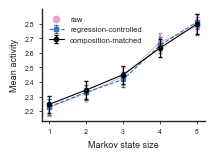


Figure S8 -- mean activity by Markov state size, three controls.
  Error bars are 1.96 x SEM. Strata: {'S': 7, 'L': 2, 'D': 2, 'G': 2, 'A': 2, 'E': 2}, 117 strata, 89.5% of sequences retained.

  raw         SS1 2.226 -> SS5 2.781 (+24.9%)   slope +0.1461 per step (95% CI +0.1226 to +0.1696), p = 4.11e-34   n = 16,770
  regression  SS1 2.229 -> SS5 2.813 (+26.2%)   slope +0.1490 per step (95% CI +0.1297 to +0.1683), p = 1.02e-51   n = 16,770
  matched     SS1 2.247 -> SS5 2.798 (+24.5%)   slope +0.1386 per step (95% CI +0.1148 to +0.1625), p = 4.08e-30   n = 15,015


In [88]:
# =====================================================================================================================================================================
#  Figure S8 -- activity by state size, full dataset + 2 composition controlled versions: linear regression-controlled and most-variable composition strata-controlled
# =====================================================================================================================================================================

y_all = reg_all["Activity"].to_numpy(float)
g_all = reg_all["cluster"].to_numpy()
grand_mean = y_all.mean()

# series 1: raw
raw_mu = np.array([reg_all.loc[reg_all[LEVEL_COL] == l, "Activity"].mean() for l in LEVELS])
raw_se = np.array([reg_all.loc[reg_all[LEVEL_COL] == l, "Activity"].sem()  for l in LEVELS])

# series 2: regression-controlled -- out-of-fold residuals from Model 1,
# cross-validated to match every other R^2 in this section
reg_all["comp_resid"] = y_all - reg_all["comp_score"] + grand_mean
reg_mu = np.array([reg_all.loc[reg_all[LEVEL_COL] == l, "comp_resid"].mean() for l in LEVELS])
reg_se = np.array([reg_all.loc[reg_all[LEVEL_COL] == l, "comp_resid"].sem()  for l in LEVELS])

# series 3: stratified -- remove each stratum's own mean, restore the grand mean
kept["adj"] = (kept["Activity"]
               - kept.groupby("stratum")["Activity"].transform("mean")
               + grand_mean)
adj_mu = np.array([kept.loc[kept[LEVEL_COL] == l, "adj"].mean() for l in LEVELS])
adj_se = np.array([kept.loc[kept[LEVEL_COL] == l, "adj"].sem()  for l in LEVELS])

fig, ax = plt.subplots(figsize=(2.1, 1.45))

# raw: faint connecting line, one point per state size in the state-size palette
ax.plot(LEVELS, raw_mu, "-", color="0.75", lw=0.7, zorder=1)
for i, l in enumerate(LEVELS):
    ax.errorbar(l, raw_mu[i], yerr=1.96 * raw_se[i], fmt="o", ms=3,
                color=palettehex[i], capsize=1.2, zorder=3)
ax.scatter([], [], marker="o", c=[palettehex[2]], label="raw")      # legend proxy

ax.errorbar(LEVELS, reg_mu, yerr=1.96 * reg_se, fmt="s--", ms=2.5, lw=0.8,
            color="#3b6fb6", capsize=1.2, zorder=4, label="regression-controlled")
ax.errorbar(LEVELS, adj_mu, yerr=1.96 * adj_se, fmt="o-", ms=3, lw=0.8,
            color="black", capsize=1.2, zorder=5, label="composition-matched")

ax.set_xticks(LEVELS)
ax.set_xlabel("Markov state size"); ax.set_ylabel("Mean activity")
ax.legend(frameon=False, fontsize=5.5); ticks(ax); sns.despine()
save(fig, "ED5_composition_matched", supp=True)
plt.show()

# --- stats for the legend -------------------------------------------------
print(f"\nFigure S8 -- mean activity by Markov state size, three controls.")
print(f"  Error bars are 1.96 x SEM. Strata: {SPEC}, "
      f"{chosen['n_strata']} strata, "
      f"{100 * chosen['retained']:.1f}% of sequences retained.\n")

for name, mu, frame, col in [("raw",        raw_mu, reg_all, "Activity"),
                             ("regression", reg_mu, reg_all, "comp_resid"),
                             ("matched",    adj_mu, kept,    "adj")]:
    fit = sm.OLS(frame[col].to_numpy(float),
                 sm.add_constant(frame[LEVEL_COL].to_numpy(float))
                 ).fit(cov_type="cluster", cov_kwds={"groups": frame["cluster"]})
    ci = fit.conf_int()[-1]
    print(f"  {name:<11} SS1 {mu[0]:.3f} -> SS5 {mu[-1]:.3f} "
          f"({100 * (mu[-1] / mu[0] - 1):+.1f}%)   "
          f"slope {fit.params[-1]:+.4f} per step "
          f"(95% CI {ci[0]:+.4f} to {ci[1]:+.4f}), p = {fit.pvalues[-1]:.3g}   "
          f"n = {len(frame):,}")

### ED5 d: SLiMs generally do not increase activity of designed ADs

In [89]:
# ==========================================================================
#  S15 -- Short linear motifs: definitions, counts, and prevalence
# ==========================================================================
MOTIF_SEED = 20261027
N_SHUFFLES = 50

# "residues" is the residue or residue class the motif is built from, and so
# also the variable positives and decoys are matched on: within a stratum every
# sequence has identical content of it, and only the arrangement differs.
MOTIFS = [
    {"key": "LxxLL", "label": "LxxLL", "residues": "L",
     "pattern": r"(?=(L..LL))"},
    {"key": "Phi",   "label": "\u03a6-xx-\u03a6-\u03a6", "residues": "WFLYMIV",
     "pattern": r"(?=([WFLYMIV]..[WFLYMIV][WFLYMIV]))"},
]

# Counted for the text, not tested: WxxLF is only present in 0.4% of sequences (67/16770)
WXXLF_PATTERN = r"(?=(W..LF))"


def class_count(df, cls):
    """Count of a residue or residue class: 'L' -> L, 'WFLYMIV' -> their sum."""
    return df[list(cls)].sum(axis=1)


def count_motif(seq, pattern):
    """Occurrences, including overlapping ones (the patterns use lookahead)."""
    return len(re.findall(pattern, seq))


for m in MOTIFS:
    pat = m["pattern"]
    reg_all[f"{m['key']}_count"] = reg_all["AAseq"].apply(lambda s: count_motif(s, pat))
    reg_all[f"has_{m['key']}"]   = reg_all[f"{m['key']}_count"] > 0

reg_all["WxxLF_count"] = reg_all["AAseq"].apply(lambda s: count_motif(s, WXXLF_PATTERN))
reg_all["has_WxxLF"]   = reg_all["WxxLF_count"] > 0

print(f"{'motif':<12} {'n with':>8} {'prevalence':>11} {'mean count':>11}")
for m in MOTIFS:
    n = int(reg_all[f"has_{m['key']}"].sum())
    print(f"{m['label']:<12} {n:>8,} {n / len(reg_all):>10.1%} "
          f"{reg_all[f'{m['key']}_count'].mean():>11.2f}")
n_w = int(reg_all["has_WxxLF"].sum())
print(f"{'WxxLF':<12} {n_w:>8,} {n_w / len(reg_all):>10.1%} "
      f"{reg_all['WxxLF_count'].mean():>11.2f}   (not tested: too few)")

motif          n with  prevalence  mean count
LxxLL           1,100       6.6%        0.07
Φ-xx-Φ-Φ       12,646      75.4%        1.38
WxxLF              67       0.4%        0.00   (not tested: too few)


In [90]:
# ==========================================================================
#  How often would these motifs arise by chance?
#  Each sequence is shuffled, preserving its exact composition. Collecting the
#  dataset-wide prevalence per replicate gives a null distribution to compare
#  the observed prevalence against.
# ==========================================================================
rng  = np.random.default_rng(MOTIF_SEED)
seqs = reg_all["AAseq"].to_numpy()

null_prev  = {m["key"]: [] for m in MOTIFS}    # one value per shuffle replicate
null_count = {m["key"]: [] for m in MOTIFS}

for _ in range(N_SHUFFLES):
    shuffled = ["".join(rng.permutation(list(s))) for s in seqs]
    for m in MOTIFS:
        c = np.array([count_motif(s, m["pattern"]) for s in shuffled])
        null_prev[m["key"]].append((c > 0).mean())
        null_count[m["key"]].append(c.mean())

print(f"\nObserved vs composition-matched shuffles ({N_SHUFFLES} replicates)\n")
for m in MOTIFS:
    k = m["key"]
    obs  = reg_all[f"has_{k}"].mean()
    null = np.array(null_prev[k])
    z    = (obs - null.mean()) / null.std(ddof=1)
    n_ge = int((null >= obs).sum())
    p    = (n_ge + 1) / (N_SHUFFLES + 1)        # empirical, so never exactly 0

    print(f"{m['label']}")
    print(f"  observed prevalence  {obs:.1%}")
    print(f"  shuffled prevalence  {null.mean():.1%} "
          f"(range {null.min():.1%} to {null.max():.1%}, SD {null.std(ddof=1):.2%})")
    print(f"  enrichment {obs / null.mean():.2f}x, z = {z:+.1f}, "
          f"empirical p {'<' if n_ge == 0 else '='} {p:.3g}")
    print(f"  mean occurrences: observed {reg_all[f'{k}_count'].mean():.2f}, "
          f"shuffled {np.mean(null_count[k]):.2f}\n")


Observed vs composition-matched shuffles (50 replicates)

LxxLL
  observed prevalence  6.6%
  shuffled prevalence  5.8% (range 5.3% to 6.1%, SD 0.15%)
  enrichment 1.14x, z = +5.4, empirical p < 0.0196
  mean occurrences: observed 0.07, shuffled 0.06

Φ-xx-Φ-Φ
  observed prevalence  75.4%
  shuffled prevalence  75.2% (range 74.5% to 75.8%, SD 0.29%)
  enrichment 1.00x, z = +0.7, empirical p = 0.294
  mean occurrences: observed 1.38, shuffled 1.45



In [91]:
# ==========================================================================
#  Composition-matched comparison: motif-positive vs decoy, within strata
# ==========================================================================
MIN_PER_GROUP = 10     # a stratum needs this many in BOTH groups to be usable


def matched_decoy_test(df, m, activity_col="Activity"):
    """Compare motif-containing sequences with decoys of identical content.

    Within a stratum every sequence has the same count of the motif's residue
    or residue class, so the two groups differ only in arrangement. Sequences
    with none of those residues cannot carry the motif and are dropped rather
    than counted as decoys. Strata too small in either group are skipped: a
    group of one has no variance, which makes its Welch p NaN and propagates
    NaN through the whole BH correction.
    """
    counts = class_count(df, m["residues"])
    d = df[counts > 0].copy()
    d["_stratum"] = class_count(d, m["residues"])

    rows = []
    for s, grp in d.groupby("_stratum"):
        pos = grp.loc[grp[f"has_{m['key']}"], activity_col]
        neg = grp.loc[~grp[f"has_{m['key']}"], activity_col]
        if len(pos) >= MIN_PER_GROUP and len(neg) >= MIN_PER_GROUP:
            rows.append({"stratum": s, "n_motif": len(pos), "n_decoy": len(neg),
                         "motif_mean": pos.mean(), "decoy_mean": neg.mean(),
                         "p_stratum": stats.ttest_ind(pos, neg, equal_var=False).pvalue})

    res = pd.DataFrame(rows)
    res["diff"] = res["motif_mean"] - res["decoy_mean"]
    res["q_stratum"] = multipletests(res["p_stratum"], method="fdr_bh")[1]

    return res, {"n_strata": len(res), "n_motif": int(res["n_motif"].sum())}


motif_results = {}
for m in MOTIFS:
    res, st = matched_decoy_test(reg_all, m)
    motif_results[m["key"]] = (res, st)
    n_sig = int((res["q_stratum"] < 0.05).sum())
    print(f"\n{m['label']}  (matched on {m['residues']} count)")
    print(f"  {st['n_strata']} strata, {st['n_motif']:,} motif sequences")
    print(f"  {n_sig} of {st['n_strata']} strata differ at q < 0.05")


LxxLL  (matched on L count)
  8 strata, 1,085 motif sequences
  1 of 8 strata differ at q < 0.05

Φ-xx-Φ-Φ  (matched on WFLYMIV count)
  11 strata, 12,195 motif sequences
  7 of 11 strata differ at q < 0.05


C:\Users\music\AppData\Local\Temp\ipykernel_45628\3559953160.py:40: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=d, x="_stratum", y="Activity", hue="Group",
C:\Users\music\AppData\Local\Temp\ipykernel_45628\3559953160.py:40: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:black'` for the same effect.

  sns.stripplot(data=d, x="_stratum", y="Activity", hue="Group",


saved  ED5_slim_matched_decoys.pdf


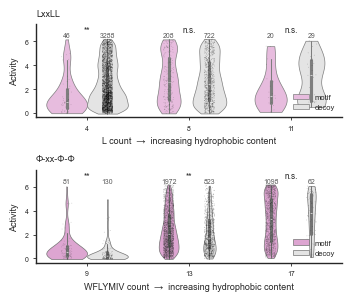


LxxLL -- all strata on L count (* = shown in figure), BH-corrected within motif
 stratum  n_motif  n_decoy  motif_mean  decoy_mean    diff  p_stratum  q_stratum fig
       4       46     3288      1.4931      2.4251 -0.9320     0.0002     0.0018   *
       5      154     3304      2.3102      2.5174 -0.2072     0.1831     0.3542    
       6      244     2656      2.5614      2.6582 -0.0968     0.4638     0.5300    
       7      248     1485      2.6390      2.7976 -0.1586     0.2214     0.3542    
       8      208      722      2.7996      2.6842  0.1154     0.4418     0.5300   *
       9      111      269      2.6476      2.7797 -0.1321     0.5539     0.5539    
      10       54       80      2.1981      2.7035 -0.5054     0.0907     0.2528    
      11       20       29      1.9965      2.8674 -0.8709     0.0948     0.2528   *

Φ-xx-Φ-Φ -- all strata on WFLYMIV count (* = shown in figure), BH-corrected within motif
 stratum  n_motif  n_decoy  motif_mean  decoy_mean    diff  p_st

In [92]:
# ==========================================================================
#  Figure S15 -- matched decoys across increasing hydrophobic content
# ==========================================================================
N_EX, MIN_N = 3, 20


def pick_strata(res, k=N_EX, min_n=MIN_N):
    """k strata evenly spanning low to high, among those with enough of both groups."""
    ok = res[(res["n_motif"] >= min_n) & (res["n_decoy"] >= min_n)].sort_values("stratum")
    if len(ok) <= k:
        return ok
    return ok.iloc[np.linspace(0, len(ok) - 1, k).round().astype(int)]


def stars(q):
    return "***" if q < 1e-3 else "**" if q < 1e-2 else "*" if q < 0.05 else "n.s."


sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})
fig, axes = plt.subplots(len(MOTIFS), 1, figsize=(3.5, 1.5 * len(MOTIFS)), squeeze=False)

MOTIF_COLORS = {"LxxLL": "#EEB5E2", "Phi": "#E79BD7"}
DECOY_COLOR  = "#E4E4E4"

for row, m in enumerate(MOTIFS):
    ax = axes[row, 0]
    res, st = motif_results[m["key"]]
    chosen = pick_strata(res)

    d = reg_all[class_count(reg_all, m["residues"]) > 0].copy()
    d["_stratum"] = class_count(d, m["residues"])
    d = d[d["_stratum"].isin(chosen["stratum"])]
    d["Group"] = np.where(d[f"has_{m['key']}"], "motif", "decoy")

    sns.violinplot(data=d, x="_stratum", y="Activity", hue="Group",
                   hue_order=["motif", "decoy"], order=chosen["stratum"],
                   dodge=True, cut=0, inner='box', linewidth=0.5, ax=ax,
                   palette={"motif": MOTIF_COLORS[m["key"]],
                            "decoy": DECOY_COLOR})
    sns.stripplot(data=d, x="_stratum", y="Activity", hue="Group",
                  hue_order=["motif", "decoy"], order=chosen["stratum"],
                  dodge=True, color="black", size=0.6, alpha=0.25,
                  legend=False, ax=ax)

    DODGE = 0.2
    top = d["Activity"].max()
    for i, (_, ex) in enumerate(chosen.iterrows()):
        ax.text(i, top * 1.09, stars(ex["q_stratum"]), ha="center", fontsize=6)
        ax.text(i - DODGE, top * 1.01, f"{int(ex['n_motif'])}",
                ha="center", va="bottom", fontsize=5, color="0.35")
        ax.text(i + DODGE, top * 1.01, f"{int(ex['n_decoy'])}",
                ha="center", va="bottom", fontsize=5, color="0.35")

    ax.set_ylim(top=top * 1.20)

    ax.yaxis.set_major_locator(ticker.MultipleLocator(2))

    ax.set_xlabel(f"{m['residues']} count  \u2192  increasing hydrophobic content",
                  fontsize=6.5)
    ax.set_ylabel("Activity", fontsize=6.5)
    ax.set_title(m["label"], fontsize=6.5, loc="left")
    ax.legend(frameon=False, fontsize=5.5, loc="lower right")
    ticks(ax); sns.despine(ax=ax)

plt.tight_layout()
save(fig, "ED5_slim_matched_decoys", supp=True)
plt.show()

for m in MOTIFS:
    res, st = motif_results[m["key"]]
    shown = set(pick_strata(res)["stratum"])

    tab = res.assign(fig=np.where(res["stratum"].isin(shown), "*", ""))
    cols = ["stratum", "n_motif", "n_decoy", "motif_mean", "decoy_mean", "diff"]
    cols += [c for c in ("sd", "mde") if c in res.columns]
    cols += ["p_stratum", "q_stratum", "fig"]

    print(f"\n{m['label']} -- all strata on {m['residues']} count "
          f"(* = shown in figure), BH-corrected within motif")
    print(tab[cols].round(4).to_string(index=False))

## Figure 4. AD predictors' performance on designed activation domains

### Figure 4a-f: Activities of designed sequences by predictor score

a) Comp, b) PADDLE, c) ADPred, d) TADA, e) ADhunterLite, f) ADhunterEnsemble.

C:\Users\music\AppData\Local\Temp\ipykernel_45628\1846584361.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  syncomptruefalse['CompTrueFalse'] = syncomptruefalse['Comp'].astype(bool)
C:\Users\music\AppData\Local\Temp\ipykernel_45628\1846584361.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(data=syncomptruefalse, x='CompTrueFalse', y='Activity', cut=0, palette=['lightgrey', 'grey'])


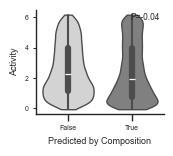

In [93]:
syncomptruefalse = exp[['AAseq', 'Comp', 'Activity']]
syncomptruefalse['CompTrueFalse'] = syncomptruefalse['Comp'].astype(bool)
fig, ax = plt.subplots(figsize=(1.65, 1.35))
ax = sns.violinplot(data=syncomptruefalse, x='CompTrueFalse', y='Activity', cut=0, palette=['lightgrey', 'grey'])
plt.xlabel('Predicted by Composition')
ax.yaxis.set_major_locator(ticker.MultipleLocator(2))
plt.tick_params(axis='y', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

_d = syncomptruefalse[['Comp', 'Activity']].dropna()
comp_pb_r, comp_pb_p = stats.pearsonr(_d['Comp'], _d['Activity'])
ax.text(0.97, 0.97, f"P={comp_pb_r:.2f}", transform=ax.transAxes,
        ha='right', va='top', fontsize=6)

sns.despine()
plt.savefig(r"..\..\Figures_v5\Fig4a_comp.pdf", format='pdf', transparent=True, bbox_inches='tight')

plt.show()

In [94]:
def plot_heatmap(
    df: pd.DataFrame,
    x_col: str,
    y_col: str,
    *,
    x_bins: Union[int, Sequence[float]],
    y_bins: Union[int, Sequence[float]],
    pixel_scale: float = 1.0,
    color: Optional[str] = None,
    colorbar: bool = True,
    ax: Optional[plt.Axes] = None,
    figsize: Tuple[float, float] = (2.6, 1.8),
) -> plt.Axes:
    """Plot 2D histogram heatmap from white to specified color.

    Parameters
    ----------
    df : DataFrame
        Input data.
    x_col : str
        Column for x-axis.
    y_col : str
        Column for y-axis.
    x_bins : int or sequence
        Bins for x-axis. If int, downsampled by pixel_scale.
    y_bins : int or sequence
        Bins for y-axis. If int, downsampled by pixel_scale.
    pixel_scale : float, default 1.0
        Downsample int bins: bx = max(4, int(x_bins / pixel_scale)).
    color : str, optional
        Hex color for heatmap (white→color). If None, defaults to gray.
    colorbar : bool, default True
        Show colorbar.
    ax : Axes, optional
        Existing axes.
    figsize : tuple, default (2.6, 1.8)
        Figure size used only when ax is None.

    Returns
    -------
    Axes
    """
    ax = _coerce_ax(ax, figsize=figsize)
    
    x = df[x_col].dropna().to_numpy()
    y = df[y_col].dropna().to_numpy()
    
    # Remove rows where either is NaN
    mask = ~(np.isnan(x) | np.isnan(y))
    x = x[mask]
    y = y[mask]
    
    # Apply pixel_scale downsampling if bins are ints
    resolved_x_bins = x_bins
    resolved_y_bins = y_bins
    if isinstance(x_bins, int):
        resolved_x_bins = max(4, int(x_bins / float(pixel_scale)))
    if isinstance(y_bins, int):
        resolved_y_bins = max(4, int(y_bins / float(pixel_scale)))
    
    H, xedges, yedges = np.histogram2d(x, y, bins=(resolved_x_bins, resolved_y_bins))
    Hm = np.ma.masked_where(H == 0, H)

    # White→color colormap
    if color is None:
        color = "#808080"  # default gray
    base = mcolors.to_rgba(color)[:3]
    cmap_obj = LinearSegmentedColormap.from_list("heat_cmap", [(1, 1, 1), base], N=256)

    vmax = H.max()
    norm = Normalize(vmin=0, vmax=vmax)

    mesh = ax.imshow(Hm.T, origin="lower", aspect="auto", cmap=cmap_obj, norm=norm,
                     extent=[xedges[0], xedges[-1], yedges[0], yedges[-1]])

    ax.set_xlabel(x_col)
    ax.set_ylabel(y_col)

    if colorbar:
        cb = plt.colorbar(mesh, ax=ax)
        cb.ax.tick_params(labelsize=5, length=2, width=0.6)
        cb.outline.set_linewidth(0.6)

    return ax

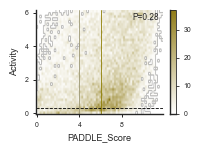

Pearson R = 0.279353251936308; p-val = 0.000
Spearman R = 0.2910762527904469; p-val = 0.000


In [95]:
pad_heat = plot_heatmap(df=exp,x_col='PADDLE_Score',y_col='Activity',color="#8f7b16",x_bins=140,y_bins=80,figsize=(2.04, 1.35),pixel_scale=2)

pad_heat.axhline(y=activethresh, color='black', lw=0.6, linestyle='--')
pad_heat.axvline(x=4, color='#9b9672', lw=0.6)
pad_heat.axvline(x=6, color='#8e7e02', lw=0.6)
pad_heat.xaxis.set_major_locator(ticker.MultipleLocator(4))
pad_heat.yaxis.set_major_locator(ticker.MultipleLocator(2))
pad_heat.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
paddle_p_r, paddle_p_p = stats.pearsonr(exp['PADDLE_Score'],exp['Activity'])
paddle_s_r, paddle_s_p = stats.spearmanr(exp['PADDLE_Score'],exp['Activity'])
pad_heat.text(0.97, 0.97, f"P={paddle_p_r:.2f}", transform=pad_heat.transAxes,
         ha='right', va='top', fontsize=6)
sns.despine()  # remove top/right spines and grid
plt.savefig(r"..\..\Figures_v5\Fig4b_paddle.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
print(f'Pearson R = {paddle_p_r}; p-val = {paddle_p_p:.3f}')
print(f'Spearman R = {paddle_s_r}; p-val = {paddle_s_p:.3f}')

C:\Users\music\AppData\Local\Temp\ipykernel_45628\3635753432.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  synadpredtruefalse['ADPredTrueFalse'] = synadpredtruefalse['ADPred'].astype(bool)
C:\Users\music\AppData\Local\Temp\ipykernel_45628\3635753432.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.violinplot(data=synadpredtruefalse, x='ADPredTrueFalse', y='Activity', cut=0, palette=["#C089A5", models_palette_dict['ADPred']])


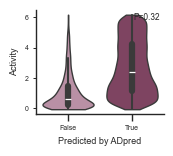

In [96]:
synadpredtruefalse = exp[['AAseq', 'ADPred', 'Activity']]
synadpredtruefalse['ADPredTrueFalse'] = synadpredtruefalse['ADPred'].astype(bool)
fig, ax = plt.subplots(figsize=(1.65, 1.35))
ax = sns.violinplot(data=synadpredtruefalse, x='ADPredTrueFalse', y='Activity', cut=0, palette=["#C089A5", models_palette_dict['ADPred']])
plt.xlabel('Predicted by ADpred')
ax.yaxis.set_major_locator(ticker.MultipleLocator(2))
plt.tick_params(axis='y', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

_d = synadpredtruefalse[['ADPred', 'Activity']].dropna()
adpred_pb_r, adpred_pb_p = stats.pearsonr(_d['ADPred'], _d['Activity'])
ax.text(0.97, 0.97, f"P={adpred_pb_r:.2f}", transform=ax.transAxes,
        ha='right', va='top', fontsize=6)

sns.despine()
plt.savefig(r"..\..\Figures_v5\Fig4c_adpred.pdf", format='pdf', transparent=True, bbox_inches='tight')

plt.show()

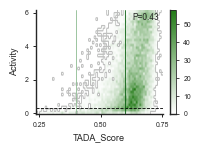

Pearson R = 0.4279981805075602; p-val = 0.000
Spearman R = 0.4440657804269811; p-val = 0.000


In [97]:
tada_heat = plot_heatmap(df=exp,x_col='TADA_Score',y_col='Activity',color="#217a15",x_bins=140,y_bins=80,figsize=(2.04, 1.35),pixel_scale=2)

tada_heat.axhline(y=activethresh, color='black', lw=0.6, linestyle='--')
tada_heat.axvline(x=0.4, color='#8dbb91', lw=0.6)
tada_heat.axvline(x=0.6, color='#085f0f', lw=0.6)
tada_heat.xaxis.set_major_locator(ticker.MultipleLocator(0.25))
tada_heat.yaxis.set_major_locator(ticker.MultipleLocator(2))
tada_heat.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
tada_p_r, tada_p_p = stats.pearsonr(exp['TADA_Score'],exp['Activity'])
tada_s_r, tada_s_p = stats.spearmanr(exp['TADA_Score'],exp['Activity'])
tada_heat.text(0.97, 0.97, f"P={tada_p_r:.2f}", transform=tada_heat.transAxes,
         ha='right', va='top', fontsize=6)
sns.despine()  # remove top/right spines and grid
plt.savefig(r"..\..\Figures_v5\Fig4d_tada.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
print(f'Pearson R = {tada_p_r}; p-val = {tada_p_p:.3f}')
print(f'Spearman R = {tada_s_r}; p-val = {tada_s_p:.3f}')

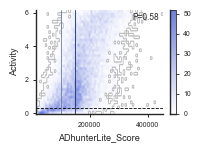

Pearson R = 0.5784550557995457; p-val = 0.000
Spearman R = 0.5777099115804893; p-val = 0.000


In [98]:
# Test plot_score_vs_activity_heatmap: 2D binned heatmap of score vs activity
# Use synthseq data for all model scores

adh_heat = plot_heatmap(
    df=exp,
    x_col='ADhunterLite_Score',
    y_col='Activity',
    x_bins=140,
    y_bins=80,
    color=models_palette_dict['ADhunterLite'],
    pixel_scale=2,
    figsize=(2.04, 1.35),
)

adh_heat.axhline(y=activethresh, color='black', lw=0.6, linestyle='--')
adh_heat.axvline(x=100000, color='#6e7b9a', lw=0.6)
adh_heat.axvline(x=150000, color='#122b67', lw=0.6)
adh_heat.xaxis.set_major_locator(ticker.MultipleLocator(200000))
adh_heat.yaxis.set_major_locator(ticker.MultipleLocator(2))
adh_heat.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

adh_p_r, adh_p_p = stats.pearsonr(exp['ADhunterLite_Score'],exp['Activity'])
adh_s_r, adh_s_p = stats.spearmanr(exp['ADhunterLite_Score'],exp['Activity'])
adh_heat.text(0.97, 0.97, f"P={adh_p_r:.2f}", transform=adh_heat.transAxes,
         ha='right', va='top', fontsize=6)
sns.despine()  # remove top/right spines and grid
plt.savefig(r"..\..\Figures_v5\Fig4e_adh.pdf", format='pdf', transparent=True, bbox_inches='tight')


plt.show()
print(f'Pearson R = {adh_p_r}; p-val = {adh_p_p:.3f}')
print(f'Spearman R = {adh_s_r}; p-val = {adh_s_p:.3f}')

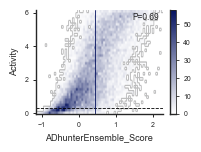

Pearson R = 0.6893345789397005; p-val = 0.000
Spearman R = 0.6987543878624571; p-val = 0.000


In [99]:
adhe_heat = plot_heatmap(df=exp[exp['Activity'].notnull()],x_col='ADhunterEnsemble_Score',y_col='Activity',color="#04125f",x_bins=140,y_bins=80,figsize=(2.04, 1.35),pixel_scale=2)

adhe_heat.axhline(y=activethresh, color='black', lw=0.6, linestyle='--')
adhe_heat.axvline(x=0.4441, color='#04125f', lw=0.6)

adhe_heat.xaxis.set_major_locator(ticker.MultipleLocator(1))
adhe_heat.yaxis.set_major_locator(ticker.MultipleLocator(2))
adhe_heat.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

adhe_p_r, adhe_p_p = stats.pearsonr(exp['ADhunterEnsemble_Score'],exp['Activity'])
adhe_s_r, adhe_s_p = stats.spearmanr(exp['ADhunterEnsemble_Score'],exp['Activity'])
adhe_heat.text(0.97, 0.97, f"P={adhe_p_r:.2f}", transform=adhe_heat.transAxes,
         ha='right', va='top', fontsize=6)
sns.despine()  # remove top/right spines and grid
plt.savefig(r"..\..\Figures_v5\Fig4f_adhe.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
print(f'Pearson R = {adhe_p_r}; p-val = {adhe_p_p:.3f}')
print(f'Spearman R = {adhe_s_r}; p-val = {adhe_s_p:.3f}')

### ED3 b: Activity vs average ADPred score

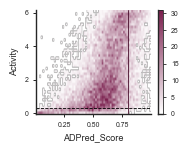

Pearson R = 0.48105572857276213; p-val = 0.000
Spearman R = 0.48365374482438783; p-val = 0.000


In [100]:
adp_heat = plot_heatmap(df=exp,x_col='ADPred_Score',y_col='Activity',color="#791D4C",x_bins=140,y_bins=80,figsize=(1.85, 1.35),pixel_scale=2)

adp_heat.axhline(y=activethresh, color='black', lw=0.6, linestyle='--')
adp_heat.axvline(x=0.8, color="#460C2A", lw=0.6)
adp_heat.xaxis.set_major_locator(ticker.MultipleLocator(0.25))
adp_heat.yaxis.set_major_locator(ticker.MultipleLocator(2))
adp_heat.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
sns.despine()  # remove top/right spines and grid
plt.savefig(r"..\..\Figures_v5\ED3_adpred_average_score.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
adp_p_r, adp_p_p = stats.pearsonr(exp['ADPred_Score'],exp['Activity'])
adp_s_r, adp_s_p = stats.spearmanr(exp['ADPred_Score'],exp['Activity'])
print(f'Pearson R = {adp_p_r}; p-val = {adp_p_p:.3f}')
print(f'Spearman R = {adp_s_r}; p-val = {adp_s_p:.3f}')

### Figure 4g: ROC and precision-recall curves for each predictor on the designed ADs

In [101]:
def plot_roc_prc(
    df: pd.DataFrame,
    model_cols: Sequence[str],
    truth_col: str,
    true_threshold: float,
    *,
    false_threshold: Optional[float] = None,
    mark_thresholds: Optional[Dict[str, Sequence[float]]] = None,
    model_colors: Optional[Dict[str, str]] = None,
    dot_colors: Optional[Union[Dict[str, str], Dict[str, Sequence[str]]]] = None,
    line_width: float = 0.8,
    dot_size: float = 15,
    dot_marker: str = 'o',
    dot_edgecolor: str = 'black',
    dot_edgewidth: float = 0.4,
    figsize: Tuple[float, float] = (4.6, 1.9),
) -> Tuple[plt.Figure, Tuple[plt.Axes, plt.Axes]]:
    """Plot ROC and PRC curves for multiple models side-by-side.

    Parameters
    ----------
    df : DataFrame
        Input data.
    model_cols : sequence of str
        List of model score column names to evaluate.
    truth_col : str
        Column with true scores/activity values.
    true_threshold : float
        Threshold for positive class.
    false_threshold : float, optional
        If provided, exclude data where false_threshold < truth_col < true_threshold
        (ambiguous zone).
    mark_thresholds : dict, optional
        Per-model thresholds to mark on curves: {model_col: [thresh1, thresh2, ...]}.
    model_colors : dict, optional
        Manual colors for each model: {model_col: color}.
    dot_colors : dict, optional
        Colors for threshold markers. Can be:
        - {model_col: color} — single color for all thresholds of that model
        - {model_col: [color1, color2, ...]} — different color per threshold
    line_width : float, default 0.8
        Width of ROC/PRC curves.
    dot_size : float, default 15
        Size of threshold markers in points^2.
    dot_marker : str, default 'o'
        Marker style for thresholds (e.g., 'o', 's', '^', 'D').
    dot_edgecolor : str, default 'black'
        Edge color for threshold markers.
    dot_edgewidth : float, default 0.4
        Edge width for threshold markers.
    figsize : tuple, default (4.6, 1.9)
        Figure size.

    Returns
    -------
    (fig, (ax_roc, ax_prc))
    """
    fig, (ax_roc, ax_prc) = plt.subplots(1, 2, figsize=figsize)
    
    # Filter data
    data = df[[truth_col] + list(model_cols)].copy()
    if false_threshold is not None:
        # Exclude ambiguous: false_threshold < truth_col < true_threshold
        mask = ~((data[truth_col] > false_threshold) & (data[truth_col] < true_threshold))
        data = data[mask]
    
    # Binary labels
    y_true = (data[truth_col] > true_threshold).astype(int).to_numpy()
    
    # Default colors
    if model_colors is None:
        palette = sns.color_palette("tab10", n_colors=len(model_cols))
        model_colors = {col: mcolors.rgb2hex(palette[i]) for i, col in enumerate(model_cols)}
    
    if dot_colors is None:
        dot_colors = model_colors
    
    # Plot each model
    for model_col in model_cols:
        y_score = data[model_col].dropna().to_numpy()
        y_true_clean = y_true[data[model_col].notna()]
        
        if len(y_true_clean) == 0:
            continue
        
        # ROC
        fpr, tpr, roc_thresholds = roc_curve(y_true_clean, y_score)
        roc_auc = auc(fpr, tpr)
        color = model_colors.get(model_col, "#333333")
        ax_roc.plot(fpr, tpr, color=color, linewidth=line_width, label=f"{model_col} (AUC={roc_auc:.2f})")
        
        # PRC
        precision, recall, prc_thresholds = precision_recall_curve(y_true_clean, y_score)
        prc_auc = auc(recall, precision)
        ax_prc.plot(recall, precision, color=color, linewidth=line_width, label=f"{model_col} (AUC={prc_auc:.2f})")
        
        # Mark thresholds
        if mark_thresholds and model_col in mark_thresholds:
            # Get dot colors for this model (can be single color or list of colors)
            model_dot_colors = dot_colors.get(model_col, color)
            if isinstance(model_dot_colors, str):
                # Single color for all thresholds
                model_dot_colors = [model_dot_colors] * len(mark_thresholds[model_col])
            
            for i, thresh in enumerate(mark_thresholds[model_col]):
                dot_color = model_dot_colors[i] if i < len(model_dot_colors) else model_dot_colors[-1]
                
                # Find closest threshold in ROC
                idx_roc = np.argmin(np.abs(roc_thresholds - thresh))
                ax_roc.scatter([fpr[idx_roc]], [tpr[idx_roc]], 
                              color=dot_color, s=dot_size, marker=dot_marker,
                              zorder=10, edgecolors=dot_edgecolor, linewidths=dot_edgewidth)
                
                # Find closest threshold in PRC (note: prc_thresholds length differs)
                if len(prc_thresholds) > 0:
                    idx_prc = np.argmin(np.abs(prc_thresholds - thresh))
                    ax_prc.scatter([recall[idx_prc]], [precision[idx_prc]], 
                                  color=dot_color, s=dot_size, marker=dot_marker,
                                  zorder=10, edgecolors=dot_edgecolor, linewidths=dot_edgewidth)
    
    # ROC formatting
    ax_roc.plot([0, 1], [0, 1], 'k--', linewidth=0.6, label="Random")
    ax_roc.set_xlim([0, 1])
    ax_roc.set_ylim([0, 1])
    ax_roc.set_xlabel("False Positive Rate")
    ax_roc.set_ylabel("True Positive Rate")
    ax_roc.set_title("ROC Curve")
    ax_roc.legend(loc="lower right", frameon=False, fontsize=5)
    ax_roc.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
    sns.despine(ax=ax_roc)
    
    # PRC formatting
    ax_prc.set_xlim([0, 1])
    ax_prc.set_ylim([0, 1])
    ax_prc.set_xlabel("Recall")
    ax_prc.set_ylabel("Precision")
    ax_prc.set_title("Precision-Recall Curve")
    ax_prc.legend(loc="lower left", frameon=False, fontsize=5)
    ax_prc.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

    sns.despine(ax=ax_prc)
    
    plt.tight_layout()
    return fig, (ax_roc, ax_prc)

In [102]:
comp_truepos =(exp[(exp['Comp'] == 1) & (exp['Activity'] > activethresh)].shape[0]) / exp[exp['Activity'] > activethresh].shape[0]
comp_falsepos =(exp[(exp['Comp'] == 1) & (exp['Activity'] < activethresh)].shape[0]) / exp[exp['Activity'] < activethresh].shape[0]
comp_precision = (exp[(exp['Comp'] == 1) & (exp['Activity'] > activethresh)].shape[0]) / exp[exp['Comp'] == 1].shape[0]
print(comp_truepos, comp_falsepos, comp_precision)
adpred_truepos =(exp[(exp['ADPred'] == 1) & (exp['Activity'] > activethresh)].shape[0]) / exp[exp['Activity'] > activethresh].shape[0]
adpred_falsepos =(exp[(exp['ADPred'] == 1) & (exp['Activity'] < activethresh)].shape[0]) / exp[exp['Activity'] < activethresh].shape[0]
adpred_precision = (exp[(exp['ADPred'] == 1) & (exp['Activity'] > activethresh)].shape[0]) / exp[exp['ADPred'] == 1].shape[0]
print(adpred_truepos, adpred_falsepos, adpred_precision)

0.5754160999935237 0.7878103837471784 0.8945831655255739
0.8968978693089826 0.4650112866817156 0.9572820902744177


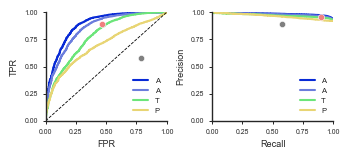

In [103]:
sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})

fig, (ax1, ax2) = plot_roc_prc(
    exp,
    truth_col='Activity',
    model_cols=['ADhunterEnsemble_Score', 'ADhunterLite_Score', 'TADA_Score', 'PADDLE_Score'],
    true_threshold=activethresh,
    mark_thresholds={
        # 'ADHunter Ensemble Score': [0.4441],
        # 'ADHunter Score': [100000, 150000],
        # 'TADA Score': [0.4, 0.6],
        # 'PADDLE Score': [4, 6],
        # 'ADPred Score (ave)': [0.8]
    },
    dot_colors={
        # 'ADHunter Score': ['lightblue', 'darkblue'],
        # 'TADA Score': ['lightgreen', 'darkgreen'],
        # 'PADDLE Score': ["#E6E22A", "#7A6507"],
        # 'ADHunter Ensemble Score': ["#04125f"]
        # 'ADPred Score (ave)': 'purple'
    },
    line_width=1.5,
    dot_size=20,
    # dot_marker='s',  # squares instead of circles
    dot_edgecolor='white',
    dot_edgewidth=0.4,
    model_colors={
        'ADhunterLite_Score': models_palette_dict['ADhunterLite'], 
        'TADA_Score': models_palette_dict['TADA'],
        'PADDLE_Score': models_palette_dict['PADDLE'],
        # 'ADPred Score (ave)': models_palette_dict['ADPred'],
        'ADhunterEnsemble_Score': models_palette_dict['ADhunterEnsemble']
    },
    figsize=(3.6, 1.7)
)
ax1.legend('AATP')
ax2.legend('AATP',loc='lower right')
ax1.yaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax1.xaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax2.yaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax2.xaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax1.set_xlabel('FPR',fontsize=6.5)
ax1.set_ylabel('TPR', fontsize=6.5)
ax1.tick_params(axis='x',labelsize=5)
ax1.tick_params(axis='y', labelsize=5)
ax2.set_xlabel('Recall', fontsize=6.5)
ax2.set_ylabel('Precision', fontsize=6.5)
ax2.tick_params(axis='x',labelsize=5)
ax2.tick_params(axis='y',labelsize=5)
ax1.set_title('')
ax2.set_title('')

ax1.scatter(comp_falsepos, comp_truepos, s=20, color="grey", edgecolor="white", linewidth=0.4, zorder=10)
ax2.scatter(comp_truepos, comp_precision, s=20, color="grey", edgecolor="white", linewidth=0.4, zorder=10)
ax1.scatter(adpred_falsepos, adpred_truepos, s=20, color="lightcoral", edgecolor="white", linewidth=0.4, zorder=10)
ax2.scatter(adpred_truepos, adpred_precision, s=20, color="lightcoral", edgecolor="white", linewidth=0.4, zorder=10)
sns.despine()
plt.savefig(r"..\..\Figures_v5\Fig4g_ROC_PRC.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

### Figure 4h: Activity distributions and precision for increasing predictor consensus

In [104]:
sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})

In [105]:
def plot_violins(
    df: pd.DataFrame,
    value_col: str,
    category_col: str,
    *,
    order: Optional[Sequence[str]] = None,
    palette: Optional[Union[str, Sequence[str]]] = None,
    gradient_cmap: Optional[Union[str, Sequence[str], LinearSegmentedColormap]] = None,
    colors: Optional[Dict[str, str]] = None,
    show_n: bool = False,
    median_lines: bool = False,
    median_color: str = "#5f5f5f",
    median_linewidth: float = 1.2,
    ax: Optional[plt.Axes] = None,
    figsize: Tuple[float, float] = (2.6, 1.8),
) -> plt.Axes:
    """Plot violin plots by category with flexible coloring options.

    Parameters
    ----------
    df : DataFrame
        Input data.
    value_col : str
        Column with values to plot.
    category_col : str
        Column defining categories for violins.
    order : sequence, optional
        Order of categories on x-axis.
    palette : str or sequence, optional
        Seaborn palette name or list of colors.
    gradient_cmap : str, sequence, or LinearSegmentedColormap, optional
        Apply left→right gradient across violins.
    colors : dict, optional
        Manual color mapping {category: color}.
    show_n : bool, default False
        Annotate sample sizes below each violin.
    median_lines : bool, default False
        Draw horizontal lines at the median value for each violin.
    median_color : str, default "#5f5f5f"
        Color of median lines.
    median_linewidth : float, default 1.2
        Width of median lines.
    ax : Axes, optional
        Existing axes.
    figsize : tuple, default (2.6, 1.8)
        Figure size used only when ax is None.

    Returns
    -------
    Axes
    """
    ax = _coerce_ax(ax, figsize=figsize)
    
    if order is None:
        order = sorted(df[category_col].dropna().unique().tolist())
    
    # Determine colors
    violin_palette = None
    if colors is not None:
        violin_palette = colors
    elif palette is not None:
        violin_palette = palette
    
    sns.violinplot(data=df, x=category_col, y=value_col, order=order,
                   palette=violin_palette, ax=ax, cut=0)
    sns.despine(ax=ax)
    
    # Add median lines if requested
    if median_lines:
        median_values = df.groupby(category_col)[value_col].median().reindex(order)
        for i, median in enumerate(median_values):
            if not pd.isna(median):
                ax.hlines(median, i - 0.4, i + 0.4, linestyles='-', 
                         color=median_color, linewidth=median_linewidth)
    
    # Add sample size annotations if requested
    if show_n:
        counts = df[category_col].value_counts()
        for i, cat in enumerate(order):
            n = int(counts.get(cat, 0))
            ax.text(i, ax.get_ylim()[0], f"n={n}", ha="center", va="bottom", fontsize=5)
    
    return ax

C:\Users\music\AppData\Local\Temp\ipykernel_45628\1313166264.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x=category_col, y=value_col, order=order,


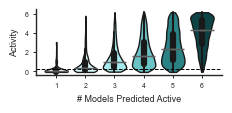

In [106]:
exp['# Models Predicted'] = exp['# Models Predicted'].astype(int)

plot_violins(
    df=exp[exp['# Models Predicted'] > 0],
    value_col='Activity',
    category_col='# Models Predicted',
    colors=consensus_6_palette,
    # show_n=True,
    figsize=(2.4,0.85)
)
plt.xlabel("# Models Predicted Active", fontsize=6.5)
plt.ylabel("Activity", fontsize=6.5)
plt.ylim((min(exp['Activity']) - 0.3), (max(exp['Activity']) + 0.3))
plt.axhline(y=activethresh, color='black', linestyle='--', linewidth=0.7)
plt.tick_params(axis='both', which='major')
plt.xticks(fontsize=5)
plt.yticks(fontsize=5)


cat_col = '# Models Predicted'
categories = sorted(exp[exp['# Models Predicted'] > 0][cat_col].unique())
median_values = exp[exp['# Models Predicted'] > 0].groupby(cat_col)['Activity'].median().reindex(categories)
# Plot a thick horizontal line for each median value
for i, median in enumerate(median_values):
    plt.hlines(median, i - 0.4, i + 0.4, linestyles='-', color="#5f5f5f", lw=1.0)

plt.gca().yaxis.set_major_locator(MultipleLocator(2))
plt.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

plt.savefig(r"..\..\Figures_v5\Fig4h_consensus_violins.pdf", format='pdf', transparent=True, bbox_inches='tight')

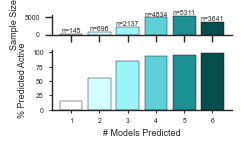

In [107]:
plot_ss_and_bars_by_thresh(
    df=exp[exp['# Models Predicted'] > 0],
    value_col='Activity',
    category_col='# Models Predicted',
    colors=consensus_6_palette,
    threshold=activethresh,
    normalize=True,
    show_n=True,
    figsize=(2.4, 1.5)
)
plt.ylabel("% Predicted Active", fontsize=6.5)
plt.xlabel("# Models Predicted", fontsize=6.5)
# plt.ylim((min(syn['Activity']) - 0.3), (max(syn['Activity']) + 0.3))
# plt.axhline(y=activethresh, color='black', linestyle='--', linewidth=2)
plt.tick_params(axis='both', which='major')
plt.xticks(fontsize=5)
plt.yticks(fontsize=5)


plt.gca().yaxis.set_major_locator(MultipleLocator(25))
plt.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

plt.savefig(r"..\..\Figures_v5\Fig4h_percent_samplesize.pdf", format='pdf', transparent=True, bbox_inches='tight')


### ED3 c: No single predictor or pair drives the consensus trend

In [108]:
def prepare_combo_data(df, eval_models, activethresh, activity_col):
    """Consensus count per sequence -> long frames for the exact and cumulative violins."""
    truth_binary = (df[activity_col] > activethresh).astype(int)
    consensus = df[eval_models].sum(axis=1)
    max_k = len(eval_models)

    # only the two columns the violins need, not a full frame copy
    exact_df = pd.DataFrame({'Threshold_Label': consensus,
                             activity_col: df[activity_col].to_numpy()})

    cumul_df = pd.concat(
        [pd.DataFrame({'Threshold_Label': f"$\\geq${k}",
                       activity_col: df.loc[consensus >= k, activity_col].to_numpy()})
         for k in range(max_k + 1)],
        ignore_index=True)

    at_max = (consensus >= max_k).astype(int)
    max_prec = precision_score(truth_binary, at_max, zero_division=0)
    max_rec = recall_score(truth_binary, at_max, zero_division=0)

    return exact_df, cumul_df, max_prec, max_rec


def plot_comprehensive_grids(df, all_models, activethresh, mode='leave-1',
                             activity_col='Activity', save_dir=None):
    missing_cols = [c for c in all_models + [activity_col] if c not in df.columns]
    if missing_cols:
        raise KeyError(f"Dataframe is missing expected columns: {missing_cols}")

    if (df[activity_col] > activethresh).sum() == 0:
        raise ValueError(f"No active sequences found using activethresh > {activethresh}.")

    if len(all_models) != 6:
        raise ValueError(f"{mode} mode requires exactly 6 models.")

    grid_specs = {
        'leave-1': (1, 2, 3, (7.1, 4.0)),
        'leave-2': (2, 3, 5, (7.1, 4.2)),
        'leave-3': (3, 4, 5, (7.1, 5.3)),
    }
    if mode not in grid_specs:
        raise ValueError("mode must be 'leave-1', 'leave-2', or 'leave-3'")
    n_drop, grid_rows, grid_cols, fig_size = grid_specs[mode]
    combos = list(combinations(all_models, n_drop))

    processed_data = []
    for dropped in combos:
        active_models = [m for m in all_models if m not in dropped]
        exact_df, cumul_df, max_prec, max_rec = prepare_combo_data(
            df, active_models, activethresh, activity_col)
        processed_data.append({
            'Dropped': " -\n".join(dropped),
            'Exact': exact_df,
            'Cumul': cumul_df,
            'Max_Prec': max_prec,
            'Max_Recall': max_rec,
        })

    # Sort from highest remaining recall (too strict) to lowest (essential models)
    processed_data.sort(key=lambda x: x['Max_Recall'], reverse=True)

    def create_grid(key, color, title_prefix, fname):
        fig, axes = plt.subplots(grid_rows, grid_cols, figsize=fig_size,
                                 sharex=True, sharey=True)
        axes_flat = axes.flatten()
        fig.suptitle(f"{title_prefix} ({mode})", fontsize=6.5, y=1.02)

        for idx, item in enumerate(processed_data):
            ax = axes_flat[idx]
            sns.violinplot(data=item[key], x='Threshold_Label', y=activity_col,
                           ax=ax, cut=0, color=color)
            ax.axhline(activethresh, color='red', linestyle='--', alpha=0.5)
            ax.set_title(f"Dropped: {item['Dropped']}\n"
                         f"Max Prec: {item['Max_Prec']:.3f} | Max Rec: {item['Max_Recall']:.3f}",
                         fontsize=5.5)
            ax.set_xlabel("Consensus Score")
            ax.set_ylabel(activity_col if idx % grid_cols == 0 else "")

        for ax in axes_flat[len(processed_data):]:
            ax.set_visible(False)

        plt.tight_layout()
        if save_dir is not None:
            fig.savefig(Path(save_dir) / f"{fname}_{mode}.pdf", format='pdf',
                        transparent=True, bbox_inches='tight')
        plt.show()

    create_grid('Exact', 'mediumaquamarine',
                'Exact Activity Distribution (=k)', 'NOTINCLUDED_S10_exact_violin')
    create_grid('Cumul', 'plum',
                'Cumulative Activity Distribution ($\\geq$k)', 'NOTINCLUDED_S10_cumul_violin')


all_models_list = ['ADPred', 'ADhunterLite', 'ADhunterEnsemble', 'PADDLE', 'TADA', 'Comp']

SUPPDIR = Path(r"..\..\Figures_v5")
# NOT IN SUBMISSION -- replaced by the two mean-activity panels in the next cell.
# plot_comprehensive_grids(exp, all_models_list, activethresh=activethresh, mode='leave-1', save_dir=SUPPDIR)
# plot_comprehensive_grids(exp, all_models_list, activethresh=activethresh, mode='leave-2', save_dir=SUPPDIR)

In [ ]:
# ==========================================================================
#  ED3: leave-1-out and leave-2-out consensus trends
#  Replaces the 21 violin grids. Each faint grey line is one redefined
#  consensus (one or two predictors dropped); the bold line is all six.
# ==========================================================================
ALL_MODELS = ['ADPred', 'ADhunterLite', 'ADhunterEnsemble', 'PADDLE', 'TADA', 'Comp']


def consensus_means(models):
    """Mean activity and SEM at each consensus count for one set of models."""
    k = exp[list(models)].sum(axis=1)
    rows = []
    for v in range(len(models) + 1):
        sel = exp.loc[k == v, 'Activity'].dropna()
        if len(sel) >= 20:
            rows.append({'k': v, 'mean': sel.mean(), 'sem': sel.sem(), 'n': len(sel)})
    return pd.DataFrame(rows)


full_consensus = consensus_means(ALL_MODELS)

for n_drop, fname in [(1, 'ED3_leave1out_consensus'), (2, 'ED3_leave2out_consensus')]:
    fig, ax = plt.subplots(figsize=(1.7, 1.4))
    for dropped in combinations(ALL_MODELS, n_drop):
        kept = [m for m in ALL_MODELS if m not in dropped]
        d = consensus_means(kept)
        ax.plot(d['k'], d['mean'], '-', color='0.75', lw=0.5, zorder=1)
    ax.errorbar(full_consensus['k'], full_consensus['mean'],
                yerr=1.96 * full_consensus['sem'], fmt='o-',
                color=consensus_6_palette[5], lw=1.2, ms=2.5, capsize=1.2,
                zorder=3, label='all 6')
    ax.set_xlabel('# predictors calling active')
    ax.set_ylabel('Mean activity')
    ax.xaxis.set_major_locator(MultipleLocator(2))
    ax.legend(frameon=False, loc='upper left')
    ax.tick_params(axis='both', which='major', length=2, width=0.6,
                   color='black', bottom=True, left=True)
    sns.despine()
    plt.savefig(rf"..\..\Figures_v5\{fname}.pdf", format='pdf', transparent=True,
                bbox_inches='tight')
    plt.show()
    print(f"{fname}: {len(list(combinations(ALL_MODELS, n_drop)))} redefined consensuses")


### ED3 e: 6-model consensus as a classifier on designed ADs

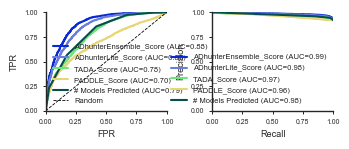

In [109]:
sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})

fig, (ax1, ax2) = plot_roc_prc(
    exp,
    truth_col='Activity',
    model_cols=['ADhunterEnsemble_Score', 'ADhunterLite_Score', 'TADA_Score', 'PADDLE_Score', '# Models Predicted'],
    true_threshold=activethresh,
    mark_thresholds={
        # 'ADHunter Ensemble Score': [0.4441],
        # 'ADHunter Score': [100000, 150000],
        # 'TADA Score': [0.4, 0.6],
        # 'PADDLE Score': [4, 6],
        # 'ADPred Score (ave)': [0.8]
    },
    dot_colors={
        # 'ADHunter Score': ['lightblue', 'darkblue'],
        # 'TADA Score': ['lightgreen', 'darkgreen'],
        # 'PADDLE Score': ["#E6E22A", "#7A6507"],
        # 'ADHunter Ensemble Score': ["#04125f"]
        # 'ADPred Score (ave)': 'purple'
    },
    line_width=1.5,
    dot_size=20,
    # dot_marker='s',  # squares instead of circles
    dot_edgecolor='white',
    dot_edgewidth=0.4,
    model_colors={
        'ADhunterLite_Score': models_palette_dict['ADhunterLite'], 
        'TADA_Score': models_palette_dict['TADA'],
        'PADDLE_Score': models_palette_dict['PADDLE'],
        '# Models Predicted': consensus_6_palette[5],
        'ADhunterEnsemble_Score': models_palette_dict['ADhunterEnsemble']
    },
    figsize=(3.6, 1.6)
)
ax1.legend()
ax2.legend(loc='lower right')
ax1.yaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax1.xaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax2.yaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax2.xaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax1.set_xlabel('FPR',fontsize=6.5)
ax1.set_ylabel('TPR', fontsize=6.5)
ax1.tick_params(axis='x',labelsize=5)
ax1.tick_params(axis='y', labelsize=5)
ax2.set_xlabel('Recall', fontsize=6.5)
ax2.set_ylabel('Precision', fontsize=6.5)
ax2.tick_params(axis='x',labelsize=5)
ax2.tick_params(axis='y',labelsize=5)
ax1.set_title('')
ax2.set_title('')

sns.despine()
plt.savefig(r"..\..\Figures_v5\ED3_consensus_ROC_PRC.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

### ED3 d: MCC per predictor and for the 6/6 consensus

16,770 designed ADs; 92.1% active at Activity > 0.282
'call everything active' baseline:  F1 0.959  MCC 0.000

       Predictor     n    TP   FP   TN    FN    F1    MCC
     Composition 16770  8885 1047  282  6556 0.700 -0.117
          PADDLE 16770 12492  808  521  2949 0.869  0.134
            TADA 16770 15413 1215  114    28 0.961  0.248
    ADhunterLite 16770 13787  478  851  1654 0.928  0.404
ADhunterEnsemble 16770  7018   75 1254  8423 0.623  0.218
          ADPred 16770 13849  618  711  1592 0.926  0.339
   Consensus 6/6 16770  3604   37 1292 11837 0.378  0.135


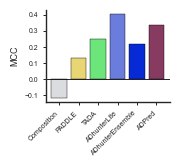

In [110]:
# ==========================================================================
#  ED3: MCC for each predictor at its standard threshold, plus the 6/6 consensus
#  F1 is printed for the record but only MCC is plotted (see notes).
# ==========================================================================
from sklearn.metrics import confusion_matrix, f1_score, matthews_corrcoef

TRUTH_COL = "Activity"
PREDICTORS = {"Composition": "Comp", "PADDLE": "PADDLE", "TADA": "TADA",
              "ADhunterLite": "ADhunterLite",
              "ADhunterEnsemble": "ADhunterEnsemble", "ADPred": "ADPred"}

rows = []
for name, col in PREDICTORS.items():
    d = exp[[TRUTH_COL, col]].dropna()
    y_true = (d[TRUTH_COL] > activethresh).astype(int).to_numpy()
    y_pred = d[col].astype(int).to_numpy()
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    rows.append({"Predictor": name, "n": len(d), "TP": tp, "FP": fp, "TN": tn,
                 "FN": fn, "F1": f1_score(y_true, y_pred, zero_division=0),
                 "MCC": matthews_corrcoef(y_true, y_pred)})

d = exp[[TRUTH_COL, '# Models Predicted']].dropna()
y_true = (d[TRUTH_COL] > activethresh).astype(int).to_numpy()
y_pred = (d['# Models Predicted'] >= 6).astype(int).to_numpy()
tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
rows.append({"Predictor": "Consensus 6/6", "n": len(d), "TP": tp, "FP": fp,
             "TN": tn, "FN": fn, "F1": f1_score(y_true, y_pred, zero_division=0),
             "MCC": matthews_corrcoef(y_true, y_pred)})

tableSX = pd.DataFrame(rows)
prev = (exp[TRUTH_COL] > activethresh).mean()
print(f"{len(exp):,} designed ADs; {prev:.1%} active at {TRUTH_COL} > {activethresh:.3f}")
print(f"'call everything active' baseline:  F1 {2 * prev / (1 + prev):.3f}  MCC 0.000\n")
print(tableSX.round(3).to_string(index=False))

# the 6/6 consensus stays in the printed table but is not plotted
_plot = tableSX[tableSX['Predictor'] != 'Consensus 6/6']
bar_colors = [models_palette_dict.get(n, '#888888') for n in PREDICTORS]
fig, ax = plt.subplots(figsize=(1.6, 1.2))
ax.bar(range(len(_plot)), _plot['MCC'], color=bar_colors,
       edgecolor='black', linewidth=0.3)
ax.axhline(0, color='black', lw=0.6)
ax.set_xticks(range(len(_plot)))
ax.set_xticklabels(_plot['Predictor'], rotation=45, ha='right')
ax.set_ylabel('MCC')
ax.tick_params(axis='both', which='major', length=2, width=0.6, color='black',
               bottom=True, left=True)
sns.despine()
plt.savefig(r"..\..\Figures_v5\ED3_MCC.pdf", format='pdf', transparent=True,
            bbox_inches='tight')
plt.show()


## Figure 5. Design and benchmarking of MADRIGAL

### Figure 5b: MADRIGAL residue-level predictions on an example sequence vs the six-predictor consensus

In [111]:
def read_parrot_preds(file):
    """
    Reads in parrot predictions and saves to df.
    Updated so that it can handle spaces in name field

    Parameters
    ----------
    file : str
        Path to predictions from CADNN
    """
    with open(file, 'r') as f:
        lines = f.readlines()

    names = []
    seqs = []
    pred_ls = []

    for line in lines:
        line = line.split()
        preds = []
        for i, e in enumerate(reversed(line)):
            try:
                e = float(e)
                preds.append(e)
            except:
                # First thing it breaks on will be sequence
                sequence = e
                first_name_index = i + 1
                break

        name = ' '.join(reversed(list(reversed(line))[first_name_index:]))
        if len(sequence) != len(preds):
            print("Something went wrong...")
        names.append(name)
        seqs.append(sequence)
        pred_ls.append(list(reversed(preds)))

    consensus_preds = pd.DataFrame({'sequence' : seqs, 'combined_preds' : pred_ls})
    return consensus_preds

test_consensus_seq = read_parrot_preds(test_seq_path)

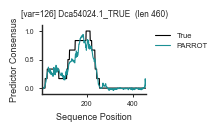

In [112]:
def get_name(line):
    toks = line.split()
    for j in range(len(toks) - 1, -1, -1):
        try:
            float(toks[j])
        except ValueError:
            return ' '.join(toks[:j])   # everything before the sequence
    return None

with open(test_seq_path) as f:
    all_names = [get_name(line) for line in f]

def plot_consensus_example(var, df=test_consensus_seq, names=None, save_path=None):
    true_row = df.iloc[2 * var]
    pred_row = df.iloc[2 * var + 1]

    true_preds = np.array(true_row['combined_preds'])
    pred_preds = np.array(pred_row['combined_preds'])
    positions = np.arange(1, len(true_preds) + 1)

    fig, ax = plt.subplots(figsize=(2.2, 1.3))
    ax.plot(positions, true_preds, color='black', lw=0.8, label='True')
    ax.plot(positions, pred_preds, color=consensus_6_palette[4], lw=0.8, label='PARROT')

    ax.set_ylim(-0.1, 1.1)
    ax.set_yticks([0, 0.5, 1])
    ax.set_xlim(1, len(positions))
    ax.set_xticks(np.arange(200, len(positions) + 1, 200))
    ax.set_xlabel('Sequence Position')
    ax.set_ylabel('Predictor Consensus')
    ax.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
    ax.legend(frameon=False, bbox_to_anchor=(1.02, 1), loc='upper left')
    if names is not None:
        ax.set_title(f"[var={var}] {names[2 * var]}  (len {len(positions)})", fontsize=6)
    sns.despine(ax=ax)
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, bbox_inches='tight', transparent=True, format='pdf')
    plt.show()


var = 126
plot_consensus_example(var,names=all_names, save_path=r"..\..\Figures_v5\Fig5b_consensus_example.pdf")


### Figure 5c: ROC and PRC for MADRIGAL and all neural network AD predictors on the full natural TF test set

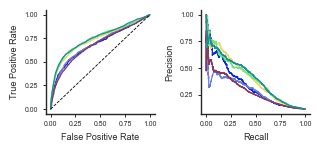

In [113]:
# 1. Map the model names to their respective dataframes
model_data = {
    'adhunter_e': adhe_roc_pr,
    'adhunter_l': adhl_roc_pr,
    'paddle': paddle_roc_pr,
    'tada': tada_roc_pr,
    'adpred': adpred_roc_pr,
    'parrot': parrot_roc_pr
}

# 2. Specify the colors for each model here. 
# You can change these to any valid matplotlib color string or hex code.
model_colors = {
    'adhunter_e': models_palette_dict['ADhunterEnsemble'],
    'adhunter_l': models_palette_dict['ADhunterLite'],
    'paddle': models_palette_dict['PADDLE'],
    'tada': models_palette_dict['TADA'],
    'adpred': models_palette_dict['ADPred'],
    'parrot': consensus_6_palette[4]
}

fig, (ax_roc, ax_prc) = plt.subplots(1, 2, figsize=(3.2, 1.5))

for model_name, df in model_data.items():
    # Direct column access ensures an error is raised if the data format is unexpected
    fpr = df[f'{model_name}_fpr']
    tpr = df[f'{model_name}_tpr']
    recalls = df[f'{model_name}_recalls']
    precisions = df[f'{model_name}_precisions']
    
    # Calculate Area Under the Curve (AUC) for the ROC plot
    roc_auc = auc(fpr, tpr)
    
    # Plot ROC
    ax_roc.plot(fpr, tpr, color=model_colors[model_name], label=f'{model_name} (AUC = {roc_auc:.3f})', linewidth=0.9)
    
    # Plot PRC
    ax_prc.plot(recalls, precisions, color=model_colors[model_name], label=model_name, linewidth=0.9)

# Configure ROC Plot
ax_roc.plot([0, 1], [0, 1], color='black', linestyle='--', linewidth=0.6) # Baseline random classifier
ax_roc.set_xlabel('False Positive Rate',fontsize=6.5)
ax_roc.set_ylabel('True Positive Rate',fontsize=6.5)
# ax_roc.set_title('Receiver Operating Characteristic (ROC)')
# ax_roc.legend(loc='lower right')

# Configure PRC Plot
ax_prc.set_xlabel('Recall',fontsize=6.5)
ax_prc.set_ylabel('Precision',fontsize=6.5)
# ax_prc.set_title('Precision-Recall Curve (PRC)')
# ax_prc.legend(loc='lower left')
ax_roc.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True,labelsize=5)
ax_prc.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True,labelsize=5)
ax_roc.xaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax_roc.yaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax_prc.xaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax_prc.yaxis.set_major_locator(ticker.MultipleLocator(0.25))

sns.despine()
plt.tight_layout()
plt.savefig(r"..\..\Figures_v5\Fig5c_ROC_PRC.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

### Figure 5d: Area under the ROC and PRC curves per dataset

In [114]:
def make_curve_df(df, score_col, activity_col, prefix, thresh):
    sub = df[[score_col, activity_col]].dropna()
    y_true = (sub[activity_col] > thresh).astype(int)
    y_score = sub[score_col]

    fpr, tpr, _ = roc_curve(y_true, y_score)
    precisions, recalls, _ = precision_recall_curve(y_true, y_score)

    # ROC and PR curves have different lengths -> pad with NaN (dropna'd later in compute_curve_auc_df)
    return pd.concat([
        pd.Series(recalls, name=f'{prefix}_recalls'),
        pd.Series(precisions, name=f'{prefix}_precisions'),
        pd.Series(fpr, name=f'{prefix}_fpr'),
        pd.Series(tpr, name=f'{prefix}_tpr'),
    ], axis=1)

# --- standard predictors ---
syn_models = {
    'adhe':   ('ADhunterEnsemble_Score', 'adhunter_e'),
    'adhl':   ('ADhunterLite_Score',          'adhunter_l'),
    'paddle': ('PADDLE_Score',            'paddle'),
    'tada':   ('TADA_Score',              'tada'),
    'adpred': ('ADPred_Score',        'adpred'),
}

# Activity
syn_adhe   = make_curve_df(exp, *syn_models['adhe'][:1],   'Activity', syn_models['adhe'][1],   activethresh)
syn_adhl   = make_curve_df(exp, *syn_models['adhl'][:1],   'Activity', syn_models['adhl'][1],   activethresh)
syn_paddle = make_curve_df(exp, *syn_models['paddle'][:1], 'Activity', syn_models['paddle'][1], activethresh)
syn_tada   = make_curve_df(exp, *syn_models['tada'][:1],   'Activity', syn_models['tada'][1],   activethresh)
syn_adpred = make_curve_df(exp, *syn_models['adpred'][:1], 'Activity', syn_models['adpred'][1], activethresh)

# Activity_GFP
syn_gfp_adhe   = make_curve_df(exp, *syn_models['adhe'][:1],   'Activity_GFP', syn_models['adhe'][1],   activethresh)
syn_gfp_adhl   = make_curve_df(exp, *syn_models['adhl'][:1],   'Activity_GFP', syn_models['adhl'][1],   activethresh)
syn_gfp_paddle = make_curve_df(exp, *syn_models['paddle'][:1], 'Activity_GFP', syn_models['paddle'][1], activethresh)
syn_gfp_tada   = make_curve_df(exp, *syn_models['tada'][:1],   'Activity_GFP', syn_models['tada'][1],   activethresh)
syn_gfp_adpred = make_curve_df(exp, *syn_models['adpred'][:1], 'Activity_GFP', syn_models['adpred'][1], activethresh)

# --- PARROT (merge onto syn by sequence) ---
madrigal_syn['AAseq_40'] = madrigal_syn['sequence_x'].str[13:]

parrot_cols = ['AAseq_40', 'parrot_max_value_all_six', 'parrot_mean_value_all_six']
syn_w_parrot = exp.merge(
    madrigal_syn[parrot_cols].drop_duplicates('AAseq_40'),
    left_on='AAseq', right_on='AAseq_40', how='left'
)
print(f"PARROT matched: {syn_w_parrot['parrot_mean_value_all_six'].notna().sum()} / {len(exp)} syn sequences")

syn_parrot_mean     = make_curve_df(syn_w_parrot, 'parrot_mean_value_all_six', 'Activity',     'parrot_mean', activethresh)
syn_parrot_max      = make_curve_df(syn_w_parrot, 'parrot_max_value_all_six',  'Activity',     'parrot_max',  activethresh)
syn_gfp_parrot_mean = make_curve_df(syn_w_parrot, 'parrot_mean_value_all_six', 'Activity_GFP', 'parrot_mean', activethresh)
syn_gfp_parrot_max  = make_curve_df(syn_w_parrot, 'parrot_max_value_all_six',  'Activity_GFP', 'parrot_max',  activethresh)

PARROT matched: 16770 / 16770 syn sequences


In [115]:
data_sources = {
    'Human (DelRosso)': {'ADHunter_E': ds_adhe, 'ADHunter_L': ds_adhl, 'PADDLE': ds_paddle, 'TADA': ds_tada, 'ADPred': ds_adpred, 'PARROT': ds_parrot},
    'Yeast (Sanborn)':  {'ADHunter_E': s_adhe,  'ADHunter_L': s_adhl,  'PADDLE': s_paddle,  'TADA': s_tada,  'ADPred': s_adpred,  'PARROT': s_parrot},
    'Plant (Morffy, ARFs)':      {'ADHunter_E': arf_adhe,'ADHunter_L': arf_adhl,'PADDLE': arf_paddle,'TADA': arf_tada,'ADPred': arf_adpred,'PARROT': arf_parrot},
    'Fly (Arnold)':   {'ADHunter_E': arnold_adhe, 'ADHunter_L': arnold_adhl, 'PADDLE': arnold_paddle, 'TADA': arnold_tada, 'ADPred': arnold_adpred, 'PARROT': arnold_parrot},
    'Designed ADs': {'ADHunter_E': syn_adhe, 'ADHunter_L': syn_adhl, 'PADDLE': syn_paddle, 'TADA': syn_tada, 'ADPred': syn_adpred, 'PARROT': syn_parrot_mean},
    'Designed ADs (GFP)': {'ADHunter_E': syn_gfp_adhe, 'ADHunter_L': syn_gfp_adhl, 'PADDLE': syn_gfp_paddle, 'TADA': syn_gfp_tada, 'ADPred': syn_gfp_adpred, 'PARROT': syn_gfp_parrot_mean},
}

# --- one color per predictor, fixed order (drop in your own list here) ---
predictor_order = ['PARROT', 'ADHunter_E', 'ADHunter_L', 'ADPred', 'TADA', 'PADDLE']
predictor_colors = [
    consensus_6_palette[4],  # PARROT
    '#082ad6',  # ADHunter_E   <- replace these six with your colors, same order
    '#6b7ddc',  # ADHunter_L
    '#873B61',  # ADPred
    '#6ce57a',  # TADA
    '#e8d574',  # PADDLE
]
color_map = dict(zip(predictor_order, predictor_colors))

dataset_order = ['Yeast (Sanborn)', 'Plant (Morffy, ARFs)', 'Human (DelRosso)', 'Fly (Arnold)', 'Designed ADs', 'Designed ADs (GFP)']


In [116]:
def compute_curve_auc_df(data_sources, x_suffix, y_suffix):
    def curve_auc_from_df(df):
        x_col = [c for c in df.columns if c.lower().endswith(x_suffix)][0]
        y_col = [c for c in df.columns if c.lower().endswith(y_suffix)][0]
        curve = df[[x_col, y_col]].dropna()
        return auc(curve[x_col], curve[y_col])

    rows = []
    for dataset_name, predictors in data_sources.items():
        for predictor_name, df in predictors.items():
            rows.append({'dataset': dataset_name, 'predictor': predictor_name, 'auc': curve_auc_from_df(df)})
    return pd.DataFrame(rows)


def plot_auc_barplot(auc_df, predictor_order, predictor_colors, dataset_order, ylabel='AUC', title=None, save_path=None):
    color_map = dict(zip(predictor_order, predictor_colors))
    sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})
    fig, ax = plt.subplots(figsize=(5.6, 0.9))

    sns.barplot(
        data=auc_df, x='dataset', order=dataset_order,
        y='auc', hue='predictor', hue_order=predictor_order,
        palette=color_map, edgecolor='white', linewidth=0.3, ax=ax,
    )

    ax.set_ylim(0, 1)
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1])

    ax.set_ylabel(ylabel)
    ax.set_xlabel('')
    if title:
        ax.set_title(title)
    ax.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
    ax.legend(title='Predictor', bbox_to_anchor=(1.02, 1), loc='upper left', frameon=False)
    sns.despine(ax=ax)
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, bbox_inches='tight', transparent=True, format='pdf')
    plt.show()
    return fig, ax

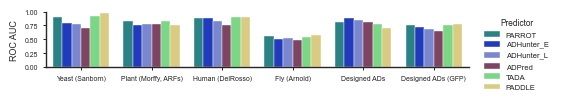

(<Figure size 560x90 with 1 Axes>, <Axes: ylabel='ROC AUC'>)

In [117]:
roc_auc_df = compute_curve_auc_df(data_sources, '_fpr', '_tpr')
plot_auc_barplot(roc_auc_df, predictor_order, predictor_colors, dataset_order, ylabel='ROC AUC',
                  save_path=r"..\..\Figures_v5\Fig5d_roc_aucs.pdf")

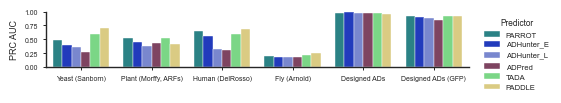

(<Figure size 560x90 with 1 Axes>, <Axes: ylabel='PRC AUC'>)

In [118]:
prc_auc_df = compute_curve_auc_df(data_sources, '_recalls', '_precisions')
plot_auc_barplot(prc_auc_df, predictor_order, predictor_colors, dataset_order, ylabel='PRC AUC',
                  save_path=r"..\..\Figures_v5\Fig5d_prc_aucs.pdf")

## Figure 6. Designed ADs activate in plant and human cells

### Figure 6b: Average activity of each sequence in yeast (GFP/mCherry and raw GFP)

In [5]:
untransfected_ic = ic[ic['Condition'] == 'Untransfected']['GFP_MFI'].mean()
untransfected_ep = ep[ep['Condition'] == 'Untransfected']['GFP_MFI'].mean()

In [6]:
yeastratio_order = ['1','2','3','4','5','6','7','8','9','10','11','12','13','14','VP16-Cterm']
yeastgfp_order = ['1','2','3','4','5','6','7','8','9','10','11','12','13','14']
plant_order = ['1','2','3','4','5','6','7','8','9','10','11','12','13','14','VP16-Cterm', '20xGS','VPR', 'VP16','noTF']
order = ['1','2','4','5','6','7','8','9','10','11','12','13','14','VP16-Cterm', '20xGS','VPR']


plant['AD_ID'] = pd.Categorical(plant['AD_ID'], categories=plant_order, ordered=True)
yeastratio14['AD_ID'] = pd.Categorical(yeastratio14['AD_ID'], categories=yeastratio_order, ordered=True)
# GFP_Yeast14byBCrep_AD_ID.csv stores AD_ID as int64 while yeastgfp_order is
# strings, so the cast has to match or every row becomes NaN.
yeastgfp14['AD_ID'] = pd.Categorical(yeastgfp14['AD_ID'].astype(str), categories=yeastgfp_order, ordered=True)

ep = ep[ep['Condition'].isin(order)]
ep.sort_values(by='Condition', key=lambda x: x.map({k: i for i, k in enumerate(order)}), inplace=True)
ic = ic[ic['Condition'].isin(order)]
ic.sort_values(by='Condition', key=lambda x: x.map({k: i for i, k in enumerate(order)}), inplace=True)

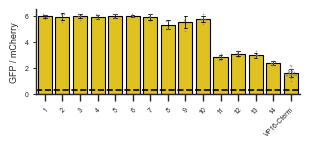

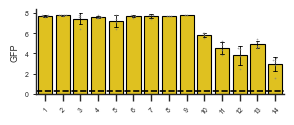

In [120]:
fig, ax = plt.subplots(figsize=(3.4,1.1))

sns.barplot(data=yeastratio14, x="AD_ID", y="GFP / mCherry", color='gold', errorbar='sd', err_kws={"color": "black", "linewidth": 0.6}, capsize=0.2, edgecolor='black', ax=ax)
sns.swarmplot(data=yeastratio14, x="AD_ID", y="GFP / mCherry", color='grey',alpha=0.7, size=1.2, ax=ax)
ax.axhline(y=activethresh,linestyle='--',color='black')
ax.set_ylabel("GFP / mCherry",fontsize=6.5)
ax.set_xlabel('')
plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor', fontsize=5)
ax.tick_params(axis='y', labelsize=5)
sns.despine()
ax.yaxis.set_major_locator(ticker.MultipleLocator(2))
plt.tick_params(axis='y', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
fig.savefig(r"..\..\Figures_v5\Fig6b_yeast_ratio.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()


fig, ax = plt.subplots(figsize=(3.2,1.1))

sns.barplot(data=yeastgfp14, x="AD_ID", y="GFP", errorbar='sd', err_kws={"color": "black", "linewidth": 0.6}, capsize=0.2, color='gold', edgecolor='black', ax=ax)
sns.swarmplot(data=yeastgfp14, x="AD_ID", y="GFP", color='grey',alpha=0.7, size=1.2, ax=ax)
ax.axhline(y=activethresh,linestyle='--',color='black')
ax.set_ylabel("GFP",fontsize=6.5)
ax.set_xlabel('')
ax.tick_params(axis='x', labelsize=5, rotation=45)
ax.tick_params(axis='y', labelsize=5)
sns.despine()
ax.yaxis.set_major_locator(ticker.MultipleLocator(2))
plt.tick_params(axis='y', which='major', length=2, width=0.6, color='black', bottom=True, left=True)
fig.savefig(r"..\..\Figures_v5\Fig6b_yeast_gfp.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

In [121]:
# ==========================================================================
#  Compare every condition against a control, and mark the figure
# ==========================================================================

def control_comparisons(df, group_col, value_col, control, agg_by=None, alpha=0.05):
    """Welch t-test of each group against `control`, Benjamini-Hochberg corrected.

    agg_by: column holding biological replicate IDs. If given, values are
    averaged within each (group, replicate) before testing, so nested
    measurements are not counted as independent observations.
    """
    cols = [group_col, value_col] + ([agg_by] if agg_by else [])
    d = df[cols].dropna()
    if agg_by:
        d = (d.groupby([group_col, agg_by], observed=True)[value_col]
               .mean().reset_index())

    ctrl = d.loc[d[group_col] == control, value_col].to_numpy()
    rows = []
    for g in d[group_col].drop_duplicates():
        if g == control or len(ctrl) < 2:
            continue
        vals = d.loc[d[group_col] == g, value_col].to_numpy()
        if len(vals) < 2:
            continue
        t, p = stats.ttest_ind(vals, ctrl, equal_var=False)
        rows.append({group_col: str(g), "n": len(vals), "mean": vals.mean(),
                     "control_mean": ctrl.mean(),
                     "diff": vals.mean() - ctrl.mean(), "t": t, "p": p})

    res = pd.DataFrame(rows)
    res["q"] = multipletests(res["p"], method="fdr_bh")[1]
    res["sig"] = res["q"] < alpha
    return res


def sig_marker(q):
    """Stars for significant comparisons, nothing otherwise."""
    return "***" if q < 1e-3 else "**" if q < 1e-2 else "*" if q < 0.05 else ""


def add_stars(ax, res, group_col, df, value_col, pad=0.03):
    """Mark significant bars, reading the category order off the axis."""
    lookup = res.set_index(group_col)["q"]
    top = df[value_col].max()
    for i, label in enumerate(t.get_text() for t in ax.get_xticklabels()):
        q = lookup.get(label)
        if q is not None and np.isfinite(q):
            ax.text(i, top * (1 + pad), sig_marker(q), ha="center", fontsize=6)
    ax.set_ylim(top=top * (1 + pad * 4))

### Figure 6d: Average activity of each sequence in plant leaves

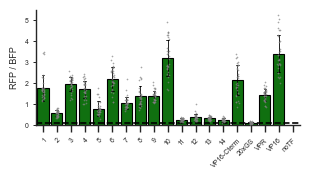

     AD_ID  n   mean  control_mean   diff       t      p      q  sig
         1  8 1.7798        0.1107 1.6691  8.1006 0.0001 0.0001 True
         2  8 0.5706        0.1107 0.4599 11.3481 0.0000 0.0000 True
         3  8 1.9477        0.1107 1.8370 22.2615 0.0000 0.0000 True
         4  8 1.7050        0.1107 1.5943 13.7476 0.0000 0.0000 True
         5  8 0.7862        0.1107 0.6754  6.1469 0.0004 0.0005 True
         6  8 2.1949        0.1107 2.0842 13.3493 0.0000 0.0000 True
         7  8 1.0552        0.1107 0.9445 12.1075 0.0000 0.0000 True
         8  8 1.3815        0.1107 1.2708  8.1884 0.0001 0.0001 True
         9  8 1.3786        0.1107 1.2679 16.0480 0.0000 0.0000 True
        10  8 3.1805        0.1107 3.0697 11.4100 0.0000 0.0000 True
        11  8 0.2633        0.1107 0.1526  7.5223 0.0000 0.0000 True
        12  8 0.3743        0.1107 0.2636  5.3411 0.0007 0.0007 True
        13  8 0.3288        0.1107 0.2181  8.3961 0.0000 0.0000 True
        14  8 0.2473        0.1107

In [122]:
fig, ax = plt.subplots(figsize=(3.4,1.5))

sns.barplot(data=plant, x="AD_ID", y="norm_RFP",errorbar='sd', err_kws={"color": "black", "linewidth": 0.6}, capsize=0.2, color='green',edgecolor='black',ax=ax)
sns.stripplot(data=plant, x="AD_ID", y="norm_RFP", color='grey',alpha=0.7, size=1.2, ax=ax)

ax.set_ylabel("RFP / BFP",fontsize=6.5)
ax.set_xlabel("")
plt.tick_params(axis='y', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor', fontsize=5)
ax.tick_params(axis='y',labelsize=5)

ax.axhline(y=plant[plant['AD_ID'] == '20xGS']['norm_RFP'].mean(),color='black',linestyle='--')
res_plant = control_comparisons(plant, "AD_ID", "norm_RFP",
                                control="20xGS", agg_by="PlantLeafCode")

sns.despine()
ax.yaxis.set_major_locator(ticker.MultipleLocator(1))
fig.savefig(r"..\..\Figures_v5\Fig6d_plant.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
print(res_plant.round(4).to_string(index=False))

### Figure 6f: Percent of cells expressing EpCAM or ICAM1

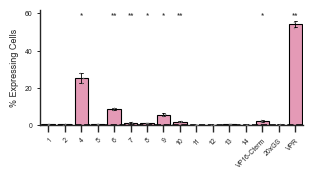

 Condition  n    mean  control_mean    diff       t      p      q   sig
         1  3  0.4779         0.236  0.2419  1.1619 0.3330 0.4541 False
         2  3  0.3499         0.236  0.1139  1.0101 0.3731 0.4664 False
         4  3 25.4207         0.236 25.1847 16.0649 0.0037 0.0112  True
         5  3  0.5165         0.236  0.2805  2.6015 0.0685 0.1027 False
         6  3  8.7045         0.236  8.4685 23.3635 0.0010 0.0048  True
         7  3  1.2228         0.236  0.9868  6.9405 0.0026 0.0099  True
         8  3  0.9601         0.236  0.7241  6.9552 0.0046 0.0115  True
         9  3  5.6469         0.236  5.4109 10.5098 0.0072 0.0142  True
        10  3  1.8558         0.236  1.6198 13.7745 0.0002 0.0024  True
        11  3  0.1611         0.236 -0.0749 -0.7430 0.5112 0.5898 False
        12  3  0.2148         0.236 -0.0212 -0.2366 0.8348 0.8348 False
        13  3  0.5789         0.236  0.3429  2.6410 0.0577 0.0961 False
        14  3  0.2645         0.236  0.0285  0.3046 0.7854 0.834

In [123]:
# ===================================
# EpCAM % Active
# ===================================
fig, ax = plt.subplots(figsize=(3.4,1.5))

sns.barplot(data=ep, x="Condition", y="Perc_GFP+",errorbar='sd', err_kws={"color": "black", "linewidth": 0.6}, capsize=0.2, color='#F08EB3',edgecolor='black',ax=ax)
sns.stripplot(data=ep, x="Condition", y="Perc_GFP+", color='grey',alpha=0.7, size=1.2, ax=ax)

ax.set_ylabel("% Expressing Cells",fontsize=6.5)
ax.set_xlabel("")
plt.tick_params(axis='y', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor', fontsize=5)
ax.tick_params(axis='y',labelsize=5)

ax.axhline(y=ep[ep['Condition'] == '20xGS']['Perc_GFP+'].mean(),color='black',linestyle='--')
res_ep = control_comparisons(ep, "Condition", "Perc_GFP+", control="20xGS")
add_stars(ax, res_ep, "Condition", ep, "Perc_GFP+")

sns.despine()
ax.yaxis.set_major_locator(ticker.MultipleLocator(20))
fig.savefig(r"..\..\Figures_v5\Fig6f_epcam_perc.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
print(res_ep.round(4).to_string(index=False))

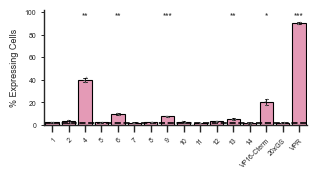

 Condition  n    mean  control_mean    diff        t      p      q   sig
         1  3  2.4372        2.0899  0.3472   1.6833 0.1943 0.2847 False
         2  3  3.2841        2.0899  1.1942   1.5918 0.2382 0.2847 False
         4  3 40.2002        2.0899 38.1103  35.9367 0.0005 0.0027  True
         5  3  2.2982        2.0899  0.2083   0.4880 0.6602 0.7074 False
         6  3  9.7039        2.0899  7.6140  13.8012 0.0020 0.0060  True
         7  3  2.0926        2.0899  0.0027   0.0115 0.9914 0.9914 False
         8  3  2.3996        2.0899  0.3097   1.6249 0.2335 0.2847 False
         9  3  7.8353        2.0899  5.7453  21.0091 0.0000 0.0002  True
        10  3  2.7454        2.0899  0.6554   1.8481 0.1528 0.2546 False
        11  3  1.7512        2.0899 -0.3387  -1.3582 0.2467 0.2847 False
        12  3  3.3935        2.0899  1.3035   3.7501 0.0270 0.0578 False
        13  3  5.4062        2.0899  3.3162   9.9028 0.0011 0.0043  True
        14  3  1.4122        2.0899 -0.6777  -3.525

In [124]:
# ===================================
# ICAM1 % Active
# ===================================
fig, ax = plt.subplots(figsize=(3.4,1.5))

sns.barplot(data=ic, x="Condition", y="Perc_GFP+",errorbar='sd', err_kws={"color": "black", "linewidth": 0.6}, capsize=0.2, color='#F08EB3',edgecolor='black',ax=ax)
sns.stripplot(data=ic, x="Condition", y="Perc_GFP+", color='grey',alpha=0.7, size=1.2, ax=ax)

ax.set_ylabel("% Expressing Cells",fontsize=6.5)
ax.set_xlabel("")
plt.tick_params(axis='y', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor', fontsize=5)
ax.tick_params(axis='y',labelsize=5)

ax.axhline(y=ic[ic['Condition'] == '20xGS']['Perc_GFP+'].mean(),color='black',linestyle='--')
ax.set_ylim(0, 100)
res_ic = control_comparisons(ic, "Condition", "Perc_GFP+", control="20xGS")
add_stars(ax, res_ic, "Condition", ic, "Perc_GFP+")

sns.despine()
ax.yaxis.set_major_locator(ticker.MultipleLocator(20))
fig.savefig(r"..\..\Figures_v5\Fig6f_icam1_perc.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
print(res_ic.round(4).to_string(index=False))

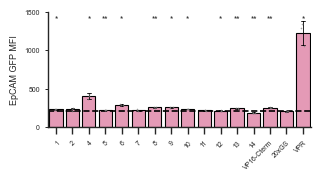

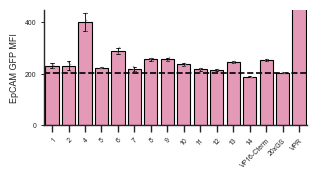

 Condition  n      mean  control_mean      diff        t      p      q   sig
         1  3  232.1416      203.4806   28.6610   5.4127 0.0294 0.0368  True
         2  3  231.9969      203.4806   28.5163   2.6005 0.1202 0.1202 False
         4  3  402.6311      203.4806  199.1504   9.7755 0.0102 0.0153  True
         5  3  224.1727      203.4806   20.6921  16.0407 0.0001 0.0016  True
         6  3  289.9850      203.4806   86.5043  12.3910 0.0059 0.0110  True
         7  3  219.4982      203.4806   16.0176   3.1440 0.0827 0.0886 False
         8  3  255.8912      203.4806   52.4106  17.5507 0.0017 0.0050  True
         9  3  256.2063      203.4806   52.7256  13.0175 0.0043 0.0108  True
        10  3  236.3979      203.4806   32.9173  10.8303 0.0051 0.0110  True
        11  3  217.8321      203.4806   14.3514   4.1220 0.0452 0.0522 False
        12  3  213.3566      203.4806    9.8759   4.4562 0.0288 0.0368  True
        13  3  245.1622      203.4806   41.6816  17.0013 0.0013 0.0049  True

In [ ]:
# ===================================
# EpCAM MFI
# ===================================
fig, ax = plt.subplots(figsize=(3.4,1.5))

sns.barplot(data=ep, x="Condition", y="GFP_MFI",errorbar='sd', err_kws={"color": "black", "linewidth": 0.6}, capsize=0.2, color='#F08EB3',edgecolor='black',ax=ax)
sns.stripplot(data=ep, x="Condition", y="GFP_MFI", color='grey',alpha=0.7, size=1.2, ax=ax)

ax.set_ylabel("EpCAM GFP MFI",fontsize=6.5)
ax.set_xlabel("")
plt.tick_params(axis='y', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor', fontsize=5)
ax.tick_params(axis='y',labelsize=5)

ax.axhline(y=ep[ep['Condition'] == '20xGS']['GFP_MFI'].mean(),color='black',linestyle='--')
res_ep_mfi = control_comparisons(ep, "Condition", "GFP_MFI", control="20xGS")
add_stars(ax, res_ep_mfi, "Condition", ep, "GFP_MFI")

sns.despine()
ax.yaxis.set_major_locator(ticker.MultipleLocator(500))
fig.savefig(r"..\..\Figures_v5\ED6_epcam_MFI.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

# ===================================
# Limit axes for better visualization
# ===================================
fig, ax = plt.subplots(figsize=(3.4,1.5))

sns.barplot(data=ep, x="Condition", y="GFP_MFI",errorbar='sd', err_kws={"color": "black", "linewidth": 0.6}, capsize=0.2, color='#F08EB3',edgecolor='black',ax=ax)
sns.stripplot(data=ep, x="Condition", y="GFP_MFI", color='grey',alpha=0.7, size=1.2, ax=ax)

ax.set_ylabel("EpCAM GFP MFI",fontsize=6.5)
ax.set_xlabel("")
plt.tick_params(axis='y', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor', fontsize=5)
ax.tick_params(axis='y',labelsize=5)

ax.axhline(y=ep[ep['Condition'] == '20xGS']['GFP_MFI'].mean(),color='black',linestyle='--')
ax.set_ylim(0,450)

sns.despine()
ax.yaxis.set_major_locator(ticker.MultipleLocator(200))
fig.savefig(r"..\..\Figures_v5\ED6_epcam_MFI_zoom.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
print(res_ep_mfi.round(4).to_string(index=False))

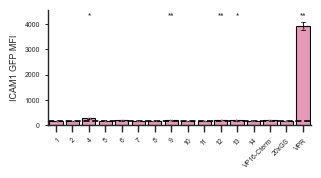

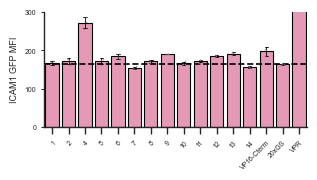

 Condition  n      mean  control_mean      diff       t      p      q   sig
         1  3  167.4551      163.0957    4.3594  1.4775 0.2576 0.2760 False
         2  3  171.0518      163.0957    7.9561  1.7426 0.2143 0.2679 False
         4  3  271.0527      163.0957  107.9570 12.4475 0.0059 0.0177  True
         5  3  171.1979      163.0957    8.1021  1.6324 0.2365 0.2729 False
         6  3  183.6596      163.0957   20.5638  5.1880 0.0284 0.0515 False
         7  3  154.0867      163.0957   -9.0090 -4.3838 0.0240 0.0515 False
         8  3  170.5478      163.0957    7.4520  3.7492 0.0343 0.0515 False
         9  3  189.9771      163.0957   26.8813 29.7140 0.0007 0.0037  True
        10  3  166.2023      163.0957    3.1066  1.2671 0.3071 0.3071 False
        11  3  171.4537      163.0957    8.3580  3.9700 0.0319 0.0515 False
        12  3  184.3130      163.0957   21.2173 12.3272 0.0007 0.0037  True
        13  3  190.7737      163.0957   27.6780 11.1522 0.0030 0.0113  True
        14  

In [ ]:
# ===================================
# ICAM1 MFI
# ===================================

fig, ax = plt.subplots(figsize=(3.4,1.5))

sns.barplot(data=ic, x="Condition", y="GFP_MFI",errorbar='sd', err_kws={"color": "black", "linewidth": 0.6}, capsize=0.2, color='#F08EB3',edgecolor='black',ax=ax)
sns.stripplot(data=ic, x="Condition", y="GFP_MFI", color='grey',alpha=0.7, size=1.2, ax=ax)

ax.set_ylabel("ICAM1 GFP MFI",fontsize=6.5)
ax.set_xlabel("")
plt.tick_params(axis='y', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor', fontsize=5)
ax.tick_params(axis='y',labelsize=5)

ax.axhline(y=ic[ic['Condition'] == '20xGS']['GFP_MFI'].mean(),color='black',linestyle='--')
res_ic_mfi = control_comparisons(ic, "Condition", "GFP_MFI", control="20xGS")
add_stars(ax, res_ic_mfi, "Condition", ic, "GFP_MFI")

sns.despine()
ax.yaxis.set_major_locator(ticker.MultipleLocator(1000))
fig.savefig(r"..\..\Figures_v5\ED6_icam1_MFI.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()

# ===================================
# Limit axes for better visualization
# ===================================
fig, ax = plt.subplots(figsize=(3.4,1.5))

sns.barplot(data=ic, x="Condition", y="GFP_MFI",errorbar='sd', err_kws={"color": "black", "linewidth": 0.6}, capsize=0.2, color='#F08EB3',edgecolor='black',ax=ax)
sns.stripplot(data=ic, x="Condition", y="GFP_MFI", color='grey',alpha=0.7, size=1.2, ax=ax)

ax.set_ylabel("ICAM1 GFP MFI",fontsize=6.5)
ax.set_xlabel("")
plt.tick_params(axis='y', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

plt.setp(ax.get_xticklabels(), rotation=45, ha='right', rotation_mode='anchor', fontsize=5)
ax.tick_params(axis='y',labelsize=5)

ax.axhline(y=ic[ic['Condition'] == '20xGS']['GFP_MFI'].mean(),color='black',linestyle='--')
ax.set_ylim(0,300)

sns.despine()
ax.yaxis.set_major_locator(ticker.MultipleLocator(100))
fig.savefig(r"..\..\Figures_v5\ED6_icam1_MFI_zoom.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()
print(res_ic_mfi.round(4).to_string(index=False))

In [7]:
print('FC #4 vs untransfected ICAM1', ic[ic['Condition'] == '4']['GFP_MFI'].mean() / untransfected_ic)
print('FC #4 vs untransfected EpCAM', ep[ep['Condition'] == '4']['GFP_MFI'].mean() / untransfected_ep)

print('FC VPR vs untransfected ICAM1', ic[ic['Condition'] == 'VPR']['GFP_MFI'].mean() / untransfected_ic)
print('FC VPR vs untransfected EpCAM', ep[ep['Condition'] == 'VPR']['GFP_MFI'].mean() / untransfected_ep)

FC #4 vs untransfected ICAM1 2.3599186742154115
FC #4 vs untransfected EpCAM 2.866656017566597
FC VPR vs untransfected ICAM1 34.01252337726612
FC VPR vs untransfected EpCAM 8.727462695225906


### ED7: Increasingly acidic composition of natural ADs predicted by stringent predictor thresholds

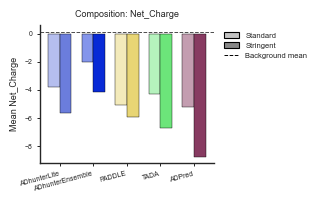

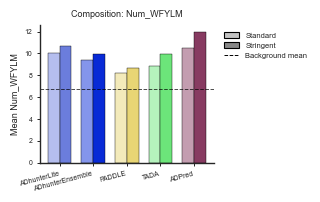

In [ ]:
comp_vars = ['Net_Charge', 'Num_WFYLM']

# CSV "Model" values -> the key in models_palette_dict they should be colored by
model_display = {
    'adhunter': 'ADhunterLite',
    'adhunter_ensemble': 'ADhunterEnsemble',
    'adpred_10core': 'ADPred',
    'adpred_40core': 'ADPred',
    'paddle': 'PADDLE',
    'tada': 'TADA',
}

# Within a predictor group, which row is the "standard/lighter" bar (rank 0)
# vs the "stringent/darker" bar (rank 1). adhunter/paddle/tada/ensemble are
# ranked by their (lower, higher) Threshold; adpred is ranked by core size
# since both rows share Threshold=0.8.
pair_rank_override = {'adpred_10core': 0, 'adpred_40core': 1}

group_order = ['ADhunterLite', 'ADhunterEnsemble', 'PADDLE', 'TADA', 'ADPred']


def lighten_color(hex_color, amount=0.5):
    """Blend hex_color toward white by `amount` (0 = unchanged, 1 = white)."""
    rgb = np.array(to_rgb(hex_color))
    return tuple(rgb + (np.array([1.0, 1.0, 1.0]) - rgb) * amount)


def plot_composition_barplot(comp_var, save_path=None):
    df = pd.read_csv(rf"..\data\comp_summary_stats_{comp_var}.csv")

    bg_row = df[df['Model'] == 'Background'].iloc[0]
    background_mean, background_n = bg_row['mean'], int(bg_row['count'])

    df = df[df['Model'] != 'Background'].copy()
    df['Display'] = df['Model'].map(model_display)
    df['pair_rank'] = df.apply(
        lambda row: pair_rank_override.get(row['Model'], row['Threshold']), axis=1
    )
    df = df.sort_values(['Display', 'pair_rank'])

    fig, ax = plt.subplots(figsize=(3.2, 2.0))
    bar_width = 0.35

    for gi, group in enumerate(group_order):
        sub = df[df['Display'] == group].reset_index(drop=True)
        base_color = models_palette_dict[group]
        n = len(sub)
        for j, (_, row) in enumerate(sub.iterrows()):
            offset = (j - (n - 1) / 2) * bar_width
            color = lighten_color(base_color, amount=0.5) if j == 0 else base_color
            ax.bar(gi + offset, row['mean'], width=bar_width, color=color,
                   edgecolor='black', linewidth=0.3)

    ax.axhline(background_mean, color='black', linestyle='--', linewidth=0.7, alpha=0.7)

    ax.set_xticks(range(len(group_order)))
    ax.set_xticklabels(group_order, rotation=15, ha='right')
    ax.set_ylabel(f'Mean {comp_var}')
    ax.set_title(f'Composition: {comp_var}')
    ax.tick_params(axis='both', which='major', length=2, width=0.6, color='black', bottom=True, left=True)

    legend_elements = [
        Patch(facecolor=lighten_color('#888888', 0.5), edgecolor='black', label='Standard'),
        Patch(facecolor='#888888', edgecolor='black', label='Stringent'),
        Line2D([0], [0], color='black', linestyle='--', linewidth=0.7,
               label=f'Background mean'),
    ]
    ax.legend(handles=legend_elements, loc='upper left', bbox_to_anchor=(1.02, 1), frameon=False)

    sns.despine(ax=ax)
    plt.tight_layout()
    if save_path is not None:
        fig.savefig(save_path, bbox_inches='tight', transparent=True)
    plt.show()
    return fig, ax


for comp_var in comp_vars:
    plot_composition_barplot(
        comp_var,
        save_path=rf"..\..\Figures_v5\ED7_comp_{comp_var}.pdf")


### NOT IN SUBMISSION — Predictors evaluated on GFP

In [128]:
comp_truepos_gfp =(exp[(exp['Comp'] == 1) & (exp['Activity_GFP'] > activethresh)].shape[0]) / exp[exp['Activity_GFP'] > activethresh].shape[0]
comp_falsepos_gfp =(exp[(exp['Comp'] == 1) & (exp['Activity_GFP'] < activethresh)].shape[0]) / exp[exp['Activity_GFP'] < activethresh].shape[0]
comp_precision_gfp = (exp[(exp['Comp'] == 1) & (exp['Activity_GFP'] > activethresh)].shape[0]) / exp[exp['Comp'] == 1].shape[0]
print(comp_truepos_gfp, comp_falsepos_gfp, comp_precision_gfp)
adpred_truepos_gfp =(exp[(exp['ADPred'] == 1) & (exp['Activity_GFP'] > activethresh)].shape[0]) / exp[exp['Activity_GFP'] > activethresh].shape[0]
adpred_falsepos_gfp =(exp[(exp['ADPred'] == 1) & (exp['Activity_GFP'] < activethresh)].shape[0]) / exp[exp['Activity_GFP'] < activethresh].shape[0]
adpred_precision_gfp = (exp[(exp['ADPred'] == 1) & (exp['Activity_GFP'] > activethresh)].shape[0]) / exp[exp['ADPred'] == 1].shape[0]
print(adpred_truepos_gfp, adpred_falsepos_gfp, adpred_precision_gfp)

0.5933185874456564 0.5891940839118623 0.7832259363672976
0.9082449851269926 0.6821611832176275 0.8231146747770789


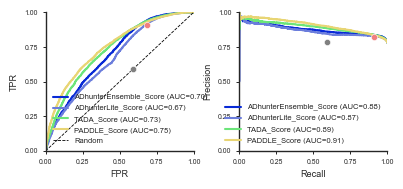

In [129]:
sns.set_style("white", {"axes.grid": False, "xtick.bottom": True, "ytick.left": True})

fig, (ax1, ax2) = plot_roc_prc(
    exp,
    truth_col='Activity_GFP',
    model_cols=['ADhunterEnsemble_Score', 'ADhunterLite_Score', 'TADA_Score', 'PADDLE_Score'],
    true_threshold=activethresh,
    mark_thresholds={
        # 'ADHunter Ensemble Score': [0.4441],
        # 'ADHunter Score': [100000, 150000],
        # 'TADA Score': [0.4, 0.6],
        # 'PADDLE Score': [4, 6],
        # 'ADPred Score (ave)': [0.8]
    },
    dot_colors={
        # 'ADHunter Score': ['lightblue', 'darkblue'],
        # 'TADA Score': ['lightgreen', 'darkgreen'],
        # 'PADDLE Score': ["#E6E22A", "#7A6507"],
        # 'ADHunter Ensemble Score': ["#04125f"]
        # 'ADPred Score (ave)': 'purple'
    },
    line_width=1.5,
    dot_size=20,
    # dot_marker='s',  # squares instead of circles
    dot_edgecolor='white',
    dot_edgewidth=0.4,
    model_colors={
        'ADhunterLite_Score': models_palette_dict['ADhunterLite'], 
        'TADA_Score': models_palette_dict['TADA'],
        'PADDLE_Score': models_palette_dict['PADDLE'],
        # 'ADPred Score (ave)': models_palette_dict['ADPred'],
        'ADhunterEnsemble_Score': models_palette_dict['ADhunterEnsemble']
    },
    figsize=(4.0, 2.0)
)
ax1.legend()
ax2.legend(loc='lower right')
ax1.yaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax1.xaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax2.yaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax2.xaxis.set_major_locator(ticker.MultipleLocator(0.25))
ax1.set_xlabel('FPR',fontsize=6.5)
ax1.set_ylabel('TPR', fontsize=6.5)
ax1.tick_params(axis='x',labelsize=5)
ax1.tick_params(axis='y', labelsize=5)
ax2.set_xlabel('Recall', fontsize=6.5)
ax2.set_ylabel('Precision', fontsize=6.5)
ax2.tick_params(axis='x',labelsize=5)
ax2.tick_params(axis='y',labelsize=5)
ax1.set_title('')
ax2.set_title('')

ax1.scatter(comp_falsepos_gfp, comp_truepos_gfp, s=20, color="grey", edgecolor="white", linewidth=0.4, zorder=10)
ax2.scatter(comp_truepos_gfp, comp_precision_gfp, s=20, color="grey", edgecolor="white", linewidth=0.4, zorder=10)
ax1.scatter(adpred_falsepos_gfp, adpred_truepos_gfp, s=20, color="lightcoral", edgecolor="white", linewidth=0.4, zorder=10)
ax2.scatter(adpred_truepos_gfp, adpred_precision_gfp, s=20, color="lightcoral", edgecolor="white", linewidth=0.4, zorder=10)
sns.despine()
plt.savefig(r"..\..\Figures_v5\NOTINCLUDED_S14_ROC_PRC_GFP.pdf", format='pdf', transparent=True, bbox_inches='tight')
plt.show()